# Load packages

Read in all necessary packages:

In [5]:
from IPython.display import display, HTML
display(HTML("<style>.container { width:90% !important; }</style>"))
%matplotlib inline

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import scanpy as sc
import numpy as np
import decoupler as dc

plt.set_loglevel('WARNING') 

In [2]:
import decoupler as dc

In [3]:
sc.set_figure_params(dpi = 80)
sns.set_style("white")
sns.set_context("talk")
sns.set_style("ticks")

# Load the dataset

## load adata file and define groups for differential expression

In [4]:
adata = sc.read_h5ad('../../../tchic_local/fig6_build/legacy/data/20230704_adata_all.h5ad')
adata

AnnData object with n_obs × n_vars = 38117 × 27384
    obs: 'batch', 'day', 'replicates', 'mark', 'day_rep', 'dataset', 'hour', 'celltype', 'celltype_general', 'lineage', 'lin_day', 'percent_mito', 'n_counts', 'n_counts_proteincoding', 'n_genes', 'S_score', 'G2M_score', 'phase', 'enrichment', 'coverage', 'QC', 'pseudotime', 'pseudotime2'
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'gene', 'gene_biotype', 'gene_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'QC_colors', 'batch_colors', 'celltype_colors', 'celltype_general_colors', 'dataset_colors', 'day_colors', 'hour_colors', 'hvg', 'leiden', 'leiden_colors', 'lin_day_colors', 'lineage_colors', 'log1p', 'mark_colors', 'neighbors', 'old_celltype_colors', 'old_leiden_general_colors', 'old_leiden_merge_colors', 'pca', 'phase_colors', 'predicted_final_colors', 'predicted_id_E75_colors', 'predicted_id_E85_colors', 'replicates_colors', 'umap', 'umap_density_mark_par

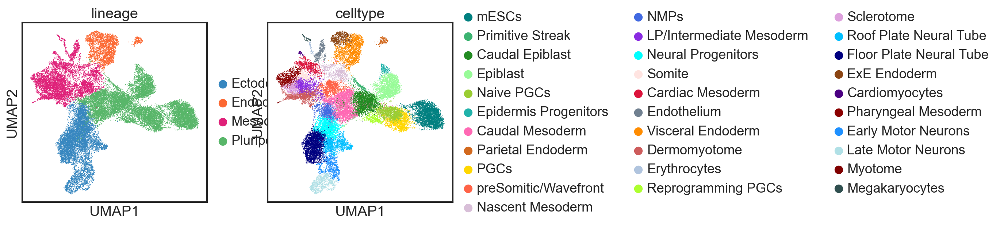

In [6]:
sc.pl.umap(adata, color = ['lineage', 'celltype'])

In [7]:
sc.settings.verbosity = 2

## load the tables with differentially expressed genes

In [8]:
PvsDIFF = pd.read_csv('dfs/20250310_diff_genes_PvsDIFF.csv')
ESCvsP = pd.read_csv('dfs/20250310_diff_genes_ESCvsP.csv')
PvsECT = pd.read_csv('dfs/20250310_diff_genes_PvsECT.csv')
PvsEND = pd.read_csv('dfs/20250310_diff_genes_PvsEND.csv')
PvsMES = pd.read_csv('dfs/20250310_diff_genes_PvsMES.csv')

In [9]:
def up_down_genes(results_df):
    up = results_df[(results_df['padj'] < 0.05) & (results_df['log2FoldChange'] > 2)].sort_values(by = 'log2FoldChange',ascending=True)
    down = results_df[(results_df['padj'] < 0.05) & (results_df['log2FoldChange'] < -2)].sort_values(by = 'log2FoldChange',ascending=True)
    return up,down


In [10]:
PvsDIFF_up, PvsDIFF_down = up_down_genes(PvsDIFF)
ESCvsP_up, ESCvsP_down = up_down_genes(ESCvsP)
PvsECT_up, PvsECT_down = up_down_genes(PvsECT)
PvsEND_up, PvsEND_down = up_down_genes(PvsEND)
PvsMES_up, PvsMES_down = up_down_genes(PvsMES)

# Plotting gene sets

## venn diagrams: check intersect between genesets

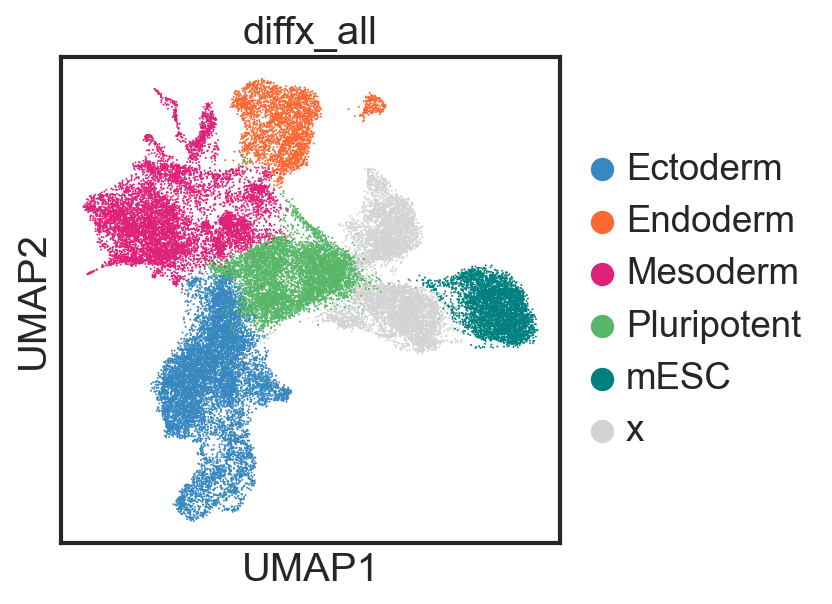

In [11]:
dict_ct = {'Mesoderm':'Mesoderm',
 'Ectoderm':'Ectoderm',
 'Endoderm':'Endoderm',
           'Pluripotent':'Pluripotent'}

adata.obs['diffx_all'] = (
    adata.obs["lineage"]
    .map(lambda x: dict_ct.get(x, x))
    .astype("category")
)

adata.obs['diffx_all'] = adata.obs['diffx_all'].astype(str)
adata.obs.loc[list(adata[adata.obs['celltype'] == 'mESCs'].obs.index), 'diffx_all'] = 'mESC'
adata.obs.loc[list(adata[adata.obs['celltype_general'] == 'PGCs'].obs.index), 'diffx_all'] = 'x'
adata.obs.loc[list(adata[adata.obs['celltype_general'] == 'Epidermis Progenitors'].obs.index), 'diffx_all'] = 'x'
adata.obs.loc[list(adata[adata.obs['celltype_general'] == 'Epiblast'].obs.index), 'diffx_all'] = 'x'

cols = ['#3787c0', '#fc6832','#df2179', '#58b669','teal','lightgrey']
sc.pl.umap(adata, color = 'diffx_all', palette = cols )
color_pal = dict(zip(adata.obs['diffx_all'].cat.categories,adata.uns[str('diffx_all') + '_colors']))


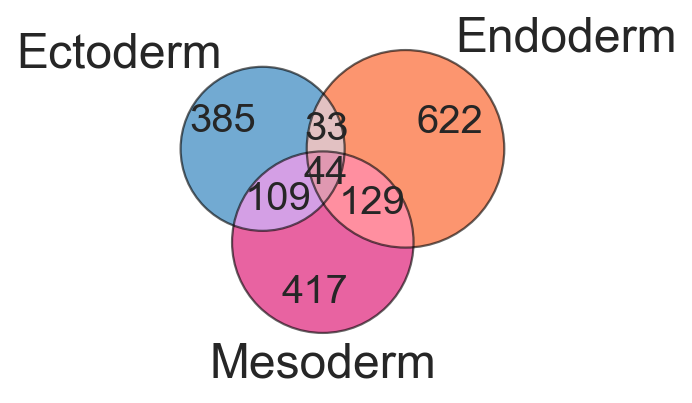

In [12]:
from matplotlib_venn import venn3, venn3_circles

A = PvsECT_up['Gene']
B = PvsEND_up['Gene']
C = PvsMES_up['Gene']

fig,ax = plt.subplots(figsize = (3,3))
venn3([set(A),set(B),set(C)],ax=ax, set_colors = list(color_pal.values())[0:3],set_labels = list(color_pal.keys())[0:3],
      alpha = 0.7)
c = venn3_circles([set(A),set(B),set(C)],color = 'black',linewidth = 1,ax=ax, 
      alpha = 0.6)

#plt.savefig('figs/20250305_venn_overlap_lineages_up.png',bbox_inches='tight')
plt.show()

In [13]:
sc.set_figure_params(dpi = 80)

sns.set_style("white")
sns.set_context("talk")
sns.set_style("ticks")

In [14]:
cols[0]

'#3787c0'

# Take only unique differentially expressed genes

For the lineages, we take the "up" fraction - these are upregulated in lin vs pluripotent. \
For pluripotency, we take the "down" fraction in p vs diff - these are downregulated in the lineages compared to pluripotency, i.e. they are up in pluripotency. \
For ESCs, we take the "down" fraction in ESC vs p - these are donwregulated in ESCs compared to P. The "up" fraction is differentially expresssed in pluripotent compared to ESCs.

In [15]:
ecto = PvsECT_up[~PvsECT_up['Gene'].isin(list(PvsEND_up['Gene']) + list(PvsMES_up['Gene']))]
meso = PvsMES_up[~PvsMES_up['Gene'].isin(list(PvsEND_up['Gene']) + list(PvsECT_up['Gene']))]
endo = PvsEND_up[~PvsEND_up['Gene'].isin(list(PvsECT_up['Gene']) + list(PvsMES_up['Gene']))]
pluri = PvsDIFF_down

In [16]:
metadata = pd.read_csv('../../../tchic_local/fig6_build/dfs/20250215_metadata.tsv', index_col = 0, header = 0, low_memory= False, sep = '\t')

In [17]:
metadata.head(2)

,step,PT,UMAP1,UMAP2,lin,RT,lin2,RT_m,step_id
1,1,0.372537,11.126464,4.599585,ect1,mESCs,Pluripotent mESCs,0.0,1:ect1
2,2,0.463342,11.385221,4.509028,ect1,mESCs,Pluripotent mESCs,0.0,2:ect1


In [18]:
pwd

'/Users/mbloten1/Library/CloudStorage/OneDrive-UniversitédeLausanne/Documents/jupyter_default/2025/tchic_figures/fig6/diff_gene_analysis'

In [19]:
count_table = pd.read_csv('../../../tchic_local/fig6_build/dfs/20250304_count_data_all_thresh_min.tsv', sep = '\t', index_col = 0)

In [20]:
count_table.index = count_table['gene']
count_table.head(2)

,gene,step,layer,counts,lin,sm_short,counts_log2,sm_short_log2,sm_short_state_fix,sm_short_state_dyn
gene,,,,,,,,,,
Xkr4,Xkr4,1,RNA,0.25,ect1,0.284,-1.943416,-1.766112,1.0,0.0
Rp1,Rp1,1,RNA,0.23,ect1,0.278,-2.058894,-1.795859,1.0,1.0


In [21]:
d_rna = {}
d_k4 = {}
d_k27 = {}
df_rna = count_table[count_table['layer'] == 'RNA']
df_k4 = count_table[count_table['layer'] == 'K4']
df_k27 = count_table[count_table['layer'] == 'K27']

df_rna = df_rna.drop('gene',axis=1)
df_k4 = df_k4.drop('gene',axis=1)
df_k27 = df_k27.drop('gene',axis=1)

In [22]:
df_rna['p_99'] = df_rna['sm_short']/np.percentile(df_rna['sm_short'],99)
df_k4['p_99'] = df_k4['sm_short']/np.percentile(df_k4['sm_short'],99)
df_k27['p_99'] = df_k27['sm_short']/np.percentile(df_k27['sm_short'],99)

df_rna['p_98'] = df_rna['sm_short']/np.percentile(df_rna['sm_short'],98)
df_k4['p_98'] = df_k4['sm_short']/np.percentile(df_k4['sm_short'],98)
df_k27['p_98'] = df_k27['sm_short']/np.percentile(df_k27['sm_short'],98)

df_rna['p_95'] = df_rna['sm_short']/np.percentile(df_rna['sm_short'],95)
df_k4['p_95'] = df_k4['sm_short']/np.percentile(df_k4['sm_short'],95)
df_k27['p_95'] = df_k27['sm_short']/np.percentile(df_k27['sm_short'],95)

In [23]:
ct_normalised = pd.concat([df_rna,df_k4,df_k27])

In [24]:
ct_normalised.head(2)

,step,layer,counts,lin,sm_short,counts_log2,sm_short_log2,sm_short_state_fix,sm_short_state_dyn,p_99,p_98,p_95
gene,,,,,,,,,,,,
Xkr4,1,RNA,0.25,ect1,0.284,-1.943416,-1.766112,1.0,0.0,0.047819,0.069934,0.125110
Rp1,1,RNA,0.23,ect1,0.278,-2.058894,-1.795859,1.0,1.0,0.046809,0.068456,0.122467


In [25]:
ct_normalised['p98_log2'] = np.log2(ct_normalised['p_98']+1)
ct_normalised['p98_log10'] = np.log10(ct_normalised['p_98']+1)

ct_normalised['step_id'] = ct_normalised['step'].astype(str) + str(':') + ct_normalised['lin']
metadata['step_id'] = metadata['step'].astype(str) + str(':') + metadata['lin']
steps_to_RT = metadata[['step_id','RT']].set_index('step_id').to_dict()['RT']
ct_normalised['RT'] = ct_normalised['step_id'].map(steps_to_RT)
ct_normalised['RT'] = ct_normalised['RT'].astype('category')
ct_normalised['RT'] = ct_normalised['RT'].cat.reorder_categories(['mESCs','Gastd3', 'Gastd4', 'Gastd5', 'Gastd6', 'Gastd7'])
ct_normalised['lin_layer'] = ct_normalised['lin'].astype(str) + str('_') + ct_normalised['layer'].astype(str)


In [26]:
ct_normalised.head(2)

,step,layer,counts,lin,sm_short,counts_log2,sm_short_log2,sm_short_state_fix,sm_short_state_dyn,p_99,p_98,p_95,p98_log2,p98_log10,step_id,RT,lin_layer
gene,,,,,,,,,,,,,,,,,
Xkr4,1,RNA,0.25,ect1,0.284,-1.943416,-1.766112,1.0,0.0,0.047819,0.069934,0.125110,0.097521,0.029357,1:ect1,mESCs,ect1_RNA
Rp1,1,RNA,0.23,ect1,0.278,-2.058894,-1.795859,1.0,1.0,0.046809,0.068456,0.122467,0.095528,0.028757,1:ect1,mESCs,ect1_RNA


In [27]:
to_plot1 = ct_normalised.loc[list(set(endo['Gene']) & set(ct_normalised.index))]
to_plot2 = ct_normalised.loc[list(set(meso['Gene']) & set(ct_normalised.index))]
to_plot3 = ct_normalised.loc[list(set(ecto['Gene']) & set(ct_normalised.index))]
to_plot4 = ct_normalised.loc[list(set(pluri['Gene']) & set(ct_normalised.index))]

In [28]:
lin_colors = {'Ectoderm':'#3787C0', 'Endoderm':'#FC6832', 'Mesoderm':'#DF2179'}
Green='#238b45'
Purple='#6a51a3'
Orange='#d94801'

lightOrange = '#f59c71'
lightGreen = '#90f5b1'
lightPurple = '#b698fa'

# identify state changes

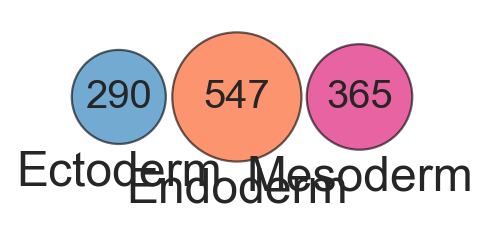

In [29]:
# sanity check
from matplotlib_venn import venn3, venn3_circles

A = to_plot3.index.unique()
B = to_plot1.index.unique()
C = to_plot2.index.unique()

fig,ax = plt.subplots(figsize = (3,3))
venn3([set(A),set(B),set(C)],ax=ax, set_colors = list(color_pal.values())[0:3],set_labels = list(color_pal.keys())[0:3],
      alpha = 0.7)
c = venn3_circles([set(A),set(B),set(C)],color = 'black',linewidth = 1,ax=ax, 
      alpha = 0.6)

#plt.savefig('figs/20250305_venn_overlap_lineages_up.png',bbox_inches='tight')
plt.show()

In [30]:
def findStateChanges(df, state = 'sm_short_state_dyn', val = 'sm_short'):
    df = df.reset_index().set_index(['step','gene','layer','lin'])
    df2 = df.copy()
    idx =df2.reset_index()['step']+1
    df2 = df2.reset_index().set_index([idx,'gene','layer','lin'])

    #add change
    df['change'] = df[state] - df2[state]
    #add val change compared to step-1
    df['val_change'] = df[val] - df2[val]
    #add val change compared to step 1

    #extract the number of steps per trajectory
    dict1 = {}
    for x in df2['lin_layer'].unique():
        dict1[x] = df2[df2['lin_layer'] == x]['step'].max()
    #take all values for step 1
    steps_1 = df2[df2['step'] == 1][[val,'lin_layer']]
    # add total n steps per trajectory 
    steps_1['counts'] = steps_1['lin_layer'].replace(dict1)

    # multiply step 1 by length of trajectory
    all_steps_1 = []
    for num in range(steps_1.shape[0]):
        all_steps_1.extend([steps_1[val].iloc[num]]* steps_1['counts'].iloc[num])

    # add all step 1s as a column
    df['steps1'] = all_steps_1
    #substract value of step n from value of step 1
    df['total_change'] = df['steps1'] - df[val]
    
    return df[df['change'] != 0].dropna().reset_index()

    

In [31]:
end_changes = findStateChanges(to_plot1.drop(['p_99','p_98', 'p_95', 'p98_log2', 'p98_log10', 'step_id'], axis = 1),state = 'sm_short_state_dyn')
end_changes.head(2)

/var/folders/_k/c0bkq2m10c5f4h7vq_0xfm_40000gn/T/ipykernel_73249/731907501.py:20: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  steps_1['counts'] = steps_1['lin_layer'].replace(dict1)


,step,gene,layer,lin,counts,sm_short,counts_log2,sm_short_log2,sm_short_state_fix,sm_short_state_dyn,RT,lin_layer,change,val_change,steps1,total_change
0,22,Irak2,RNA,ect1,0.09,0.084,-3.321928,-3.411195,1.0,1.0,mESCs,ect1_RNA,1.0,0.004,0.062,-0.022
1,27,Irak2,RNA,ect1,0.08,0.081,-3.473931,-3.457990,1.0,0.0,mESCs,ect1_RNA,-1.0,-0.006,0.062,-0.019


In [32]:
mes_changes = findStateChanges(to_plot2.drop(['p_99','p_98', 'p_95', 'p98_log2', 'p98_log10', 'step_id'], axis = 1),state = 'sm_short_state_dyn')
mes_changes.head(2)

/var/folders/_k/c0bkq2m10c5f4h7vq_0xfm_40000gn/T/ipykernel_73249/731907501.py:20: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  steps_1['counts'] = steps_1['lin_layer'].replace(dict1)


,step,gene,layer,lin,counts,sm_short,counts_log2,sm_short_log2,sm_short_state_fix,sm_short_state_dyn,RT,lin_layer,change,val_change,steps1,total_change
0,50,Minar2,RNA,ect1,0.0,0.008,-6.643856,-5.795859,0.0,1.0,Gastd3,ect1_RNA,1.0,0.005,0.002,-0.006
1,51,Minar2,RNA,ect1,0.0,0.007,-6.643856,-5.878321,0.0,0.0,Gastd3,ect1_RNA,-1.0,-0.001,0.002,-0.005


In [33]:
ect_changes = findStateChanges(to_plot3.drop(['p_99','p_98', 'p_95', 'p98_log2', 'p98_log10', 'step_id'], axis = 1),state = 'sm_short_state_dyn')
ect_changes.head(2)

/var/folders/_k/c0bkq2m10c5f4h7vq_0xfm_40000gn/T/ipykernel_73249/731907501.py:20: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  steps_1['counts'] = steps_1['lin_layer'].replace(dict1)


,step,gene,layer,lin,counts,sm_short,counts_log2,sm_short_log2,sm_short_state_fix,sm_short_state_dyn,RT,lin_layer,change,val_change,steps1,total_change
0,132,Lmx1a,RNA,ect2,1.98,3.790000,0.992768,1.925999,1.0,1.0,Gastd5,ect2_RNA,1.0,0.757,0.102,-3.688000
1,129,Lmx1a,K4,ect2,0.06,0.149333,-3.836501,-2.649880,1.0,1.0,Gastd5,ect2_K4,1.0,0.028,0.115,-0.034333


In [34]:
p_changes = findStateChanges(to_plot4.drop(['p_99','p_98', 'p_95', 'p98_log2', 'p98_log10', 'step_id'], axis = 1),state = 'sm_short_state_dyn')
p_changes.head(2)

/var/folders/_k/c0bkq2m10c5f4h7vq_0xfm_40000gn/T/ipykernel_73249/731907501.py:20: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  steps_1['counts'] = steps_1['lin_layer'].replace(dict1)


,step,gene,layer,lin,counts,sm_short,counts_log2,sm_short_log2,sm_short_state_fix,sm_short_state_dyn,RT,lin_layer,change,val_change,steps1,total_change
0,74,Ddx4,RNA,ect1,0.06,0.04,-3.836501,-4.321928,1.0,0.0,Gastd4,ect1_RNA,-1.0,-0.003,0.126,0.086
1,74,Ddx4,RNA,ect2,0.06,0.04,-3.836501,-4.321928,1.0,0.0,Gastd4,ect2_RNA,-1.0,-0.003,0.126,0.086


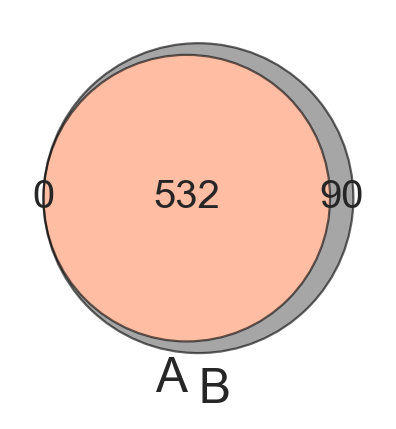

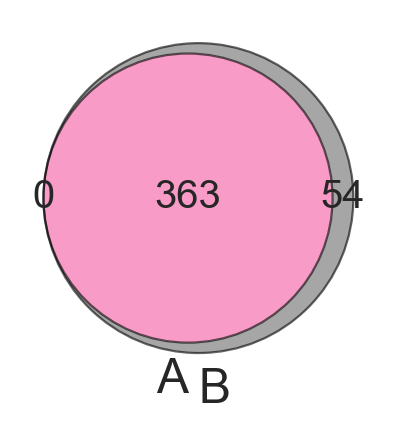

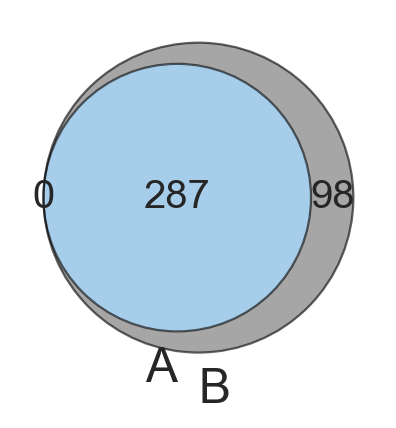

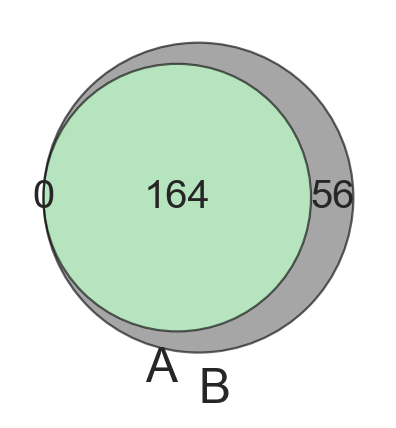

In [35]:
# sanity check
from matplotlib_venn import venn2, venn2_circles

lists = [[end_changes['gene'].unique(), endo['Gene'].unique()], 
         [mes_changes['gene'].unique(), meso['Gene'].unique()],
         [ect_changes['gene'].unique(), ecto['Gene'].unique()],
         [p_changes['gene'].unique(), pluri['Gene'].unique()],
        ]
cols = ['#fc6832','#df2179','#3787c0','#58b669']

for num,sets in enumerate(lists):
    fig,ax = plt.subplots(figsize = (3,3))
    venn2([set(sets[0]),set(sets[1])],ax=ax, set_colors = [cols[num],'grey'],
          alpha = 0.7)
    c = venn2_circles([set(sets[0]),set(sets[1])],color = 'black',linewidth = 1,ax=ax, 
          alpha = 0.6)
    plt.show()

In [36]:
def plotRNAvsK27(df, lin = 'ect1', col = 'Ectoderm', keep = False,save = None):
    df['dup'] = df['lin_layer'] + '_' + df['gene']
    df_unique = df[~df['dup'].duplicated(keep = keep)]
    k27 = df_unique[(df_unique['layer'] == 'K27') & (df_unique['lin'] == lin)][['gene','step']].set_index(['gene']).rename(columns={'step':'k27'})
    rna = df_unique[(df_unique['layer'] == 'RNA') & (df_unique['lin'] == lin)][['gene','step']].set_index(['gene']).rename(columns={'step':'rna'})

    plt.axline((1, 1), slope=1, linestyle = 'dashed', c = 'black')
    #extract the number of steps per trajectory
    dict1 = {}
    for x in df['lin_layer'].unique():
        dict1[x] = df[df['lin_layer'] == x]['step'].max()
        
    sns.scatterplot(data = rna.join(k27, how = 'inner'),
                    x = 'rna',
                    y = 'k27', s = 40, alpha = 0.7,zorder = 1,
                   color = color_pal[col])
    plt.xlim([0,dict1[lin+'_RNA']+5])
    plt.ylim([0,dict1[lin+'_RNA']+5])
    plt.title(lin)
    if save != None:
        plt.savefig(save, bbox_inches = 'tight')
    plt.show()
    

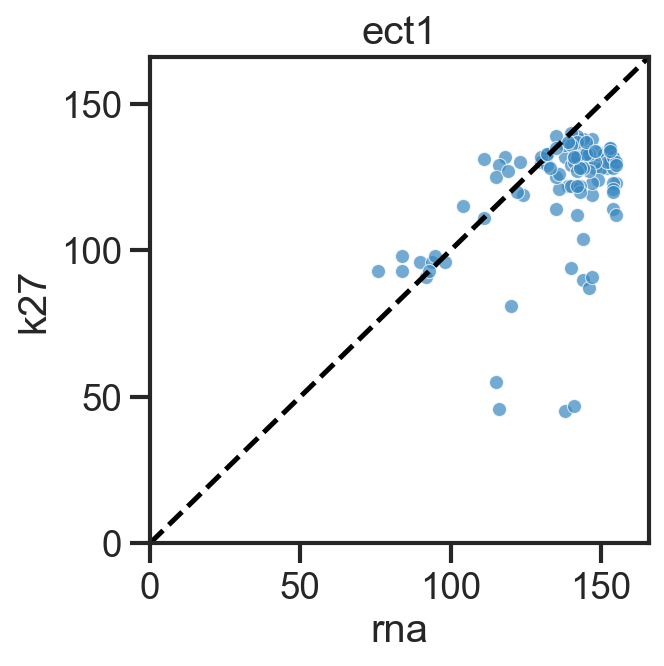

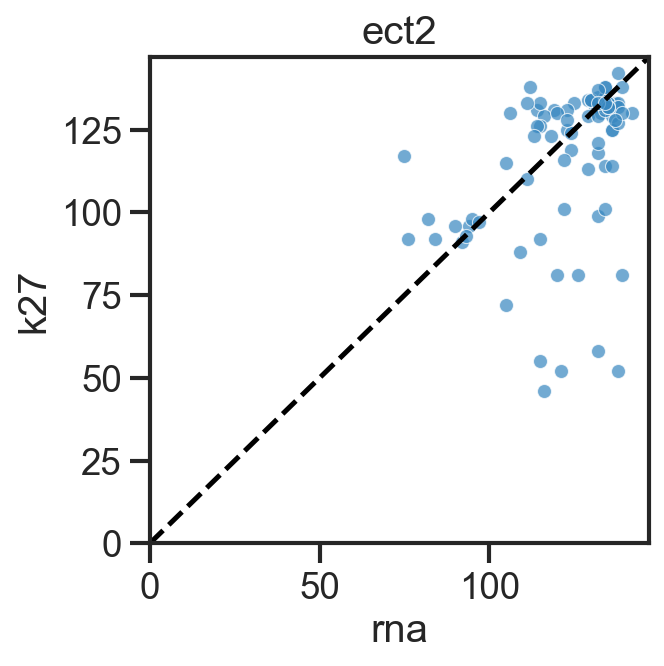

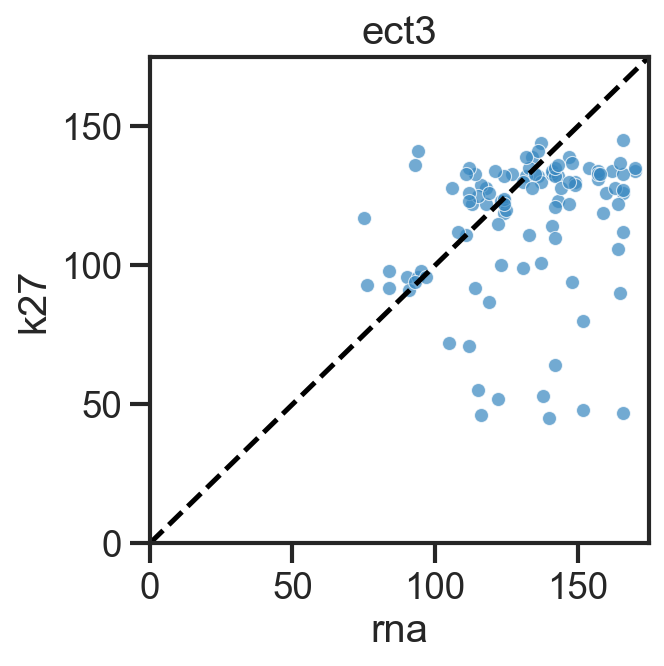

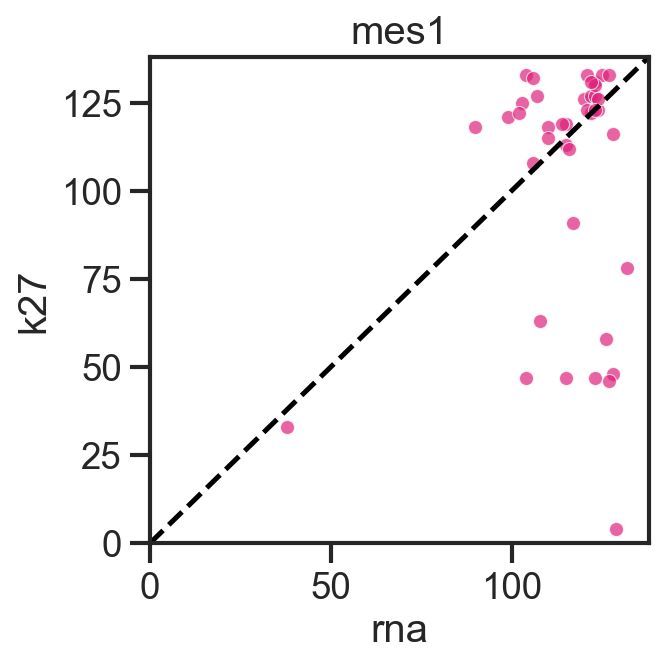

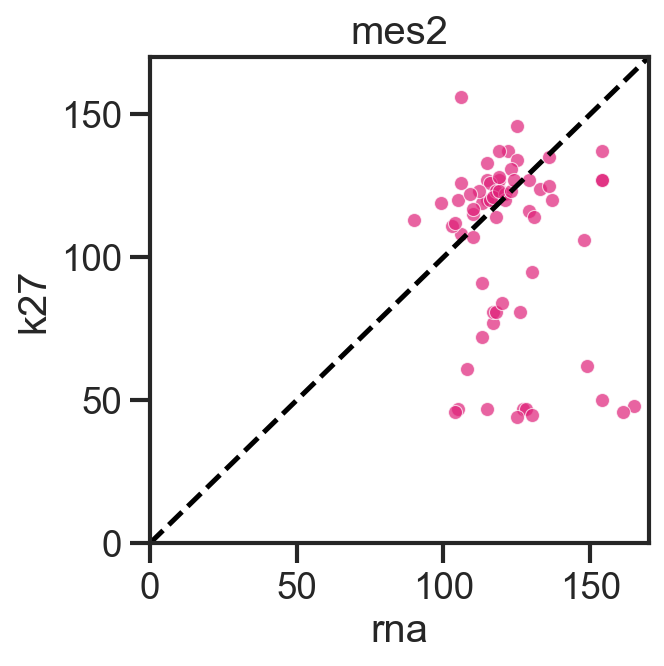

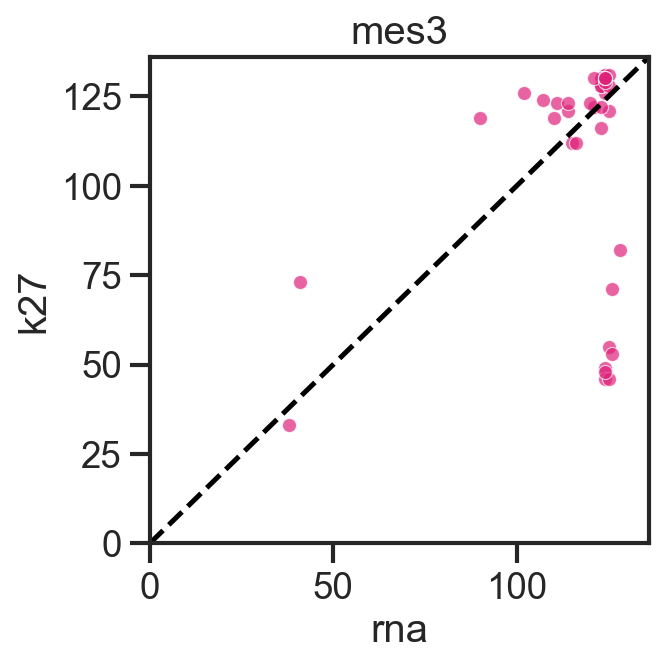

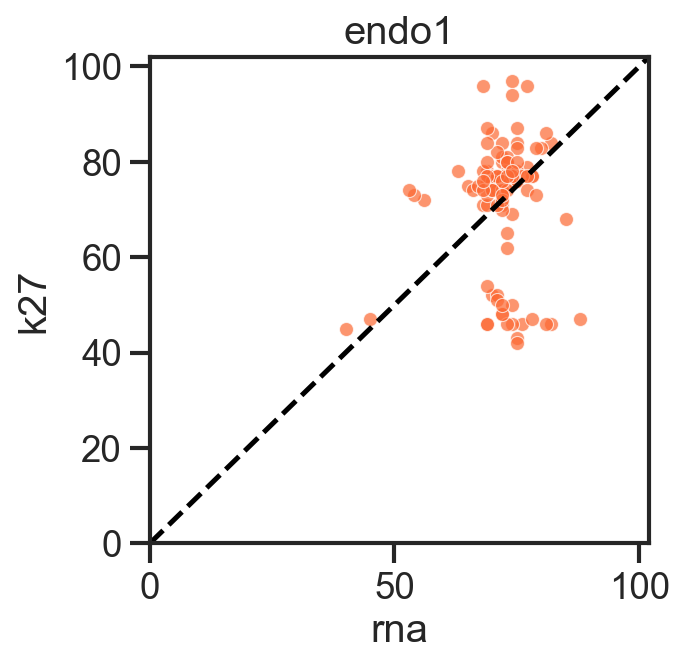

In [37]:
plotRNAvsK27(ect_changes,'ect1',col = 'Ectoderm')
plotRNAvsK27(ect_changes,'ect2',col = 'Ectoderm')
plotRNAvsK27(ect_changes,'ect3',col = 'Ectoderm')

plotRNAvsK27(mes_changes,'mes1',col = 'Mesoderm')
plotRNAvsK27(mes_changes,'mes2',col = 'Mesoderm')
plotRNAvsK27(mes_changes,'mes3',col = 'Mesoderm')

plotRNAvsK27(end_changes,'endo1',col = 'Endoderm')

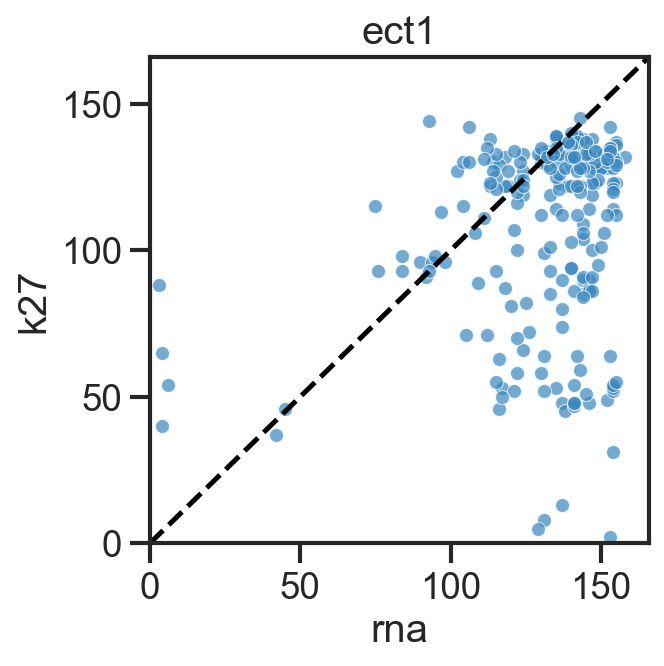

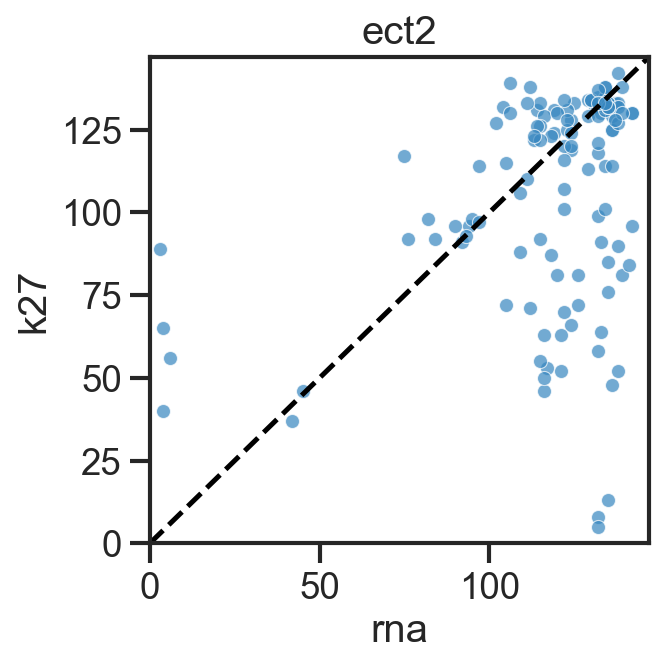

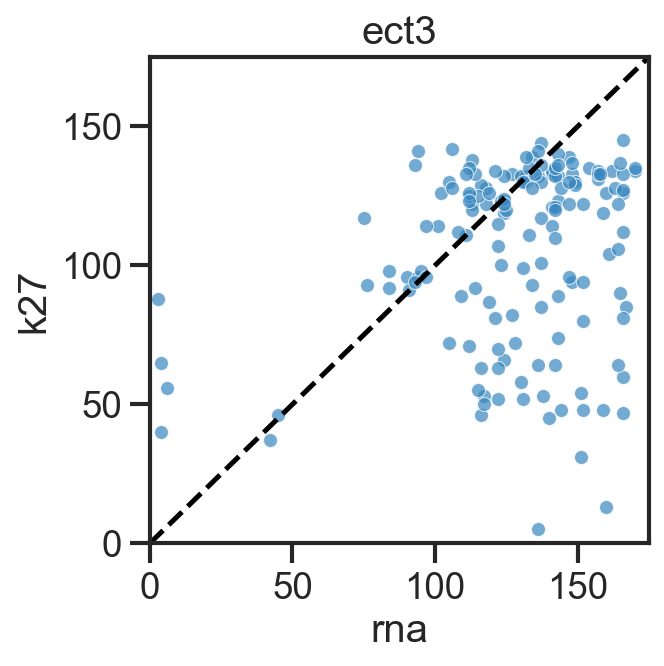

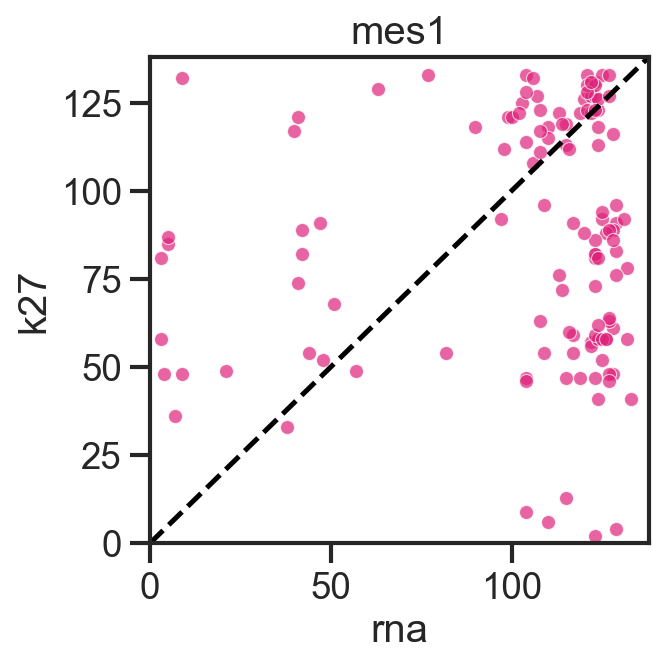

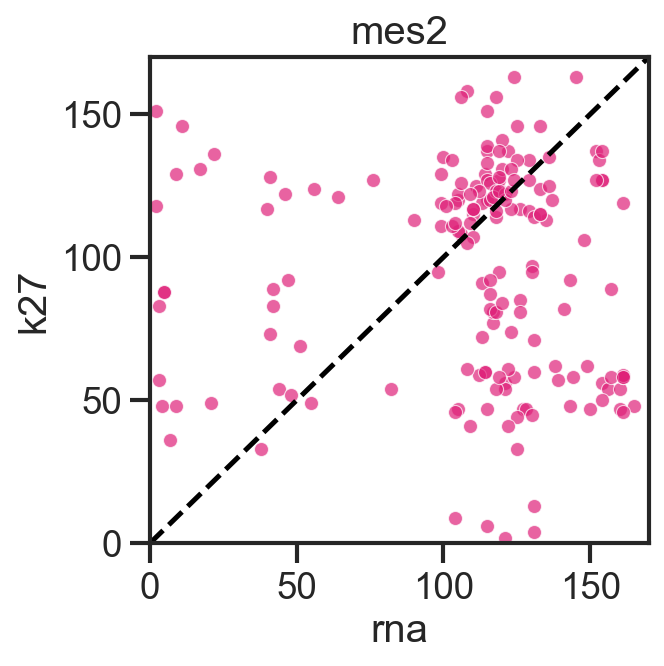

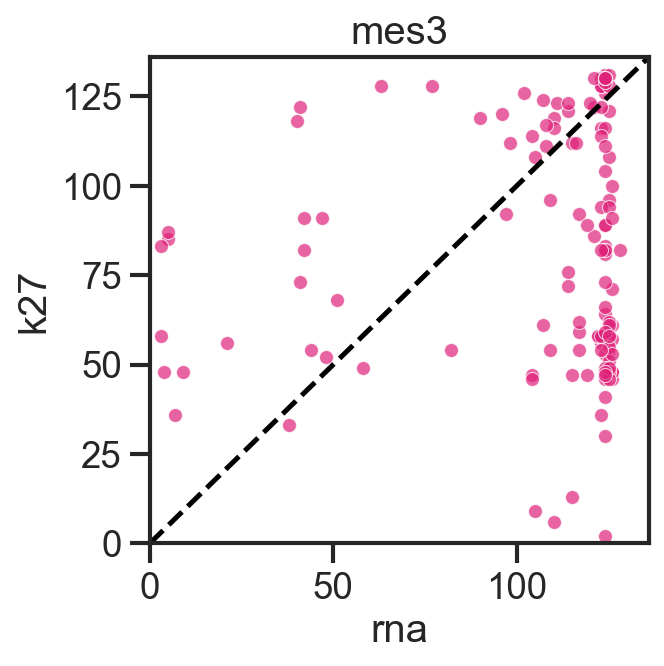

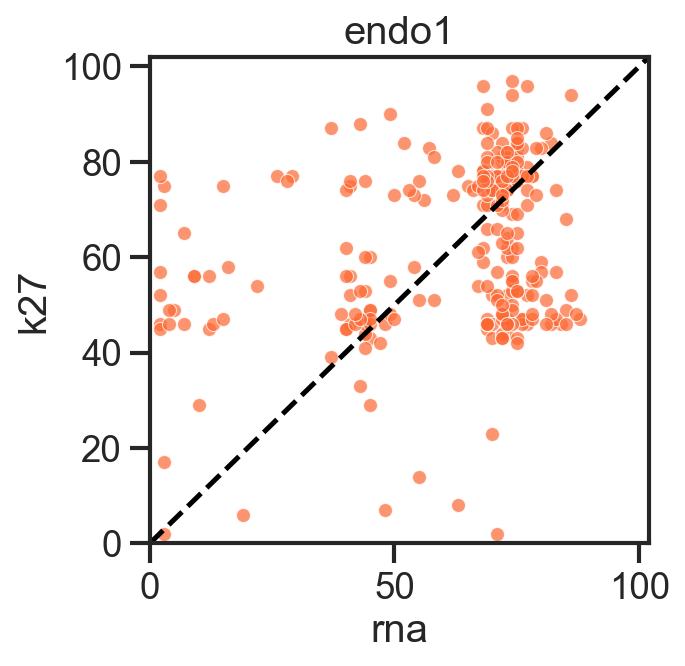

In [38]:
plotRNAvsK27(ect_changes,'ect1',col = 'Ectoderm',keep = 'first', save = 'figs/scatter_rna_vs_k27_ect1.png')
plotRNAvsK27(ect_changes,'ect2',col = 'Ectoderm',keep = 'first', save = 'figs/scatter_rna_vs_k27_ect2.png')
plotRNAvsK27(ect_changes,'ect3',col = 'Ectoderm',keep = 'first', save = 'figs/scatter_rna_vs_k27_ect3.png')

plotRNAvsK27(mes_changes,'mes1',col = 'Mesoderm',keep = 'first', save = 'figs/scatter_rna_vs_k27_mes1.png')
plotRNAvsK27(mes_changes,'mes2',col = 'Mesoderm',keep = 'first', save = 'figs/scatter_rna_vs_k27_mes2.png')
plotRNAvsK27(mes_changes,'mes3',col = 'Mesoderm',keep = 'first', save = 'figs/scatter_rna_vs_k27_mes3.png')

plotRNAvsK27(end_changes,'endo1',col = 'Endoderm',keep = 'first', save = 'figs/scatter_rna_vs_k27_end1.png')

In [39]:
def plotRNAvsK27(df, lin = 'ect1', col = 'Ectoderm', keep = False):
    df['dup'] = df['lin_layer'] + '_' + df['gene']
    df_unique = df[~df['dup'].duplicated(keep = keep)]
    k27 = df_unique[(df_unique['layer'] == 'K27') & (df_unique['lin'] == lin)][['gene','step']].set_index(['gene']).rename(columns={'step':'k27'})
    rna = df_unique[(df_unique['layer'] == 'RNA') & (df_unique['lin'] == lin)][['gene','step']].set_index(['gene']).rename(columns={'step':'rna'})

    plt.axline((1, 1), slope=1, linestyle = 'dashed', c = 'black')
    
    sns.scatterplot(data = rna.join(k27, how = 'inner'),
                    x = 'rna',
                    y = 'k27', s = 40, alpha = 0.7,zorder = 1,
                   color = color_pal[col])
    plt.xlim([0,dict1[lin+'_RNA']+5])
    plt.ylim([0,dict1[lin+'_RNA']+5])
    plt.title(lin)
    plt.show()
    

In [40]:
def calculateDiff(df, lin, keep = False, mark = 'K27'):
    df['dup'] = df['lin_layer'] + '_' + df['gene']
    df_unique = df[~df['dup'].duplicated(keep = keep)]
    k27 = df_unique[(df_unique['layer'] == mark) & (df_unique['lin'] == lin)][['gene','step']].set_index(['gene']).rename(columns={'step':mark})
    rna = df_unique[(df_unique['layer'] == 'RNA') & (df_unique['lin'] == lin)][['gene','step']].set_index(['gene']).rename(columns={'step':'rna'})
    joined = rna.join(k27, how = 'inner')
    joined['diff'] = joined[mark]-joined['rna']
    joined['lin'] = lin
    
    return joined

In [41]:
d1 = calculateDiff(ect_changes,'ect1',keep = 'first')
d2 = calculateDiff(ect_changes,'ect2',keep = 'first')
d3 = calculateDiff(ect_changes,'ect3',keep = 'first')

d4 = calculateDiff(mes_changes,'mes1',keep = 'first')
d5 = calculateDiff(mes_changes,'mes2',keep = 'first')
d6 = calculateDiff(mes_changes,'mes3',keep = 'first')

d7 = calculateDiff(end_changes,'endo1',keep = 'first')

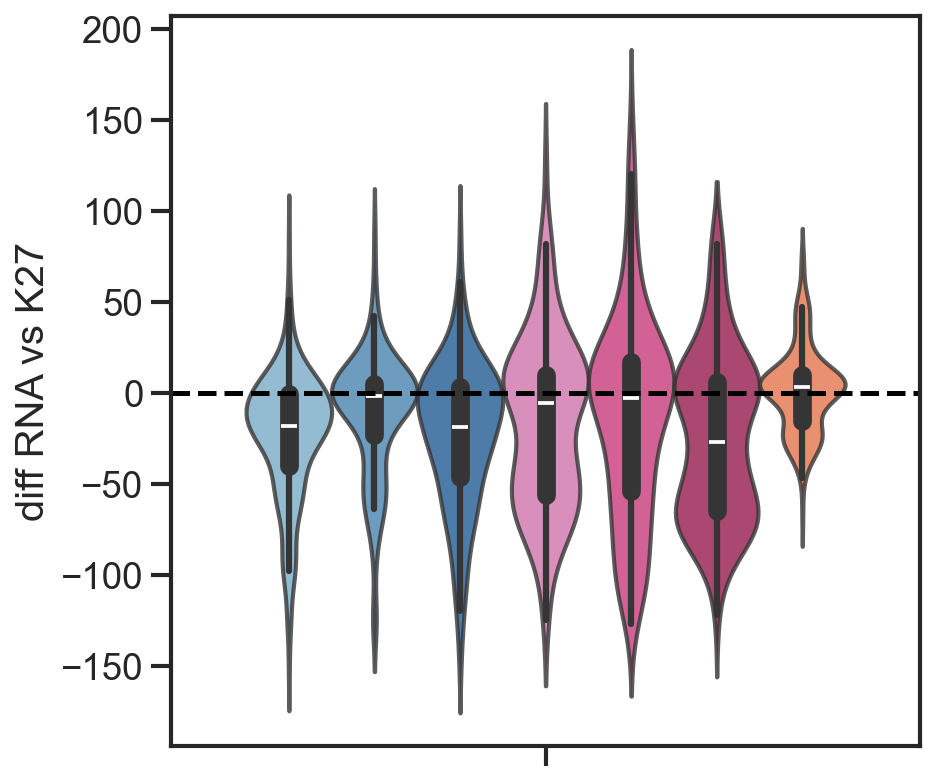

/var/folders/_k/c0bkq2m10c5f4h7vq_0xfm_40000gn/T/ipykernel_73249/76192351.py:13: UserWarning: 
The palette list has fewer values (1) than needed (7) and will cycle, which may produce an uninterpretable plot.
  sns.violinplot(data = pd.concat([d1,d2,d3,d4,d5,d6,d7]),ax=ax,


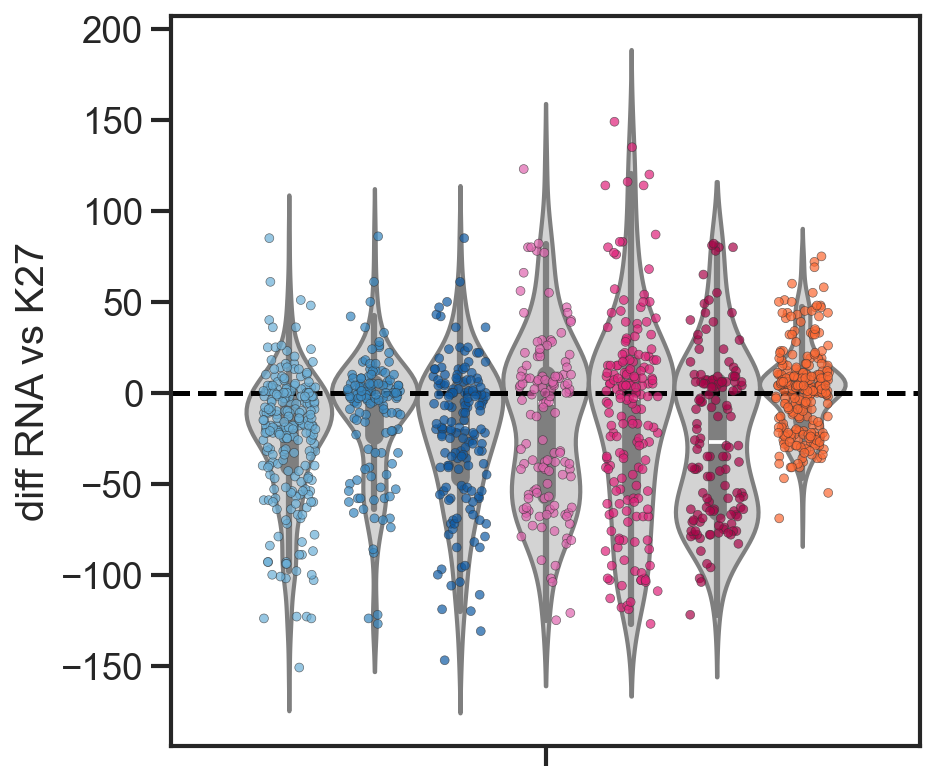

In [42]:
pal = ['#6AAED6', '#3787C0', '#105BA4', '#DF64AF', '#DF2179', '#A90649', '#FC6832',]
fig,ax = plt.subplots(figsize = (6,6))
sns.violinplot(data = pd.concat([d1,d2,d3,d4,d5,d6,d7]),ax=ax,
        y = 'diff', #fliersize = False,
               palette = pal,alpha = 0.8,
            hue = 'lin')
plt.legend([],frameon=False)
plt.axhline(0, linestyle = 'dashed', c = 'black')
plt.ylabel('diff RNA vs K27')
plt.show()

fig,ax = plt.subplots(figsize = (6,6))
sns.violinplot(data = pd.concat([d1,d2,d3,d4,d5,d6,d7]),ax=ax,
        y = 'diff', #fliersize = False,
               palette = ['lightgrey'],
            hue = 'lin')
sns.stripplot(data = pd.concat([d1,d2,d3,d4,d5,d6,d7]),ax=ax,
        y = 'diff',palette = pal,dodge = True, size = 4, alpha = 0.7, jitter = 0.25,linewidth = 0.3,
            hue = 'lin')
plt.legend([],frameon=False)
plt.axhline(0, linestyle = 'dashed', c = 'black')
plt.ylabel('diff RNA vs K27')
#plt.savefig('figs/20250306_barplot_deltaRNAvsK27_fix.png',bbox_inches = 'tight')
plt.show()

# try stdev cutoff

In [43]:
to_plot1.index.unique()

Index(['Irak2', 'Selenop', 'Habp2', 'Casp8', 'Castor2', 'Gpr146', 'Sel1l3',
       'Tmem125', 'Arid3c', 'Serpinf2',
       ...
       'Abcg1', 'Sec14l4', 'Apoa1', 'Grb14', 'Id1', 'Penk', 'Rasgrf2',
       'Pik3ip1', 'Slc26a9', 'Fam83b'],
      dtype='object', name='gene', length=547)

counts
([0.3564676012317078],)


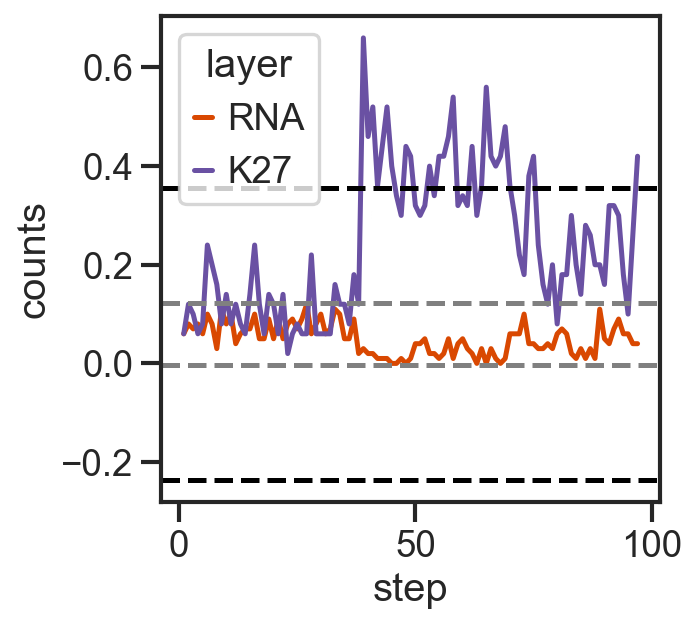

sm_short
([0.3521317766257633],)


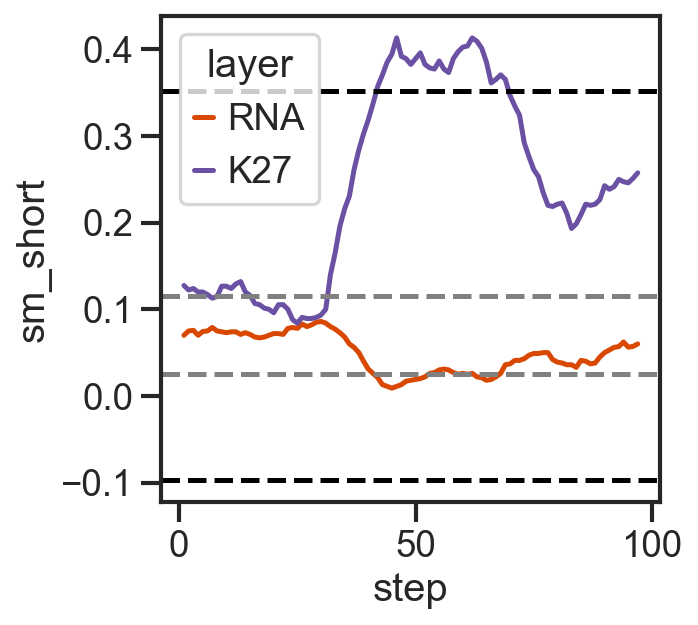

counts_log2
([-1.8710744114510638],)


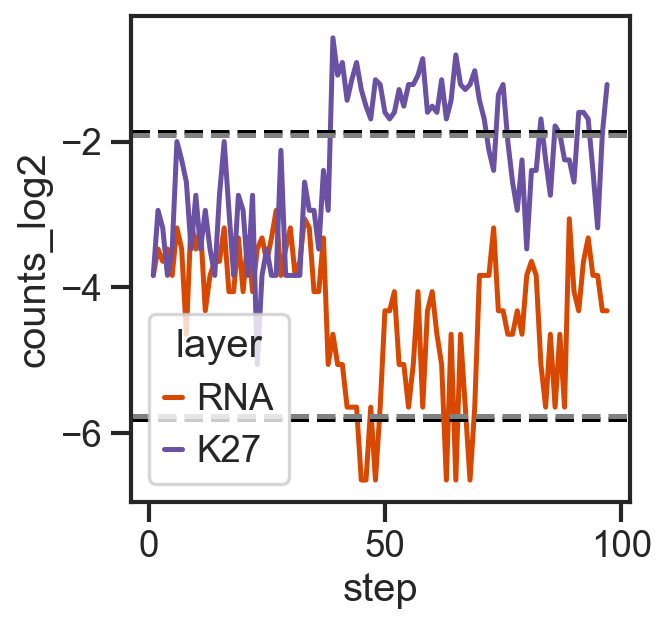

sm_short_log2
([-1.4262898733035154],)


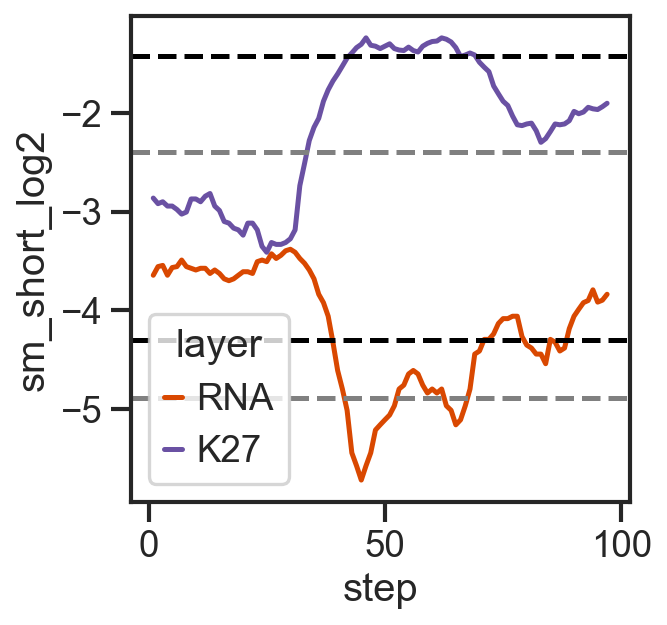

p_99
([0.3637724965142183],)


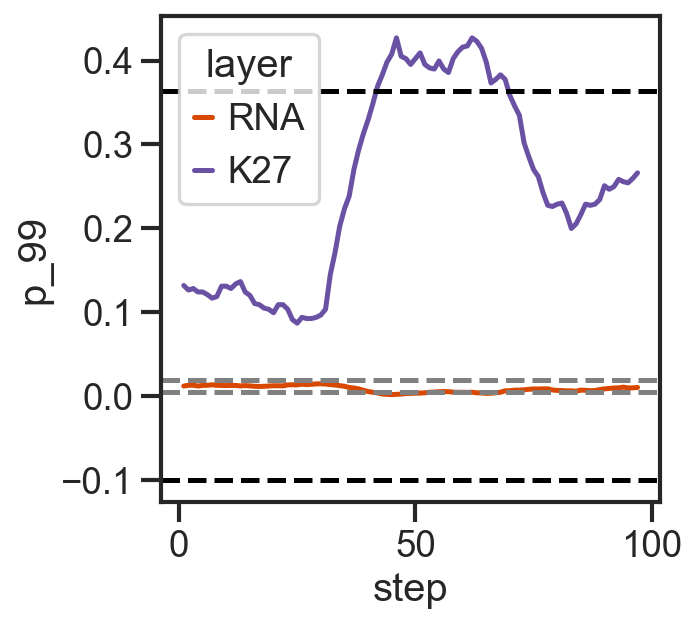

p_98
([0.4322403150070743],)


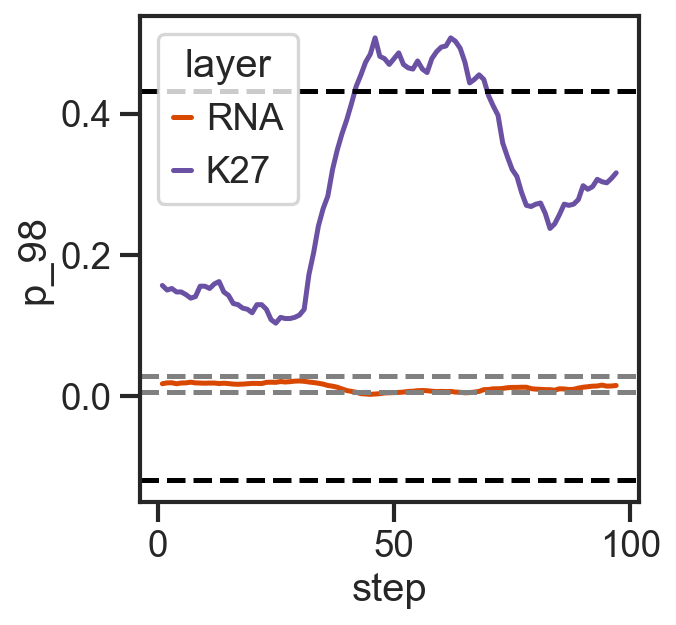

p_95
([0.5631105169921586],)


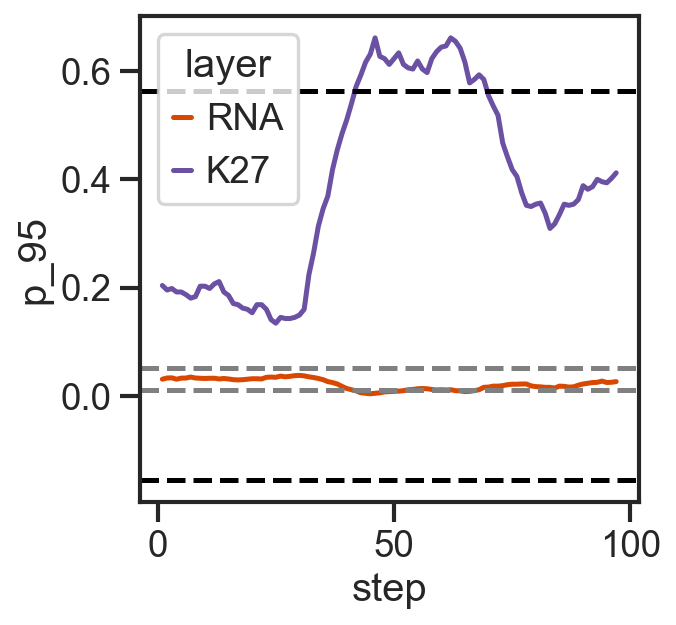

p98_log2
([0.5169557403502868],)


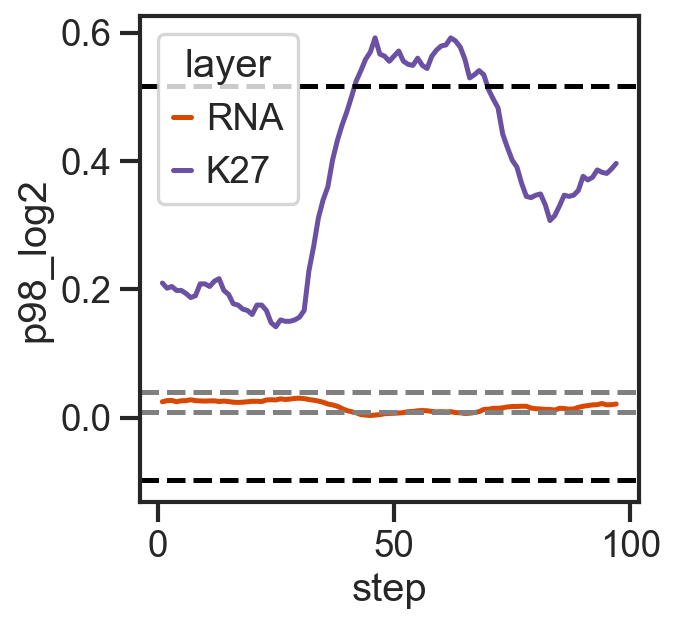

p98_log10
([0.155619184276117],)


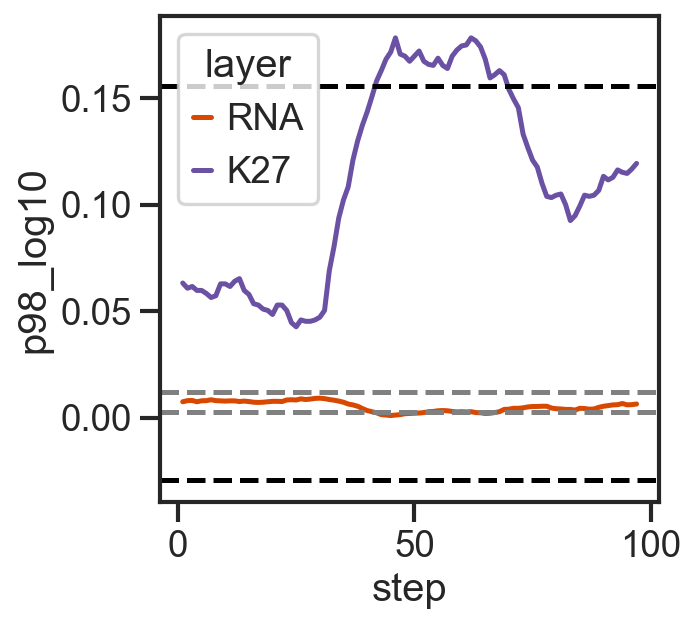

In [44]:
gene = 'Hbegf'#'Tnfrsf12a'#'Habp2'
lin = 'endo1'

vals = ['counts','sm_short','counts_log2','sm_short_log2','p_99','p_98','p_95','p98_log2','p98_log10']

for x in vals:
    print(x)
    testgene = ct_normalised[(ct_normalised['lin'] == lin) & (ct_normalised.index == gene)]
    
    sns.lineplot(data = testgene,
                 x = 'step',
                 y = x,
                 hue = 'layer', hue_order = ['RNA','K27'],
                 palette = [Orange,Purple])
    val = list(testgene[(testgene['layer'] == 'K27') & (testgene['step'] == 1)][x]+np.std(testgene[testgene['layer'] == 'K27'][x])*2),
    print(val)
    plt.axhline(val,
               c = 'black', linestyle = 'dashed')
    plt.axhline(list(testgene[(testgene['layer'] == 'K27') & (testgene['step'] == 1)][x]-np.std(testgene[testgene['layer'] == 'K27'][x])*2),
                c = 'black', linestyle = 'dashed')
    plt.axhline(list(testgene[(testgene['layer'] == 'RNA') & (testgene['step'] == 1)][x]+np.std(testgene[testgene['layer'] == 'RNA'][x])*2),
               c = 'grey', linestyle = 'dashed')
    plt.axhline(list(testgene[(testgene['layer'] == 'RNA') & (testgene['step'] == 1)][x]-np.std(testgene[testgene['layer'] == 'RNA'][x])*2),
                c = 'grey', linestyle = 'dashed')
    plt.show()


RNA
([0.11525876470173359],)


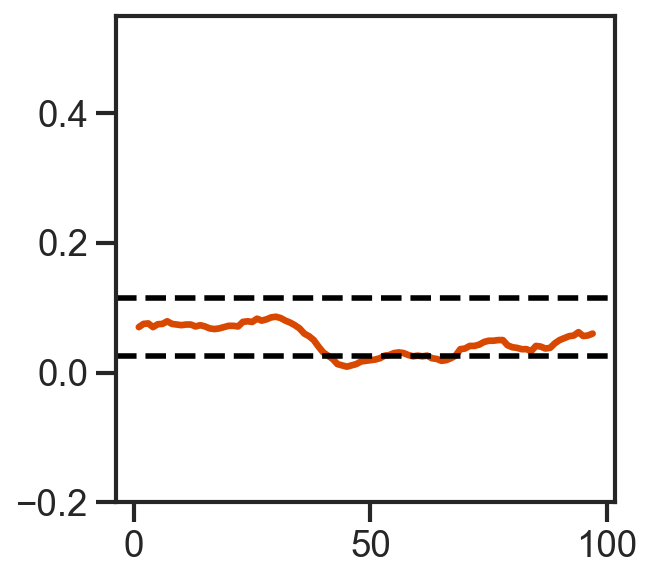

K27
([0.3521317766257633],)


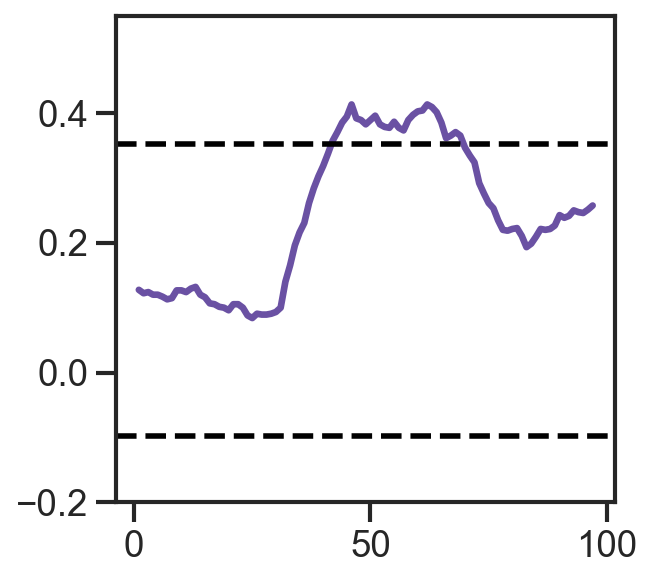

K4
([0.4646121253161436],)


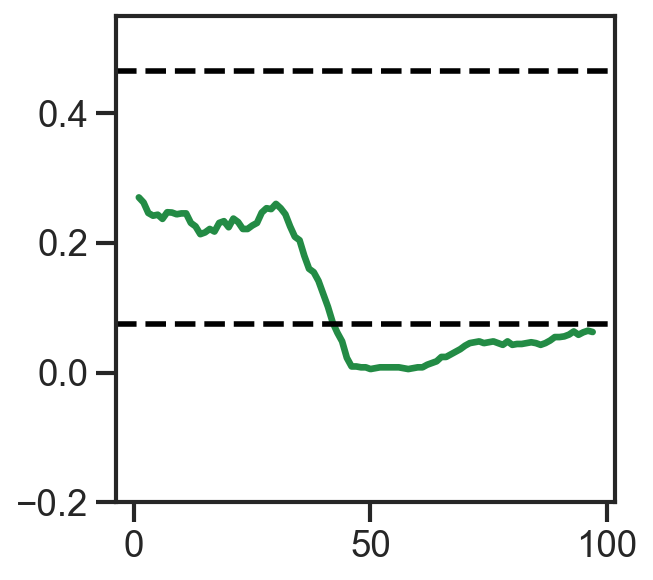

In [45]:
gene = 'Hbegf'#'Tnfrsf12a'#'Habp2'
lin = 'endo1'

vals = 'sm_short'

mods = ['RNA','K27', 'K4']
pal = [Orange,Purple,Green]
for num,x in enumerate(mods):
    print(x)
    testgene = ct_normalised[(ct_normalised['lin'] == lin) & (ct_normalised.index == gene)]
    
    sns.lineplot(data = testgene,
                 x = 'step',
                 y = vals,
                 hue = 'layer', hue_order = [x],linewidth = 3,
                 palette = [pal[num]])
    val = list(testgene[(testgene['layer'] == x) & (testgene['step'] == 1)][vals]+np.std(testgene[testgene['layer'] == x][vals])*2),
    print(val)
    plt.axhline(val,linewidth = 2.5,
               c = 'black', linestyle = 'dashed')
    plt.axhline(list(testgene[(testgene['layer'] == x) & (testgene['step'] == 1)][vals]-np.std(testgene[testgene['layer'] == x][vals])*2),
                linewidth = 2.5,
                c = 'black', linestyle = 'dashed')
    plt.ylim([-0.2, 0.55])
    plt.ylabel('')
    plt.xlabel('')
    plt.legend([], frameon = False)
    plt.show()


In [52]:
for_plot = calculate_stdev(ct_normalised_clean.loc['Crabp2'])

for_plot['state'] = 0
for_plot.loc[(for_plot['sm_short'] < for_plot['std_lower']), 'state'] =-1
for_plot.loc[(for_plot['sm_short'] > for_plot['std_upper']), 'state'] =+1

for_plot = findStateChanges(for_plot, state = 'state', val = 'sm_short')

for_plot_unique = for_plot[~for_plot['gene_lin_layer'].duplicated(keep='first')]

pivot table...
calculate stdev...
add to table...


/var/folders/_k/c0bkq2m10c5f4h7vq_0xfm_40000gn/T/ipykernel_73249/731907501.py:20: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  steps_1['counts'] = steps_1['lin_layer'].replace(dict1)


In [53]:
for_plot_unique[for_plot_unique['lin'] == 'ect3']

,step,gene,layer,lin,index,sm_short,lin_layer,step_id,RT,gene_lin_layer,std_lower,std_upper,state,change,val_change,steps1,total_change
12,128,Crabp2,RNA,ect3,430,0.098000,ect3_RNA,128:ect3,Gastd6,Crabp2_ect3_RNA,-0.068690,0.096690,1,1.0,0.010000,0.0140,-0.084000
47,119,Crabp2,K4,ect3,1420,0.270667,ect3_K4,119:ect3,Gastd5,Crabp2_ect3_K4,-0.025234,0.270234,1,1.0,0.002667,0.1225,-0.148167
67,81,Crabp2,K27,ect3,2381,0.153333,ect3_K27,81:ect3,Gastd4,Crabp2_ect3_K27,0.158372,1.131628,-1,-1.0,-0.010667,0.6450,0.491667


RNA
([0.02380942796115446],)


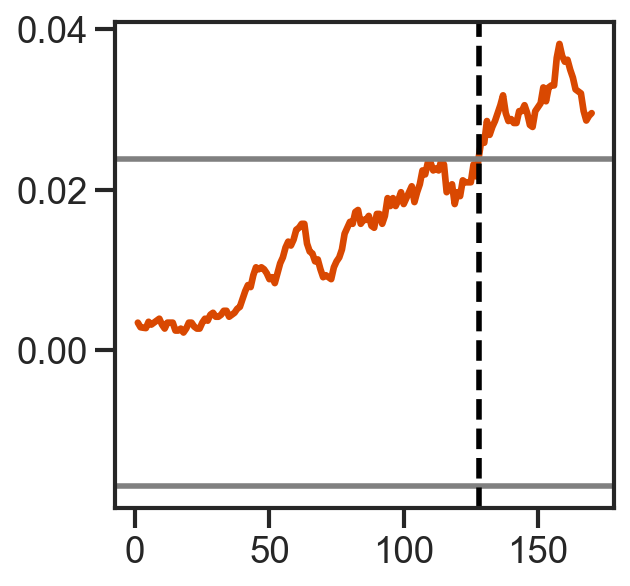

K27
([1.389068966117827],)


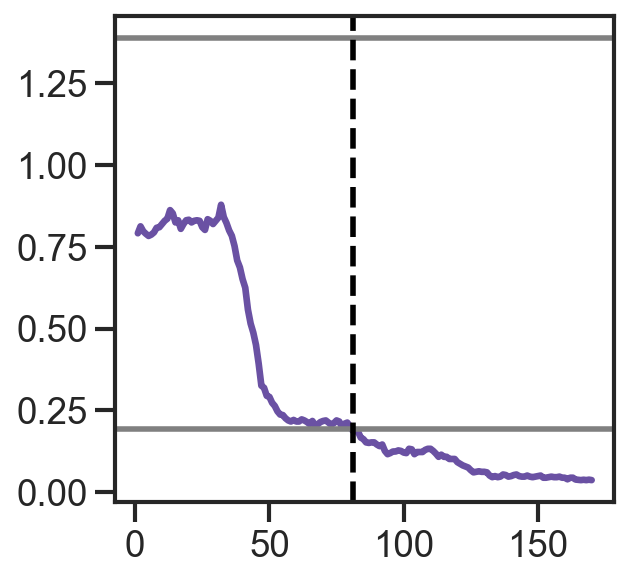

K4
([0.9426770598127626],)


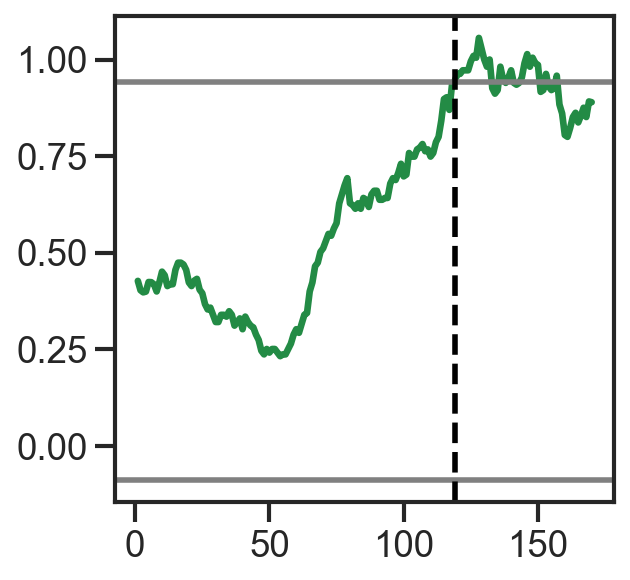

In [54]:
gene = 'Crabp2'#'Tnfrsf12a'#'Habp2'
lin = 'ect3'

vals = 'p_98'

mods = ['RNA','K27', 'K4']
stepchange = [128, 81, 119]

pal = [Orange,Purple,Green]
for num,x in enumerate(mods):
    print(x)
    testgene = ct_normalised[(ct_normalised['lin'] == lin) & (ct_normalised.index == gene)]
    
    sns.lineplot(data = testgene,
                 x = 'step',
                 y = vals,
                 hue = 'layer', hue_order = [x],linewidth = 3,
                 palette = [pal[num]])
    val = list(testgene[(testgene['layer'] == x) & (testgene['step'] == 1)][vals]+np.std(testgene[testgene['layer'] == x][vals])*2),
    print(val)
    plt.axhline(val,linewidth = 2.5,
               c = 'gray')#linestyle = 'dashed')
    plt.axhline(list(testgene[(testgene['layer'] == x) & (testgene['step'] == 1)][vals]-np.std(testgene[testgene['layer'] == x][vals])*2),
                linewidth = 2.5,
                c = 'gray')#, linestyle = 'dashed')
    plt.axvline(stepchange[num],linewidth = 2.5,
                c = 'black', linestyle = 'dashed')
    #plt.ylim([-0.2, 0.75])
    plt.ylabel('')
    plt.xlabel('')
    plt.legend([], frameon = False)
    plt.savefig('figs/20250417_stdev_QClineplot_' + str(x) + '.png')
    plt.show()


In [55]:
pwd

'/Users/mbloten1/Library/CloudStorage/OneDrive-UniversitédeLausanne/Documents/jupyter_default/2025/tchic_figures/fig6/diff_gene_analysis'

In [50]:
def calculate_stdev(df, val = 'sm_short'):
    print('pivot table...')
    df_pivot = df[['step','layer','lin',val,'lin_layer', 'step_id','RT']].reset_index().pivot(index = ['gene','lin','layer'], 
                                                                              columns = ['step'],
                                                                              values = [val])
    print('calculate stdev...')
    upper = df_pivot.iloc[:,0] + np.std(df_pivot, axis = 1)*2
    lower = df_pivot.iloc[:,0] - np.std(df_pivot, axis = 1)*2
    df_std = pd.DataFrame([lower,upper]).T.rename(columns = {0:'lower',1:'upper'}).reset_index()
    df_std['gene_lin_layer'] = df_std['gene'] + '_' + df_std['lin'] + '_' + df_std['layer']

    lower = dict(zip(df_std['gene_lin_layer'], df_std['lower']))
    upper = dict(zip(df_std['gene_lin_layer'], df_std['upper']))

    print('add to table...')
    df = df.reset_index()
    df['gene_lin_layer'] = df['gene'] + '_' + df['lin'] + '_' + df['layer']

    df['std_lower'] = df['gene_lin_layer'].map(lower)
    df['std_upper'] = df['gene_lin_layer'].map(upper)

    return df


In [51]:
ct_normalised_clean = ct_normalised[['step','layer','lin','sm_short','lin_layer', 'step_id','RT']]

In [56]:
stdev_all = calculate_stdev(ct_normalised_clean)

pivot table...
calculate stdev...
add to table...


In [57]:
stdev_all.head(2)

,gene,step,layer,lin,sm_short,lin_layer,step_id,RT,gene_lin_layer,std_lower,std_upper
0,Xkr4,1,RNA,ect1,0.284,ect1_RNA,1:ect1,mESCs,Xkr4_ect1_RNA,-14.691952,15.259952
1,Rp1,1,RNA,ect1,0.278,ect1_RNA,1:ect1,mESCs,Rp1_ect1_RNA,0.130064,0.425936


In [58]:
stdev_all['state'] = 0
stdev_all.loc[(stdev_all['sm_short'] < stdev_all['std_lower']), 'state'] =-1
stdev_all.loc[(stdev_all['sm_short'] > stdev_all['std_upper']), 'state'] =+1

In [59]:
std_endo = stdev_all[stdev_all['gene'].isin(list(set(endo['Gene']) & set(stdev_all['gene'])))]
std_meso = stdev_all[stdev_all['gene'].isin(list(set(meso['Gene']) & set(stdev_all['gene'])))]
std_ecto = stdev_all[stdev_all['gene'].isin(list(set(ecto['Gene']) & set(stdev_all['gene'])))]
std_plur = stdev_all[stdev_all['gene'].isin(list(set(pluri['Gene']) & set(stdev_all['gene'])))]

In [60]:
endo_changes = findStateChanges(std_endo, state = 'state', val = 'sm_short')

/var/folders/_k/c0bkq2m10c5f4h7vq_0xfm_40000gn/T/ipykernel_73249/731907501.py:20: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  steps_1['counts'] = steps_1['lin_layer'].replace(dict1)


In [61]:
endo_changes_unique = endo_changes[~endo_changes['gene_lin_layer'].duplicated(keep='first')]

In [62]:
meso_changes = findStateChanges(std_meso, state = 'state', val = 'sm_short')

/var/folders/_k/c0bkq2m10c5f4h7vq_0xfm_40000gn/T/ipykernel_73249/731907501.py:20: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  steps_1['counts'] = steps_1['lin_layer'].replace(dict1)


In [63]:
meso_changes_unique = meso_changes[~meso_changes['gene_lin_layer'].duplicated(keep='first')]

In [64]:
ecto_changes = findStateChanges(std_ecto, state = 'state', val = 'sm_short')

/var/folders/_k/c0bkq2m10c5f4h7vq_0xfm_40000gn/T/ipykernel_73249/731907501.py:20: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  steps_1['counts'] = steps_1['lin_layer'].replace(dict1)


In [65]:
ecto_changes_unique = ecto_changes[~ecto_changes['gene_lin_layer'].duplicated(keep='first')]

In [66]:
plur_changes = findStateChanges(std_plur, state = 'state', val = 'sm_short')

/var/folders/_k/c0bkq2m10c5f4h7vq_0xfm_40000gn/T/ipykernel_73249/731907501.py:20: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  steps_1['counts'] = steps_1['lin_layer'].replace(dict1)


In [67]:
plur_changes_unique = plur_changes[~plur_changes['gene_lin_layer'].duplicated(keep='first')]

In [68]:
endo_changes_f = endo_changes_unique[((endo_changes_unique['layer'] == 'RNA') & (endo_changes_unique['change'] == 1)) | ((endo_changes_unique['layer'] == 'K4') & (endo_changes_unique['change'] == 1)) | ((endo_changes_unique['layer'] == 'K27') & (endo_changes_unique['change'] == -1))]

In [69]:
meso_changes_f = meso_changes_unique[((meso_changes_unique['layer'] == 'RNA') & (meso_changes_unique['change'] == 1)) | ((meso_changes_unique['layer'] == 'K4') & (meso_changes_unique['change'] == 1)) | ((meso_changes_unique['layer'] == 'K27') & (meso_changes_unique['change'] == -1))]

In [70]:
ecto_changes_f = ecto_changes_unique[((ecto_changes_unique['layer'] == 'RNA') & (ecto_changes_unique['change'] == 1)) | ((ecto_changes_unique['layer'] == 'K4') & (ecto_changes_unique['change'] == 1)) | ((ecto_changes_unique['layer'] == 'K27') & (ecto_changes_unique['change'] == -1))]

In [71]:
plur_changes_f = plur_changes_unique[((plur_changes_unique['layer'] == 'RNA') & (plur_changes_unique['change'] == 1)) | ((plur_changes_unique['layer'] == 'K4') & (plur_changes_unique['change'] == 1)) | ((plur_changes_unique['layer'] == 'K27') & (plur_changes_unique['change'] == -1))]

In [72]:
#meso_2 = meso_changes_f[meso_changes_f['gene'].isin(pd.DataFrame(meso_changes_f[['gene','lin']].value_counts()[meso_changes_f[['gene','lin']].value_counts() >1]).reset_index()['gene'].unique())]

meso_all_3 = meso_changes_f[meso_changes_f['gene'].isin(pd.DataFrame(meso_changes_f[['gene','lin']].value_counts()[meso_changes_f[['gene','lin']].value_counts() == 3]).reset_index()['gene'].unique())]
meso_all_3.head(2)

,step,gene,layer,lin,index,sm_short,lin_layer,step_id,RT,gene_lin_layer,std_lower,std_upper,state,change,val_change,steps1,total_change
30,8,Tdo2,RNA,ect1,131218,0.009,ect1_RNA,8:ect1,mESCs,Tdo2_ect1_RNA,-0.000348,0.008348,1,1.0,0.002,0.038,0.029
35,9,Myocos,RNA,ect1,139346,0.018,ect1_RNA,9:ect1,mESCs,Myocos_ect1_RNA,0.000574,0.015426,1,1.0,0.006,0.004,-0.014


In [73]:
endo_K27RNA_changing = list(pd.DataFrame(endo_changes_f[endo_changes_f['layer'] != 'K4'][['gene','lin']].value_counts()[endo_changes_f[endo_changes_f['layer'] != 'K4'][['gene','lin']].value_counts() == 2]).reset_index()['gene'].unique())

meso_K27RNA_changing = list(pd.DataFrame(meso_changes_f[meso_changes_f['layer'] != 'K4'][['gene','lin']].value_counts()[meso_changes_f[meso_changes_f['layer'] != 'K4'][['gene','lin']].value_counts() == 2]).reset_index()['gene'].unique())

ecto_K27RNA_changing = list(pd.DataFrame(ecto_changes_f[ecto_changes_f['layer'] != 'K4'][['gene','lin']].value_counts()[ecto_changes_f[ecto_changes_f['layer'] != 'K4'][['gene','lin']].value_counts() == 2]).reset_index()['gene'].unique())



print(len(endo_K27RNA_changing), len(meso_K27RNA_changing),len(ecto_K27RNA_changing))

427 300 227


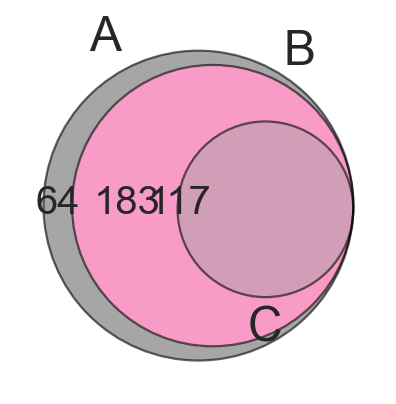

In [74]:
# sanity check
from matplotlib_venn import venn3, venn3_circles

all_genes = list(meso_changes_f['gene'].unique())
filtered = list(meso_all_3['gene'].unique())

cols = ['#fc6832','#df2179','#3787c0','#58b669']

fig,ax = plt.subplots(figsize = (3,3))
venn3([set(all_genes),set(meso_K27RNA_changing),set(filtered)],ax=ax, set_colors = ['grey',cols[1], 'grey'],
      alpha = 0.7)
c = venn3_circles([set(all_genes),set(meso_K27RNA_changing),set(filtered)],color = 'black',linewidth = 1,ax=ax, 
      alpha = 0.6)
plt.show()

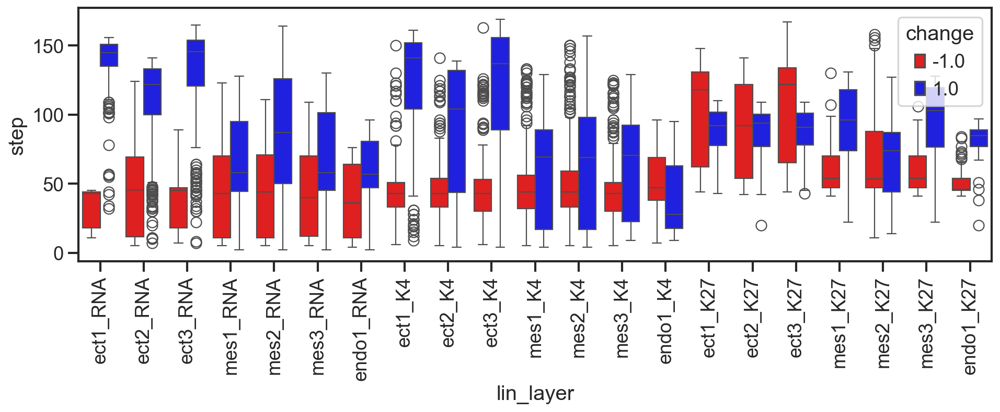

In [75]:
fig,ax = plt.subplots(figsize = (14,4))
sns.boxplot(data = ecto_changes_unique,ax=ax,
              x = 'lin_layer',
              y = 'step', #palette = [Orange,Green,Purple],
              hue = 'change', palette = ['red','blue'],
              dodge = True)
plt.xticks(rotation = 90)
plt.show()

In [76]:
endo_K27RNA_changing = list(pd.DataFrame(endo_changes_f[endo_changes_f['layer'] != 'K4'][['gene','lin']].value_counts()[endo_changes_f[endo_changes_f['layer'] != 'K4'][['gene','lin']].value_counts() == 2]).reset_index()['gene'].unique())
meso_K27RNA_changing = list(pd.DataFrame(meso_changes_f[meso_changes_f['layer'] != 'K4'][['gene','lin']].value_counts()[meso_changes_f[meso_changes_f['layer'] != 'K4'][['gene','lin']].value_counts() == 2]).reset_index()['gene'].unique())
ecto_K27RNA_changing = list(pd.DataFrame(ecto_changes_f[ecto_changes_f['layer'] != 'K4'][['gene','lin']].value_counts()[ecto_changes_f[ecto_changes_f['layer'] != 'K4'][['gene','lin']].value_counts() == 2]).reset_index()['gene'].unique())

endo_K4RNA_changing = list(pd.DataFrame(endo_changes_f[endo_changes_f['layer'] != 'K27'][['gene','lin']].value_counts()[endo_changes_f[endo_changes_f['layer'] != 'K27'][['gene','lin']].value_counts() == 2]).reset_index()['gene'].unique())
meso_K4RNA_changing = list(pd.DataFrame(meso_changes_f[meso_changes_f['layer'] != 'K27'][['gene','lin']].value_counts()[meso_changes_f[meso_changes_f['layer'] != 'K27'][['gene','lin']].value_counts() == 2]).reset_index()['gene'].unique())
ecto_K4RNA_changing = list(pd.DataFrame(ecto_changes_f[ecto_changes_f['layer'] != 'K27'][['gene','lin']].value_counts()[ecto_changes_f[ecto_changes_f['layer'] != 'K27'][['gene','lin']].value_counts() == 2]).reset_index()['gene'].unique())

endo_allchanging = list(pd.DataFrame(endo_changes_f[['gene','lin']].value_counts()[endo_changes_f[['gene','lin']].value_counts() == 3]).reset_index()['gene'].unique())
meso_allchanging = list(pd.DataFrame(meso_changes_f[['gene','lin']].value_counts()[meso_changes_f[['gene','lin']].value_counts() == 3]).reset_index()['gene'].unique())
ecto_allchanging = list(pd.DataFrame(ecto_changes_f[['gene','lin']].value_counts()[ecto_changes_f[['gene','lin']].value_counts() == 3]).reset_index()['gene'].unique())

print(len(endo_K27RNA_changing), len(meso_K27RNA_changing),len(ecto_K27RNA_changing))

427 300 227


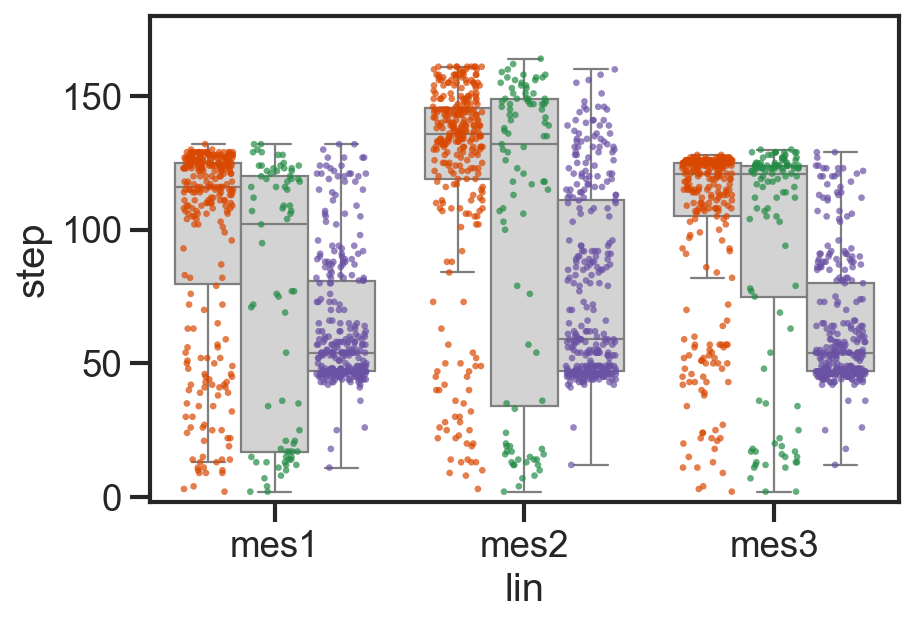

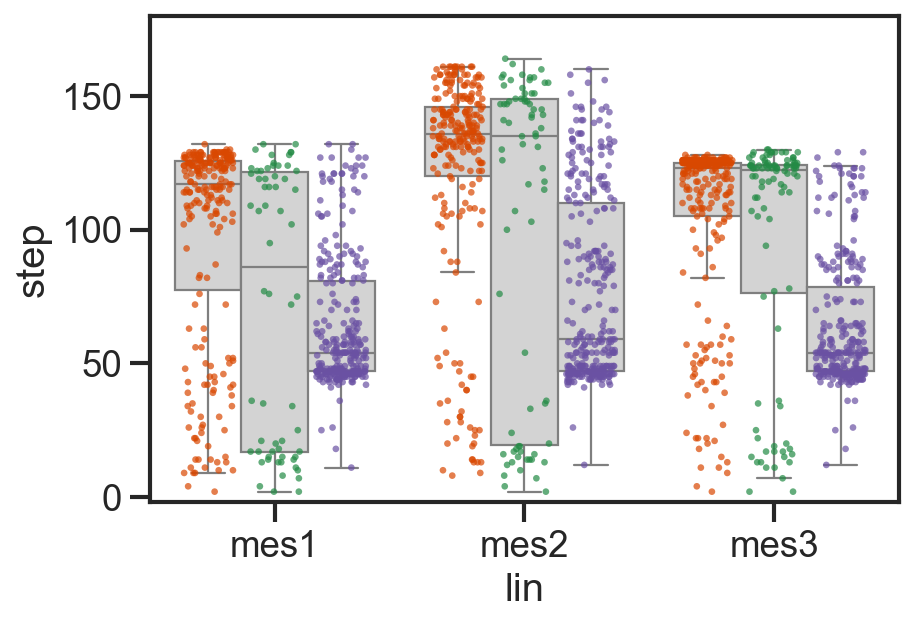

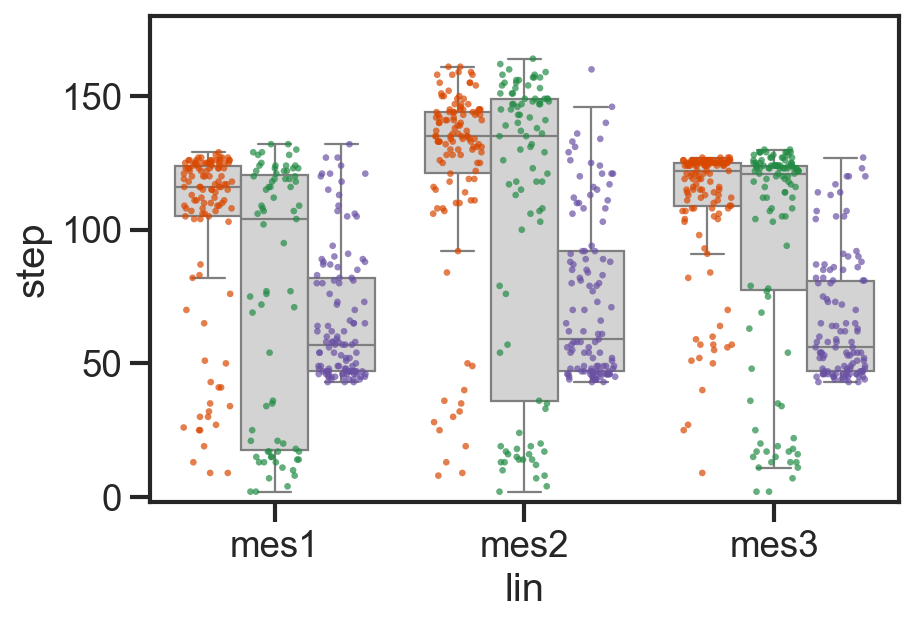

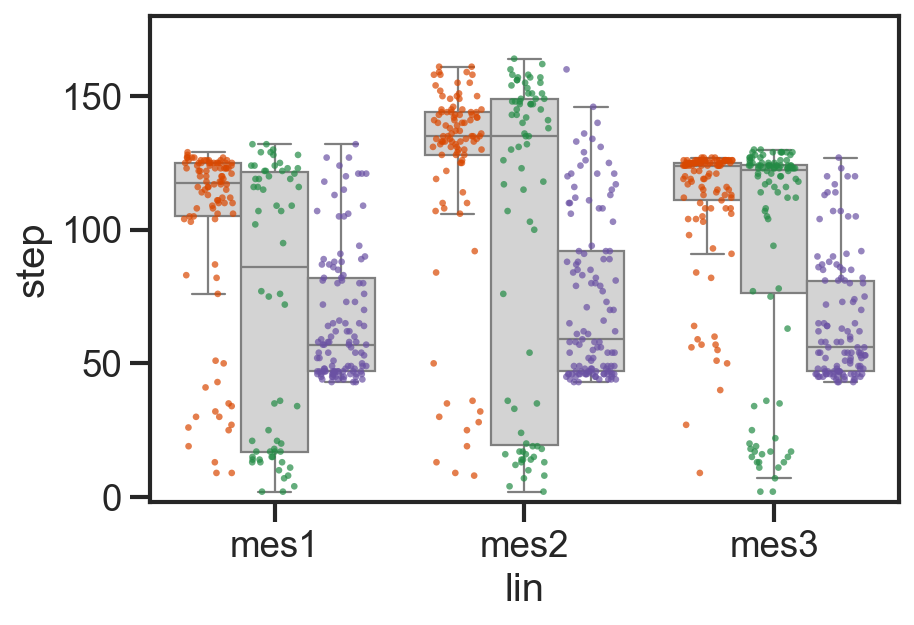

In [80]:
fig,ax = plt.subplots(figsize = (6,4))
sns.boxplot(data = meso_changes_f,ax=ax,
              x = 'lin', order = ['mes1','mes2','mes3'],fliersize = False,
              y = 'step', palette = ['lightgrey','lightgrey','lightgrey'],# [Orange,Purple],
              hue = 'layer', #palette = ['red','blue'],
              dodge = True)
sns.stripplot(data = meso_changes_f,ax=ax,
              x = 'lin', order = ['mes1','mes2','mes3'],
              y = 'step', palette = [Orange,Green,Purple], size = 3, alpha = 0.7, jitter = 0.3,
              hue = 'layer', #palette = ['red','blue'],
              dodge = True)
plt.legend([],frameon = False)
plt.ylim([-2,180])
plt.savefig('figs/20250417_mes_steps_changing_per_layer_unfiltered.png', bbox_inches = 'tight')
plt.show()

fig,ax = plt.subplots(figsize = (6,4))
sns.boxplot(data = meso_changes_f[meso_changes_f['gene'].isin(meso_K27RNA_changing)],ax=ax,
              x = 'lin', order = ['mes1','mes2','mes3'],fliersize = False,
              y = 'step', palette = ['lightgrey','lightgrey','lightgrey'],# [Orange,Purple],
              hue = 'layer', #palette = ['red','blue'],
              dodge = True)
sns.stripplot(data = meso_changes_f[meso_changes_f['gene'].isin(meso_K27RNA_changing)],ax=ax,
              x = 'lin', order = ['mes1','mes2','mes3'],
              y = 'step', palette = [Orange,Green,Purple], size = 3, alpha = 0.7, jitter = 0.3,
              hue = 'layer', #palette = ['red','blue'],
              dodge = True)
plt.legend([],frameon = False)
plt.ylim([-2,180])
plt.savefig('figs/20250417_mes_steps_changing_per_layer_K27RNA.png', bbox_inches = 'tight')
plt.show()

fig,ax = plt.subplots(figsize = (6,4))
sns.boxplot(data = meso_changes_f[meso_changes_f['gene'].isin(meso_K4RNA_changing)],ax=ax,
              x = 'lin', order = ['mes1','mes2','mes3'],fliersize = False,
              y = 'step', palette = ['lightgrey','lightgrey','lightgrey'],# [Orange,Purple],
              hue = 'layer', #palette = ['red','blue'],
              dodge = True)
sns.stripplot(data = meso_changes_f[meso_changes_f['gene'].isin(meso_K4RNA_changing)],ax=ax,
              x = 'lin', order = ['mes1','mes2','mes3'],
              y = 'step', palette = [Orange,Green,Purple], size = 3, alpha = 0.7, jitter = 0.3,
              hue = 'layer', #palette = ['red','blue'],
              dodge = True)
plt.legend([],frameon = False)
plt.ylim([-2,180])
plt.savefig('figs/20250417_mes_steps_changing_per_layer_K4RNA.png', bbox_inches = 'tight')
plt.show()

fig,ax = plt.subplots(figsize = (6,4))
sns.boxplot(data = meso_changes_f[meso_changes_f['gene'].isin(meso_allchanging)],ax=ax,
              x = 'lin', order = ['mes1','mes2','mes3'],fliersize = False,
              y = 'step', palette = ['lightgrey','lightgrey','lightgrey'],# [Orange,Purple],
              hue = 'layer', #palette = ['red','blue'],
              dodge = True)
sns.stripplot(data = meso_changes_f[meso_changes_f['gene'].isin(meso_allchanging)],ax=ax,
              x = 'lin', order = ['mes1','mes2','mes3'],
              y = 'step', palette = [Orange,Green,Purple], size = 3, alpha = 0.7, jitter = 0.3,
              hue = 'layer', #palette = ['red','blue'],
              dodge = True)
plt.legend([],frameon = False)
plt.ylim([-2,180])
plt.savefig('figs/20250417_mes_steps_changing_per_layer_all_changing.png', bbox_inches = 'tight')
plt.show()

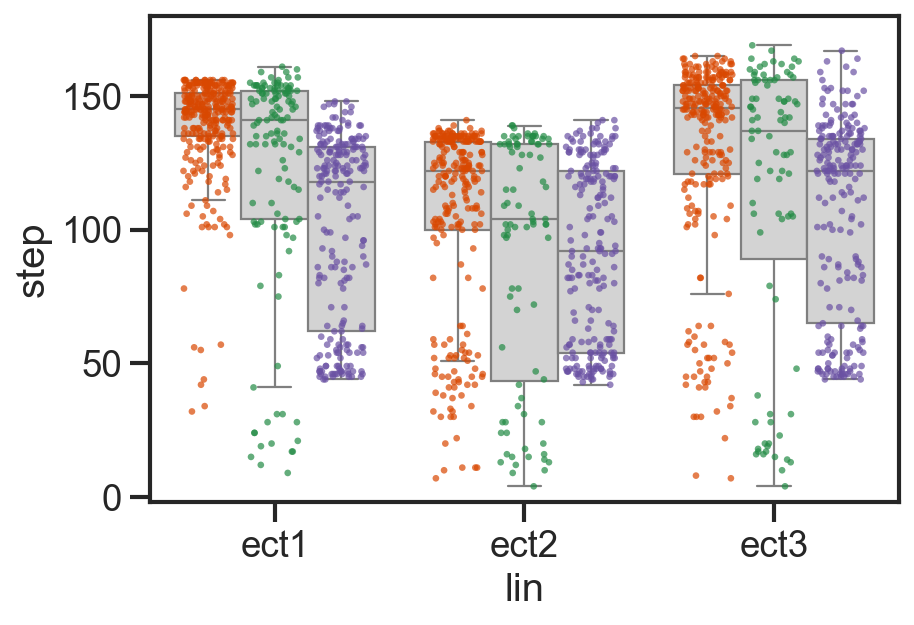

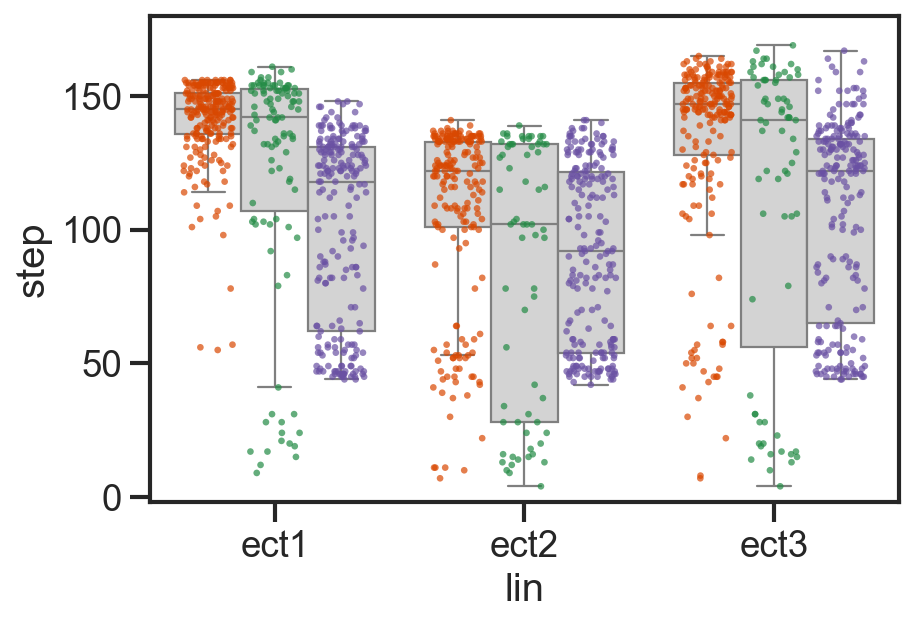

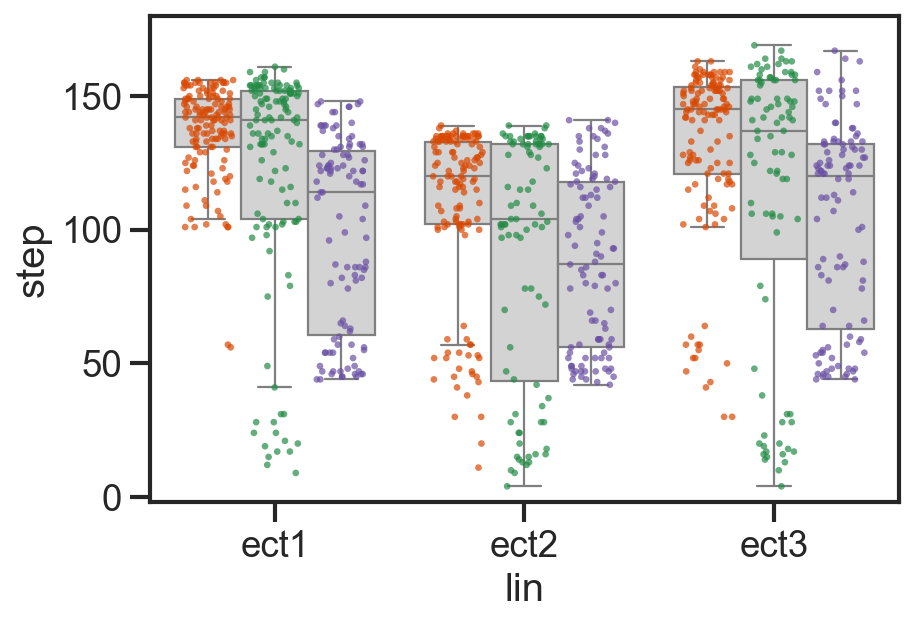

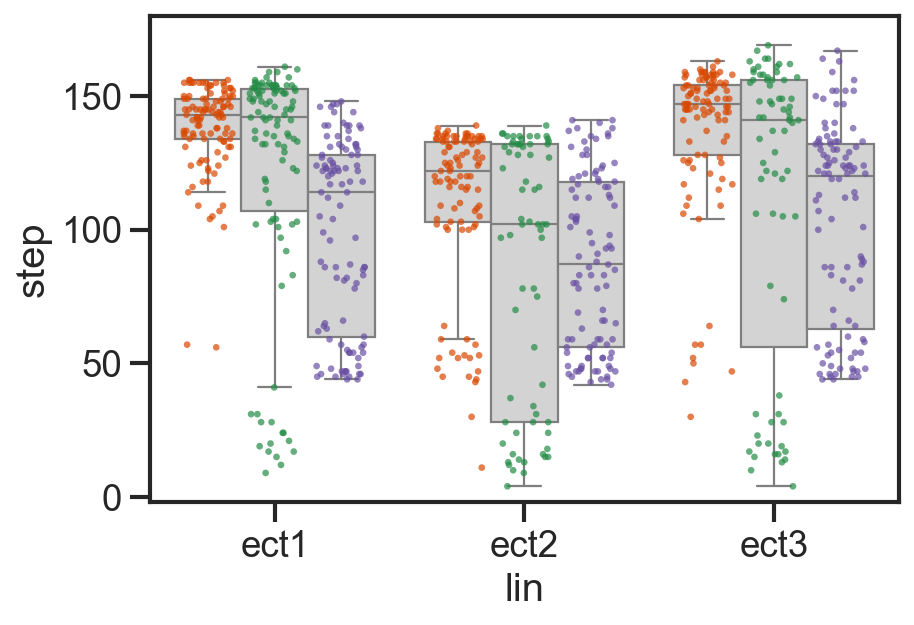

In [81]:
fig,ax = plt.subplots(figsize = (6,4))
sns.boxplot(data = ecto_changes_f,ax=ax,
              x = 'lin', order = ['ect1','ect2','ect3'],fliersize = False,
              y = 'step', palette = ['lightgrey','lightgrey','lightgrey'],# [Orange,Purple],
              hue = 'layer', #palette = ['red','blue'],
              dodge = True)
sns.stripplot(data = ecto_changes_f,ax=ax,
              x = 'lin', order = ['ect1','ect2','ect3'],
              y = 'step', palette = [Orange,Green,Purple], size = 3, alpha = 0.7, jitter = 0.3,
              hue = 'layer', #palette = ['red','blue'],
              dodge = True)
plt.legend([],frameon = False)
plt.ylim([-2,180])
plt.savefig('figs/20250417_ect_steps_changing_per_layer_unfiltered.png', bbox_inches = 'tight')
plt.show()

fig,ax = plt.subplots(figsize = (6,4))
sns.boxplot(data = ecto_changes_f[ecto_changes_f['gene'].isin(ecto_K27RNA_changing)],ax=ax,
              x = 'lin', order = ['ect1','ect2','ect3'],fliersize = False,
              y = 'step', palette = ['lightgrey','lightgrey','lightgrey'],# [Orange,Purple],
              hue = 'layer', #palette = ['red','blue'],
              dodge = True)
sns.stripplot(data = ecto_changes_f[ecto_changes_f['gene'].isin(ecto_K27RNA_changing)],ax=ax,
              x = 'lin', order = ['ect1','ect2','ect3'],
              y = 'step', palette = [Orange,Green,Purple], size = 3, alpha = 0.7, jitter = 0.3,
              hue = 'layer', #palette = ['red','blue'],
              dodge = True)
plt.legend([],frameon = False)
plt.ylim([-2,180])
plt.savefig('figs/20250417_ect_steps_changing_per_layer_K27RNA.png', bbox_inches = 'tight')
plt.show()

fig,ax = plt.subplots(figsize = (6,4))
sns.boxplot(data = ecto_changes_f[ecto_changes_f['gene'].isin(ecto_K4RNA_changing)],ax=ax,
              x = 'lin', order = ['ect1','ect2','ect3'],fliersize = False,
              y = 'step', palette = ['lightgrey','lightgrey','lightgrey'],# [Orange,Purple],
              hue = 'layer', #palette = ['red','blue'],
              dodge = True)
sns.stripplot(data = ecto_changes_f[ecto_changes_f['gene'].isin(ecto_K4RNA_changing)],ax=ax,
              x = 'lin', order = ['ect1','ect2','ect3'],
              y = 'step', palette = [Orange,Green,Purple], size = 3, alpha = 0.7, jitter = 0.3,
              hue = 'layer', #palette = ['red','blue'],
              dodge = True)
plt.legend([],frameon = False)
plt.ylim([-2,180])
plt.savefig('figs/20250417_ect_steps_changing_per_layer_K4RNA.png', bbox_inches = 'tight')
plt.show()

fig,ax = plt.subplots(figsize = (6,4))
sns.boxplot(data = ecto_changes_f[ecto_changes_f['gene'].isin(ecto_allchanging)],ax=ax,
              x = 'lin', order = ['ect1','ect2','ect3'],fliersize = False,
              y = 'step', palette = ['lightgrey','lightgrey','lightgrey'],# [Orange,Purple],
              hue = 'layer', #palette = ['red','blue'],
              dodge = True)
sns.stripplot(data = ecto_changes_f[ecto_changes_f['gene'].isin(ecto_allchanging)],ax=ax,
              x = 'lin', order = ['ect1','ect2','ect3'],
              y = 'step', palette = [Orange,Green,Purple], size = 3, alpha = 0.7, jitter = 0.3,
              hue = 'layer', #palette = ['red','blue'],
              dodge = True)
plt.legend([],frameon = False)
plt.ylim([-2,180])
plt.savefig('figs/20250417_ect_steps_changing_per_layer_all_changing.png', bbox_inches = 'tight')
plt.show()

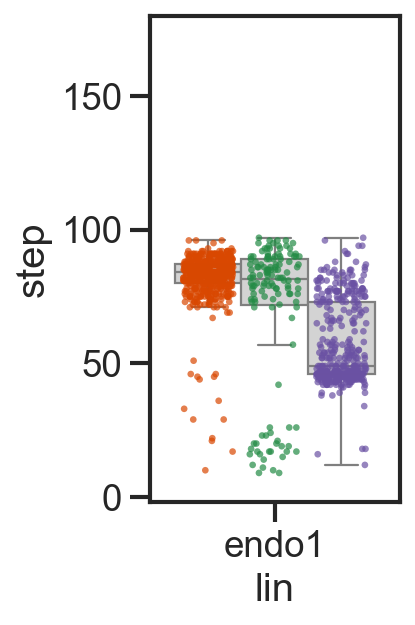

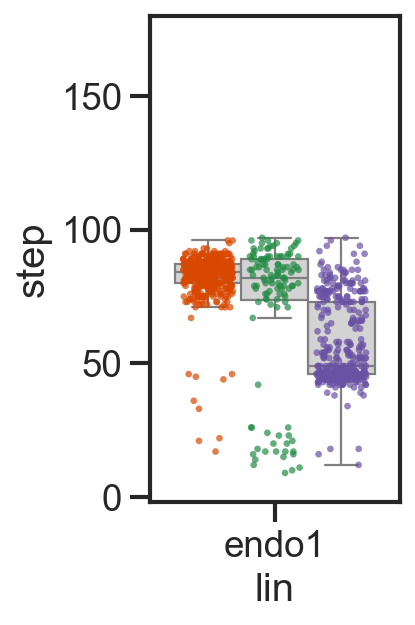

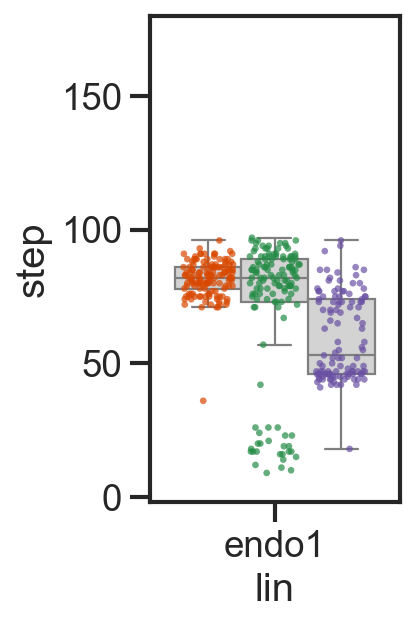

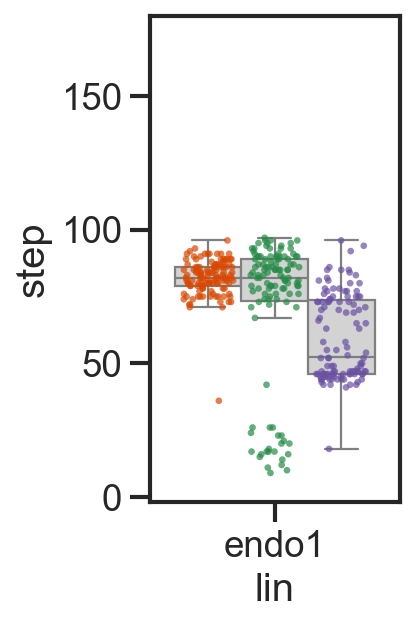

In [82]:
fig,ax = plt.subplots(figsize = (2,4))
sns.boxplot(data = endo_changes_f,ax=ax,
              x = 'lin', order = ['endo1'],fliersize = False,
              y = 'step', palette = ['lightgrey','lightgrey','lightgrey'],# [Orange,Purple],
              hue = 'layer', #palette = ['red','blue'],
              dodge = True)
sns.stripplot(data = endo_changes_f,ax=ax,
              x = 'lin', order = ['endo1'],
              y = 'step', palette = [Orange,Green,Purple], size = 3, alpha = 0.7, jitter = 0.3,
              hue = 'layer', #palette = ['red','blue'],
              dodge = True)
plt.legend([],frameon = False)
plt.ylim([-2,180])
plt.savefig('figs/20250417_end_steps_changing_per_layer_unfiltered.png', bbox_inches = 'tight')
plt.show()

fig,ax = plt.subplots(figsize = (2,4))
sns.boxplot(data = endo_changes_f[endo_changes_f['gene'].isin(endo_K27RNA_changing)],ax=ax,
              x = 'lin', order = ['endo1'],fliersize = False,
              y = 'step', palette = ['lightgrey','lightgrey','lightgrey'],# [Orange,Purple],
              hue = 'layer', #palette = ['red','blue'],
              dodge = True)
sns.stripplot(data = endo_changes_f[endo_changes_f['gene'].isin(endo_K27RNA_changing)],ax=ax,
              x = 'lin', order = ['endo1'],
              y = 'step', palette = [Orange,Green,Purple], size = 3, alpha = 0.7, jitter = 0.3,
              hue = 'layer', #palette = ['red','blue'],
              dodge = True)
plt.legend([],frameon = False)
plt.ylim([-2,180])
plt.savefig('figs/20250417_end_steps_changing_per_layer_K27RNA.png', bbox_inches = 'tight')
plt.show()

fig,ax = plt.subplots(figsize = (2,4))
sns.boxplot(data = endo_changes_f[endo_changes_f['gene'].isin(endo_K4RNA_changing)],ax=ax,
              x = 'lin', order = ['endo1'],fliersize = False,
              y = 'step', palette = ['lightgrey','lightgrey','lightgrey'],# [Orange,Purple],
              hue = 'layer', #palette = ['red','blue'],
              dodge = True)
sns.stripplot(data = endo_changes_f[endo_changes_f['gene'].isin(endo_K4RNA_changing)],ax=ax,
              x = 'lin', order = ['endo1'],
              y = 'step', palette = [Orange,Green,Purple], size = 3, alpha = 0.7, jitter = 0.3,
              hue = 'layer', #palette = ['red','blue'],
              dodge = True)
plt.legend([],frameon = False)
plt.ylim([-2,180])
plt.savefig('figs/20250417_end_steps_changing_per_layer_K4RNA.png', bbox_inches = 'tight')
plt.show()

fig,ax = plt.subplots(figsize = (2,4))
sns.boxplot(data = endo_changes_f[endo_changes_f['gene'].isin(endo_allchanging)],ax=ax,
              x = 'lin', order = ['endo1'],fliersize = False,
              y = 'step', palette = ['lightgrey','lightgrey','lightgrey'],# [Orange,Purple],
              hue = 'layer', #palette = ['red','blue'],
              dodge = True)
sns.stripplot(data = endo_changes_f[endo_changes_f['gene'].isin(endo_allchanging)],ax=ax,
              x = 'lin', order = ['endo1'],
              y = 'step', palette = [Orange,Green,Purple], size = 3, alpha = 0.7, jitter = 0.3,
              hue = 'layer', #palette = ['red','blue'],
              dodge = True)
plt.legend([],frameon = False)
plt.ylim([-2,180])
plt.savefig('figs/20250417_end_steps_changing_per_layer_all_changing.png', bbox_inches = 'tight')
plt.show()

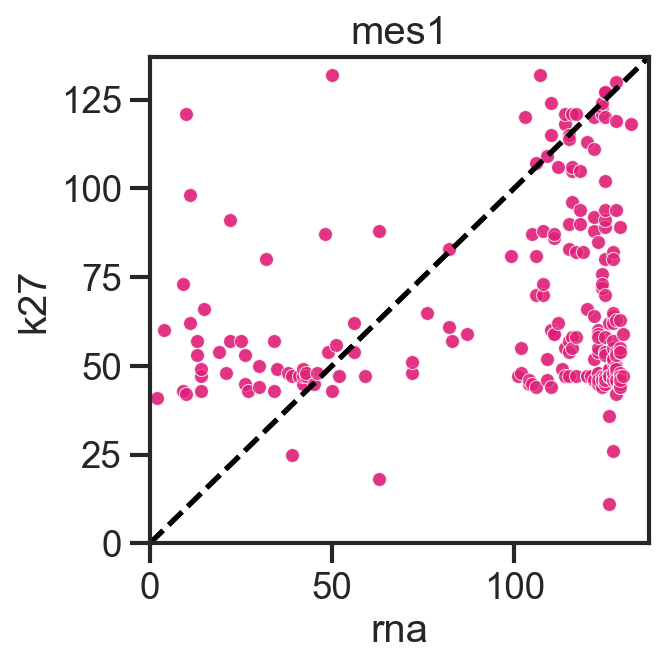

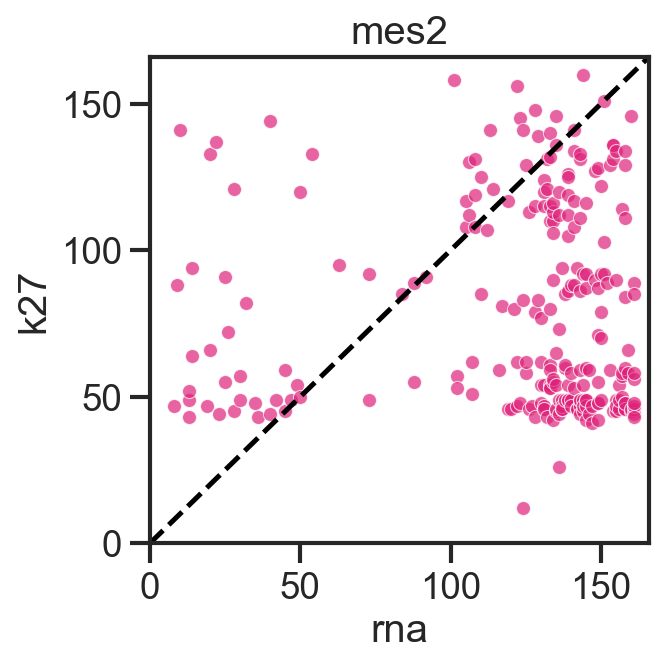

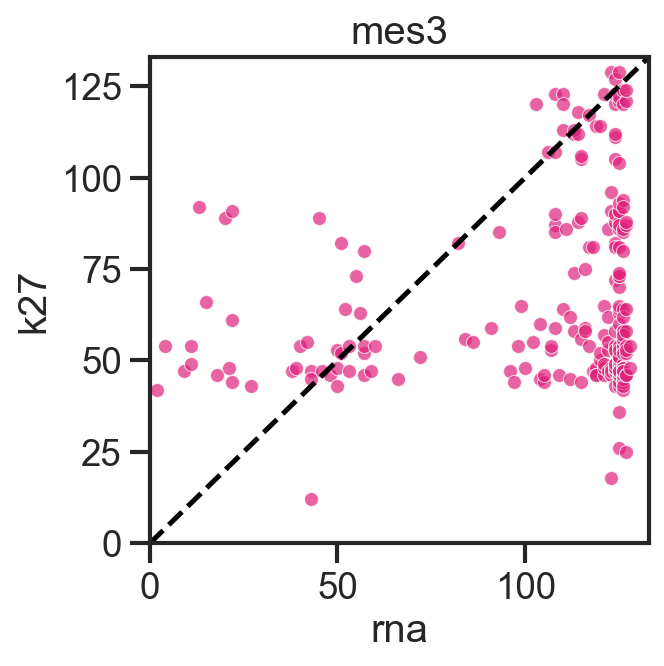

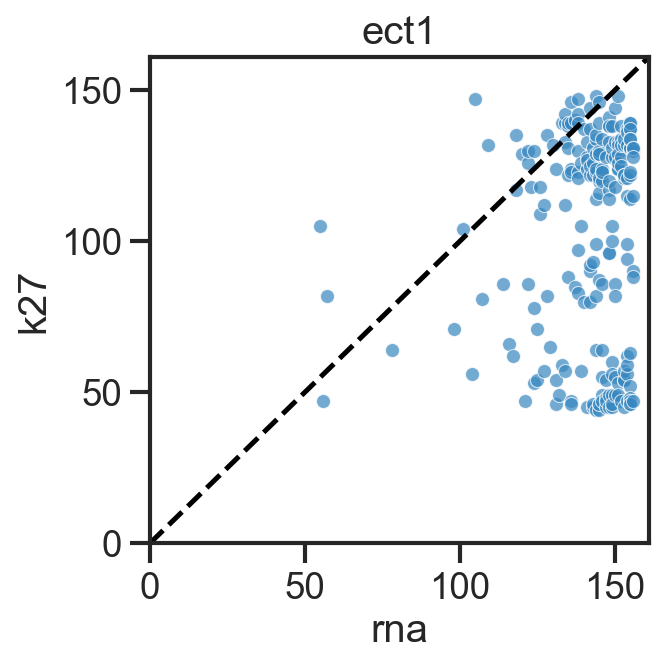

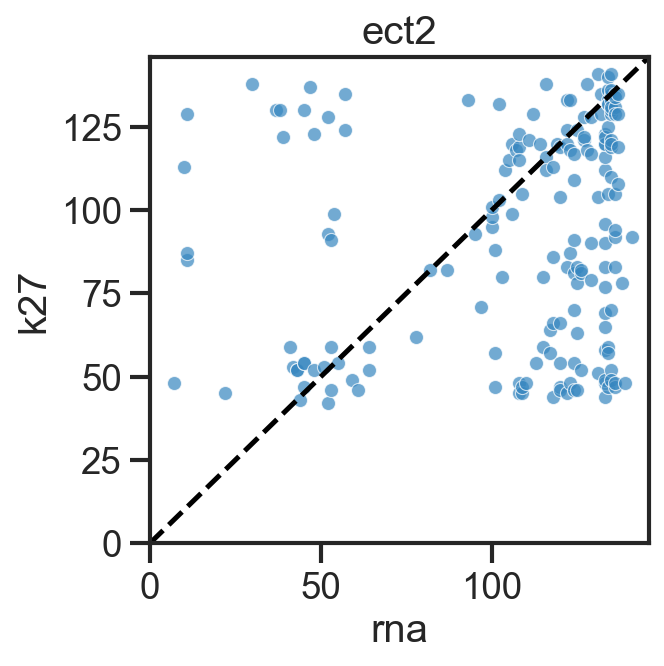

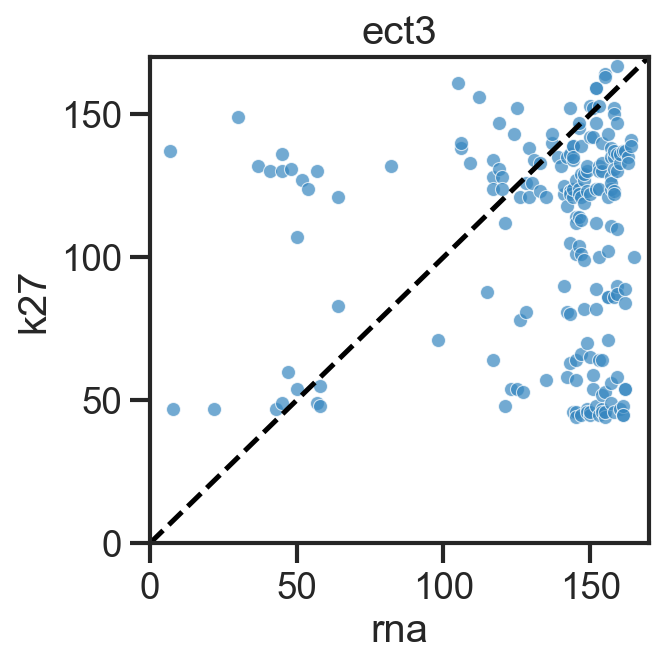

In [162]:
plotRNAvsK27(meso_changes_f,'mes1',col = 'Mesoderm',keep = 'first')# save = 'figs/scatter_rna_vs_k27_ect1.png')
plotRNAvsK27(meso_changes_f,'mes2',col = 'Mesoderm',keep = 'first')# save = 'figs/scatter_rna_vs_k27_ect1.png')
plotRNAvsK27(meso_changes_f,'mes3',col = 'Mesoderm',keep = 'first')# save = 'figs/scatter_rna_vs_k27_ect1.png')
ecto_changes_f = ecto_changes_f.reset_index()
plotRNAvsK27(ecto_changes_f,'ect1',col = 'Ectoderm',keep = 'first')# save = 'figs/scatter_rna_vs_k27_ect1.png')
plotRNAvsK27(ecto_changes_f,'ect2',col = 'Ectoderm',keep = 'first')# save = 'figs/scatter_rna_vs_k27_ect1.png')
plotRNAvsK27(ecto_changes_f,'ect3',col = 'Ectoderm',keep = 'first')# save = 'figs/scatter_rna_vs_k27_ect1.png')

In [163]:
import warnings
warnings.filterwarnings('ignore')

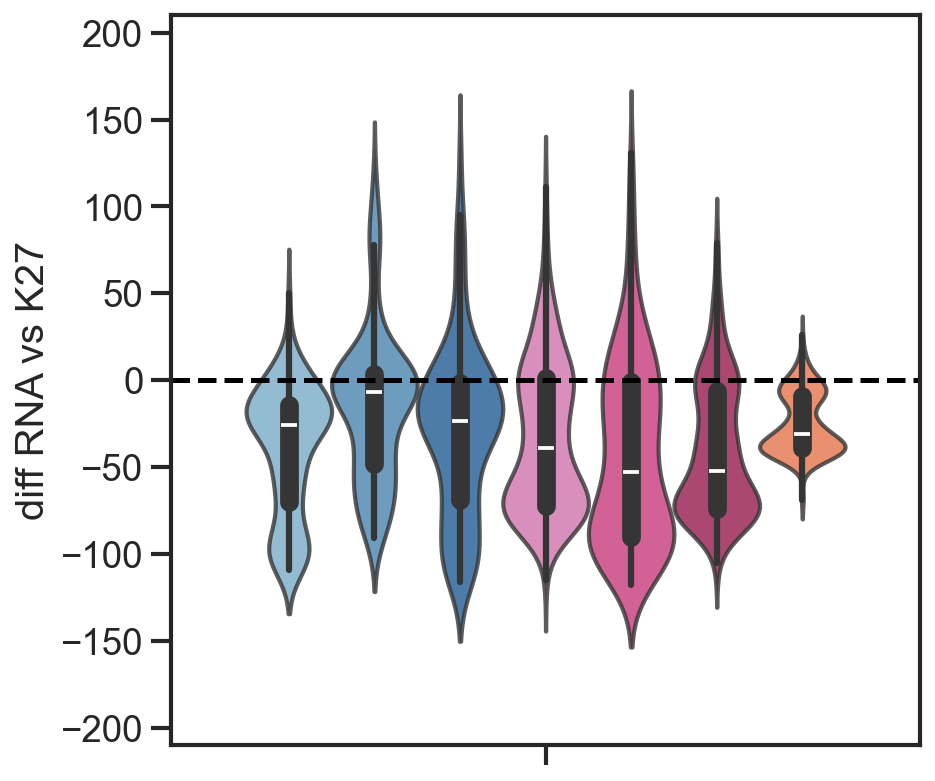

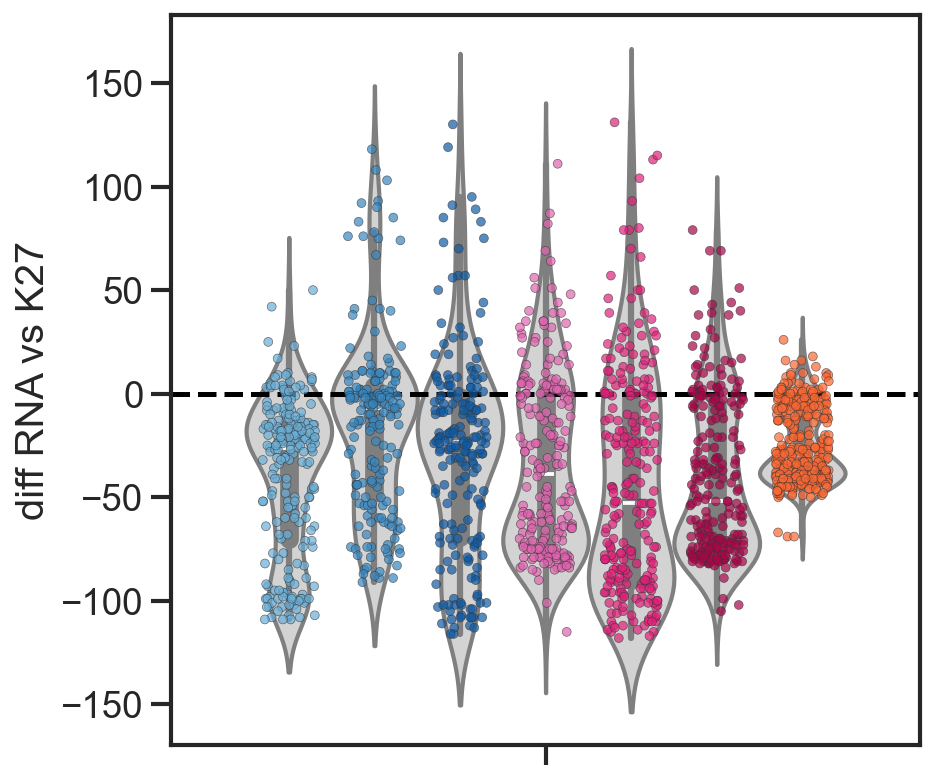

In [164]:
d1 = calculateDiff(ecto_changes_f,'ect1',keep = 'first')
d2 = calculateDiff(ecto_changes_f,'ect2',keep = 'first')
d3 = calculateDiff(ecto_changes_f,'ect3',keep = 'first')

d4 = calculateDiff(meso_changes_f,'mes1',keep = 'first')
d5 = calculateDiff(meso_changes_f,'mes2',keep = 'first')
d6 = calculateDiff(meso_changes_f,'mes3',keep = 'first')

d7 = calculateDiff(endo_changes_f,'endo1',keep = 'first')

pal = ['#6AAED6', '#3787C0', '#105BA4', '#DF64AF', '#DF2179', '#A90649', '#FC6832',]
fig,ax = plt.subplots(figsize = (6,6))
sns.violinplot(data = pd.concat([d1,d2,d3,d4,d5,d6,d7]),ax=ax,
        y = 'diff', #fliersize = False,
               palette = pal,alpha = 0.8,
            hue = 'lin')
plt.legend([],frameon=False)
plt.axhline(0, linestyle = 'dashed', c = 'black')
plt.ylabel('diff RNA vs K27')
plt.ylim([-210, 210])
plt.savefig('figs/20250415_violin_deltaRNAvsK27_stdev_unfiltered.png',bbox_inches = 'tight')
plt.show()

fig,ax = plt.subplots(figsize = (6,6))
sns.violinplot(data = pd.concat([d1,d2,d3,d4,d5,d6,d7]),ax=ax,
        y = 'diff', #fliersize = False,
               palette = ['lightgrey'],
            hue = 'lin')
sns.stripplot(data = pd.concat([d1,d2,d3,d4,d5,d6,d7]),ax=ax,
        y = 'diff',palette = pal,dodge = True, size = 4, alpha = 0.7, jitter = 0.25,linewidth = 0.3,
            hue = 'lin')
plt.legend([],frameon=False)
plt.axhline(0, linestyle = 'dashed', c = 'black')
plt.ylabel('diff RNA vs K27')
#plt.savefig('figs/20250306_barplot_deltaRNAvsK27_fix.png',bbox_inches = 'tight')
plt.show()

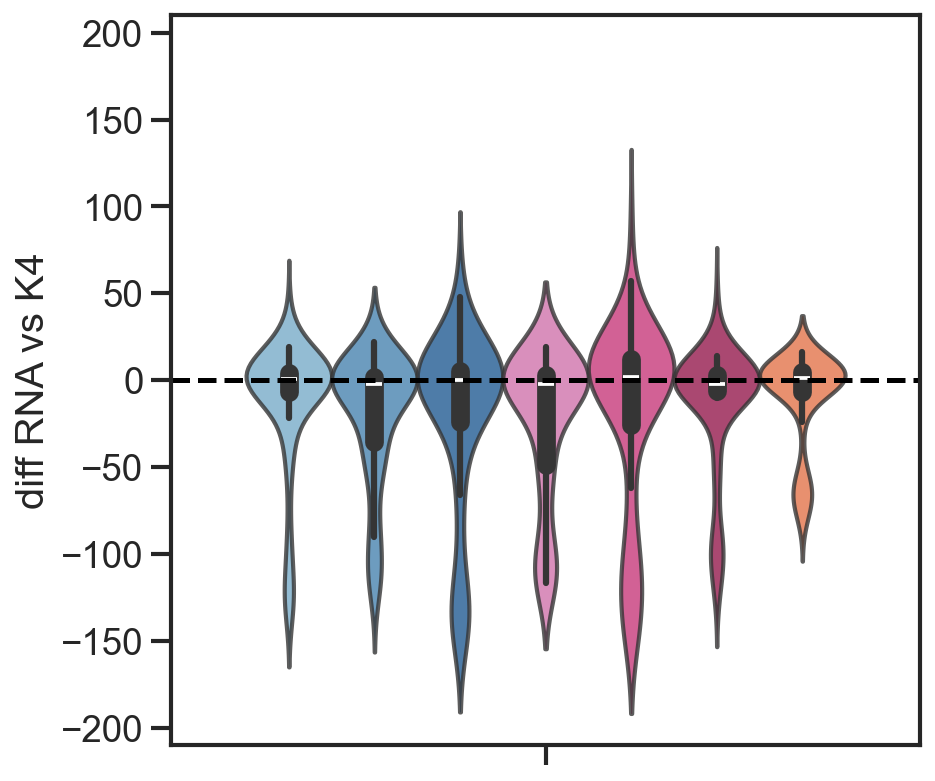

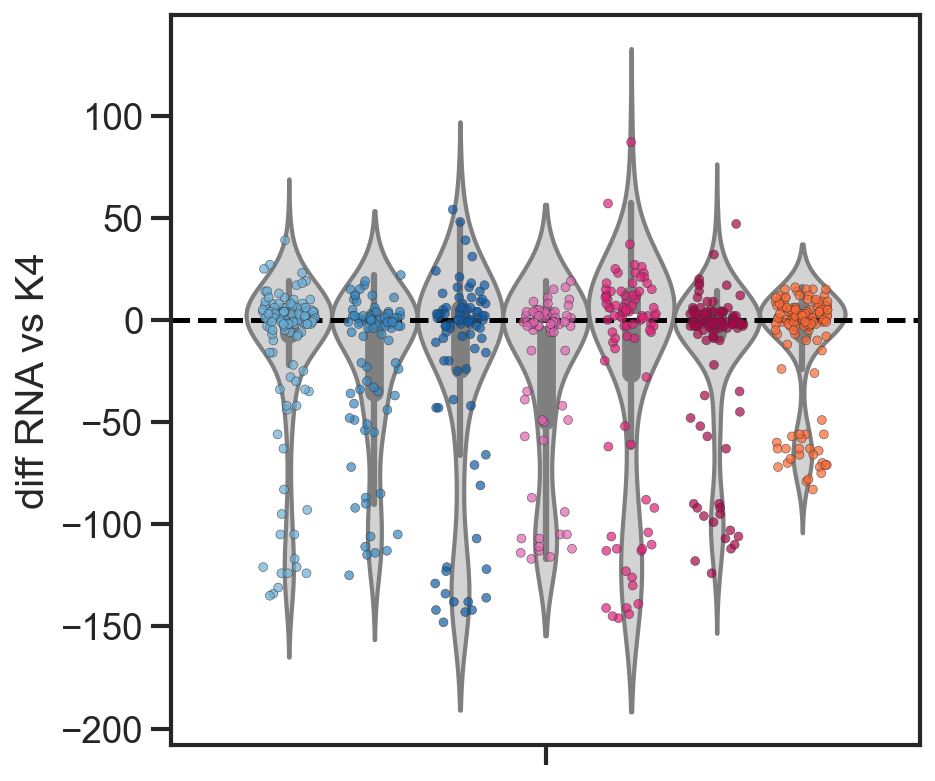

In [165]:
d1 = calculateDiff(ecto_changes_f,'ect1',keep = 'first',mark = 'K4')
d2 = calculateDiff(ecto_changes_f,'ect2',keep = 'first',mark = 'K4')
d3 = calculateDiff(ecto_changes_f,'ect3',keep = 'first',mark = 'K4')

d4 = calculateDiff(meso_changes_f,'mes1',keep = 'first',mark = 'K4')
d5 = calculateDiff(meso_changes_f,'mes2',keep = 'first',mark = 'K4')
d6 = calculateDiff(meso_changes_f,'mes3',keep = 'first',mark = 'K4')

d7 = calculateDiff(endo_changes_f,'endo1',keep = 'first',mark = 'K4')

pal = ['#6AAED6', '#3787C0', '#105BA4', '#DF64AF', '#DF2179', '#A90649', '#FC6832',]
fig,ax = plt.subplots(figsize = (6,6))
sns.violinplot(data = pd.concat([d1,d2,d3,d4,d5,d6,d7]),ax=ax,
        y = 'diff', #fliersize = False,
               palette = pal,alpha = 0.8,
            hue = 'lin')
plt.legend([],frameon=False)
plt.axhline(0, linestyle = 'dashed', c = 'black')
plt.ylabel('diff RNA vs K4')
plt.ylim([-210, 210])
plt.savefig('figs/20250415_violinplot_deltaRNAvsK4_stdev_unfiltered.png',bbox_inches = 'tight')
plt.show()

fig,ax = plt.subplots(figsize = (6,6))
sns.violinplot(data = pd.concat([d1,d2,d3,d4,d5,d6,d7]),ax=ax,
        y = 'diff', #fliersize = False,
               palette = ['lightgrey'],
            hue = 'lin')
sns.stripplot(data = pd.concat([d1,d2,d3,d4,d5,d6,d7]),ax=ax,
        y = 'diff',palette = pal,dodge = True, size = 4, alpha = 0.7, jitter = 0.25,linewidth = 0.3,
            hue = 'lin')
plt.legend([],frameon=False)
plt.axhline(0, linestyle = 'dashed', c = 'black')
plt.ylabel('diff RNA vs K4')
#plt.savefig('figs/20250306_barplot_deltaRNAvsK27_fix.png',bbox_inches = 'tight')
plt.show()

In [166]:
endo_K27RNA_changing = list(pd.DataFrame(endo_changes_f[endo_changes_f['layer'] != 'K4'][['gene','lin']].value_counts()[endo_changes_f[endo_changes_f['layer'] != 'K4'][['gene','lin']].value_counts() == 2]).reset_index()['gene'].unique())
meso_K27RNA_changing = list(pd.DataFrame(meso_changes_f[meso_changes_f['layer'] != 'K4'][['gene','lin']].value_counts()[meso_changes_f[meso_changes_f['layer'] != 'K4'][['gene','lin']].value_counts() == 2]).reset_index()['gene'].unique())
ecto_K27RNA_changing = list(pd.DataFrame(ecto_changes_f[ecto_changes_f['layer'] != 'K4'][['gene','lin']].value_counts()[ecto_changes_f[ecto_changes_f['layer'] != 'K4'][['gene','lin']].value_counts() == 2]).reset_index()['gene'].unique())

endo_K4RNA_changing = list(pd.DataFrame(endo_changes_f[endo_changes_f['layer'] != 'K27'][['gene','lin']].value_counts()[endo_changes_f[endo_changes_f['layer'] != 'K27'][['gene','lin']].value_counts() == 2]).reset_index()['gene'].unique())
meso_K4RNA_changing = list(pd.DataFrame(meso_changes_f[meso_changes_f['layer'] != 'K27'][['gene','lin']].value_counts()[meso_changes_f[meso_changes_f['layer'] != 'K27'][['gene','lin']].value_counts() == 2]).reset_index()['gene'].unique())
ecto_K4RNA_changing = list(pd.DataFrame(ecto_changes_f[ecto_changes_f['layer'] != 'K27'][['gene','lin']].value_counts()[ecto_changes_f[ecto_changes_f['layer'] != 'K27'][['gene','lin']].value_counts() == 2]).reset_index()['gene'].unique())

endo_allchanging = list(pd.DataFrame(endo_changes_f[['gene','lin']].value_counts()[endo_changes_f[['gene','lin']].value_counts() == 3]).reset_index()['gene'].unique())
meso_allchanging = list(pd.DataFrame(meso_changes_f[['gene','lin']].value_counts()[meso_changes_f[['gene','lin']].value_counts() == 3]).reset_index()['gene'].unique())
ecto_allchanging = list(pd.DataFrame(ecto_changes_f[['gene','lin']].value_counts()[ecto_changes_f[['gene','lin']].value_counts() == 3]).reset_index()['gene'].unique())

print(len(endo_K27RNA_changing), len(meso_K27RNA_changing),len(ecto_K27RNA_changing))

427 300 227


In [167]:
from matplotlib_venn import venn3, venn3_circles

def makeVennOverlap(df,lin):
    A = df[(df['layer'] == 'RNA') &(df['lin'] == lin)]['gene'].unique()
    B = df[(df['layer'] == 'K4') &(df['lin'] == lin)]['gene'].unique()
    C = df[(df['layer'] == 'K27') &(df['lin'] == lin)]['gene'].unique()
    
    fig,ax = plt.subplots(figsize = (3,3))
    venn3([set(A),set(B),set(C)],ax=ax, set_colors = [Orange,Green,Purple],
          set_labels = ['RNA','K4','K27'],
          alpha = 0.7)
    c = venn3_circles([set(A),set(B),set(C)],color = 'black',linewidth = 1,ax=ax, 
          alpha = 0.6)
    plt.title(lin)
    plt.savefig('figs/20250415_venn_overlap_stdevchanges_per_modality_' + str(lin) + '.png',bbox_inches='tight')
    plt.show()

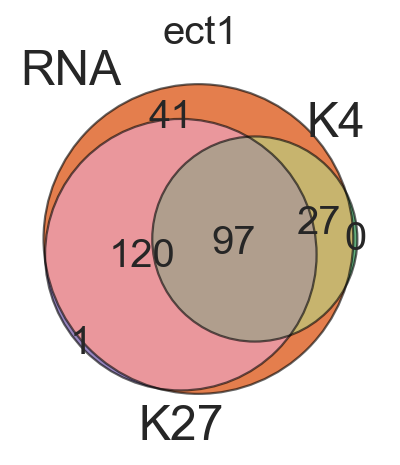

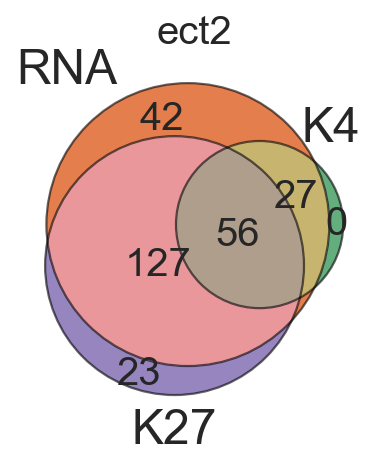

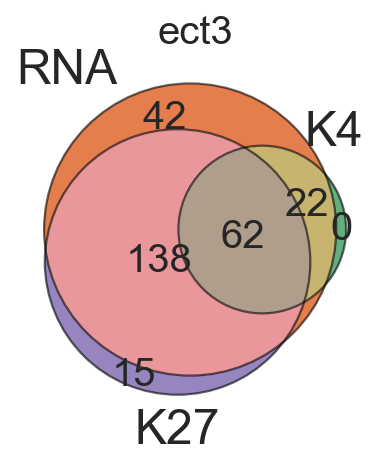

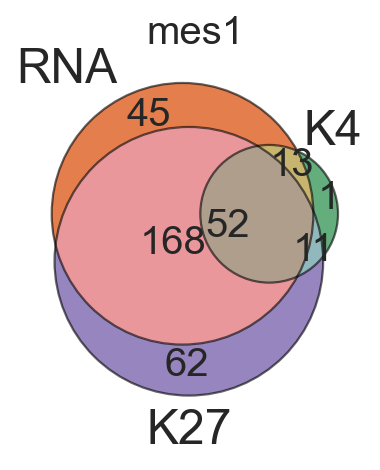

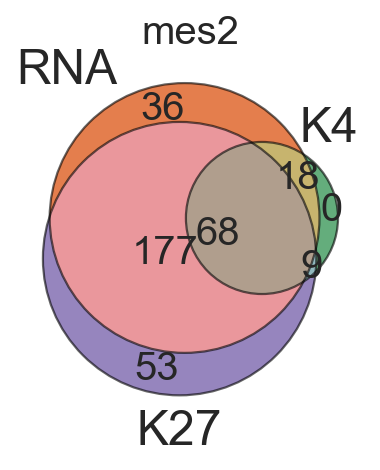

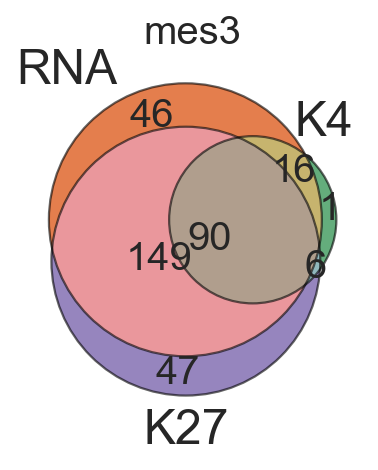

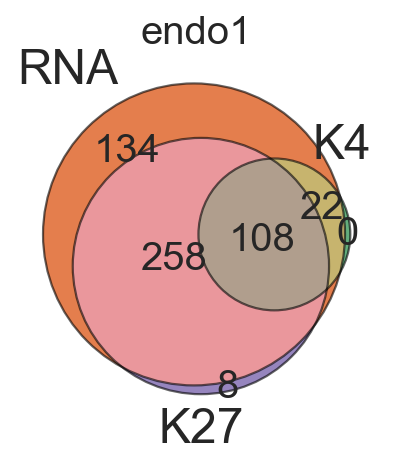

In [168]:
makeVennOverlap(ecto_changes_f,'ect1')
makeVennOverlap(ecto_changes_f,'ect2')
makeVennOverlap(ecto_changes_f,'ect3')

makeVennOverlap(meso_changes_f,'mes1')
makeVennOverlap(meso_changes_f,'mes2')
makeVennOverlap(meso_changes_f,'mes3')

makeVennOverlap(endo_changes_f,'endo1')

In [169]:
def plotChanges(df,lin,keep='first',save = None, xaxis = 'step'):
    df['dup'] = df['lin_layer'] + '_' + df['gene']
    df_unique = df[~df['dup'].duplicated(keep = keep)]
    fig,ax = plt.subplots(3,1, figsize = (6,4),gridspec_kw = {'wspace':0, 'hspace':0.05})
    sns.histplot(df_unique[(df_unique['lin'] == lin) & (df_unique['layer'] == 'RNA')][xaxis],
                ax=ax[0], color= Orange, binwidth=2.5)
    sns.histplot(df_unique[(df_unique['lin'] == lin) & (df_unique['layer'] == 'K4')][xaxis],
                ax=ax[1], color= Green,binwidth = 2.5)
    sns.histplot(df_unique[(df_unique['lin'] == lin) & (df_unique['layer'] == 'K27')][xaxis],
                ax=ax[2], color= Purple, binwidth=2.5)
    dict1 = {}
    for x in df['lin_layer'].unique():
        dict1[x] = df[df['lin_layer'] == x]['step'].max()
    for x in range(3):
        ax[x].set_xlim([0,dict1[lin+'_RNA']+5])
        ax[x].set_xticks([])
        ax[x].set_xlabel('')
        ax[x].set_yticks([])
        ax[x].set_ylabel('')
        ax[x].set_ylim([0,80])
    ax[1].set_ylim([0,40])
    if save != None:
        plt.savefig(save,bbox_inches='tight')
    plt.show()

def plotChangesRT(df,lin,keep='first',save = None, xaxis = 'RT'):
    df['dup'] = df['lin_layer'] + '_' + df['gene']
    df_unique = df[~df['dup'].duplicated(keep = keep)]
    fig,ax = plt.subplots(3,1, figsize = (5,3),gridspec_kw = {'wspace':0, 'hspace':0.05})
    sns.histplot(df_unique[(df_unique['lin'] == lin) & (df_unique['layer'] == 'RNA')][xaxis],
                ax=ax[0], color= Orange, binwidth=2.5)
    sns.histplot(df_unique[(df_unique['lin'] == lin) & (df_unique['layer'] == 'K4')][xaxis],
                ax=ax[1], color= Green,binwidth = 2.5)
    sns.histplot(df_unique[(df_unique['lin'] == lin) & (df_unique['layer'] == 'K27')][xaxis],
                ax=ax[2], color= Purple, binwidth=2.5)
    #dict1 = {}
    #for x in df['lin_layer'].unique():
    #    dict1[x] = df[df['lin_layer'] == x]['step'].max()
    for x in range(3):
     #   ax[x].set_xlim([0,dict1[lin+'_RNA']+5])
        ax[x].set_xticks([])
        ax[x].set_xlabel('')
        ax[x].set_yticks([])
        ax[x].set_ylabel('')
    ax[2].set_ylim([0,300])
    ax[1].set_ylim([0,100])
    ax[0].set_ylim([0,250])
    if save != None:
        plt.savefig(save,bbox_inches='tight')
    plt.show()



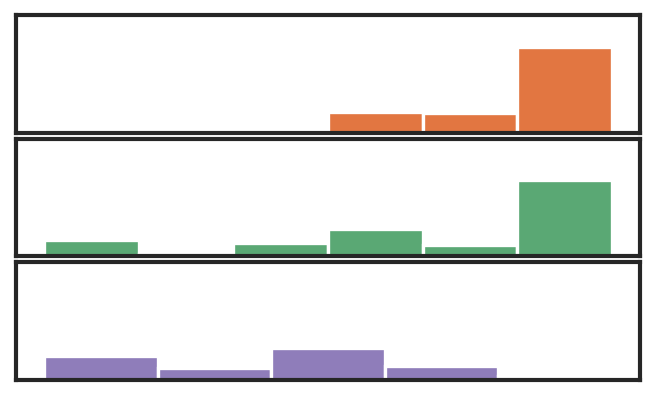

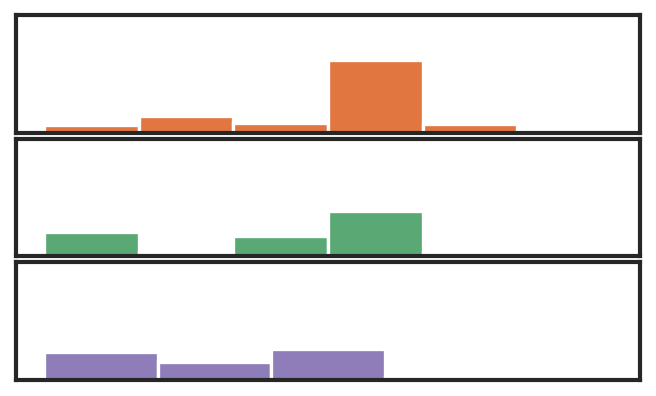

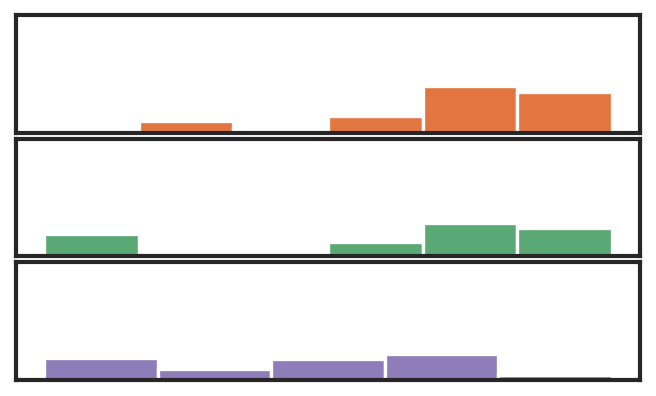

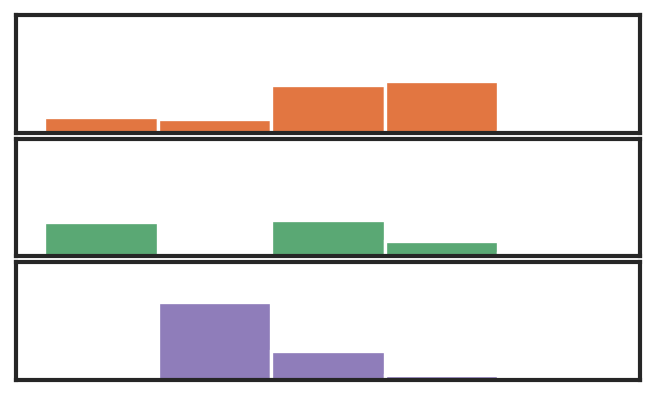

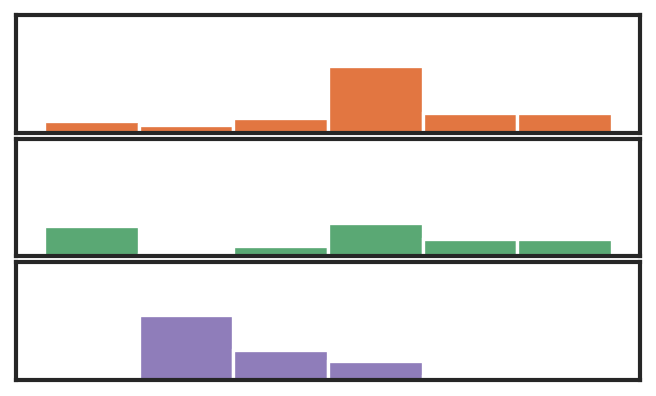

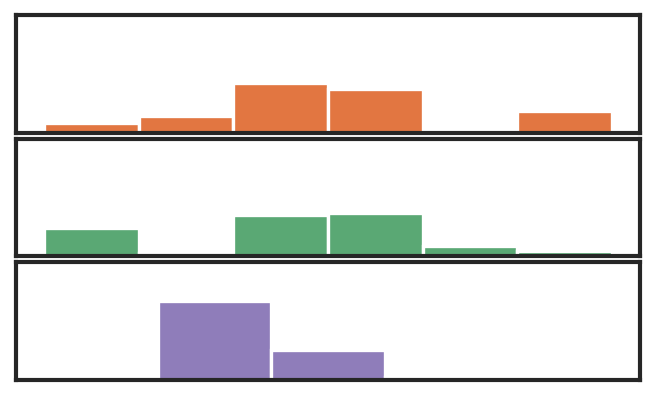

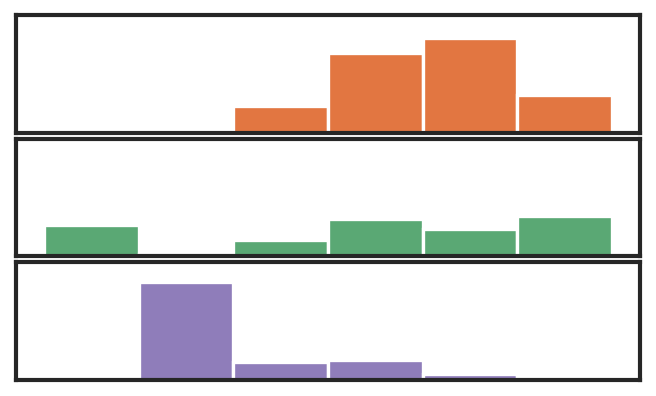

In [242]:
plotChangesRT(ecto_changes_f,'ect1',save = 'figs/20250415_histplot_changes_stdev_RT_ect1.png', xaxis = 'RT')
plotChangesRT(ecto_changes_f,'ect2',save = 'figs/20250415_histplot_changes_stdev_RT_ect2.png', xaxis = 'RT')
plotChangesRT(ecto_changes_f,'ect3',save = 'figs/20250415_histplot_changes_stdev_RT_ect3.png', xaxis = 'RT')

plotChangesRT(meso_changes_f,'mes1',save = 'figs/20250415_histplot_changes_stdev_RT_mes1.png', xaxis = 'RT')
plotChangesRT(meso_changes_f,'mes2',save = 'figs/20250415_histplot_changes_stdev_RT_mes2.png', xaxis = 'RT')
plotChangesRT(meso_changes_f,'mes3',save = 'figs/20250415_histplot_changes_stdev_RT_mes3.png', xaxis = 'RT')

plotChangesRT(endo_changes_f,'endo1',save = 'figs/20250415_histplot_changes_stdev_RT_end1.png', xaxis = 'RT')

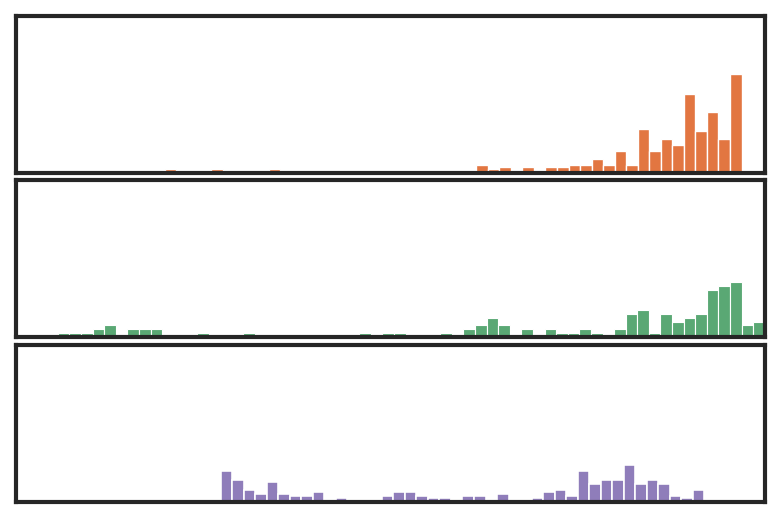

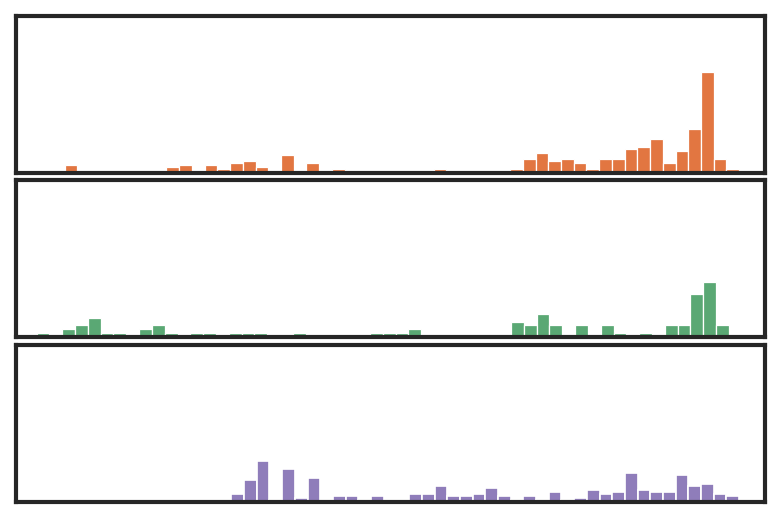

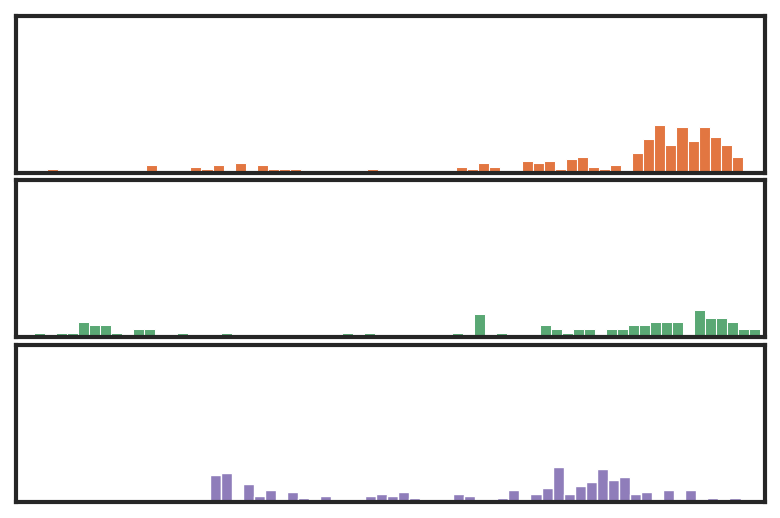

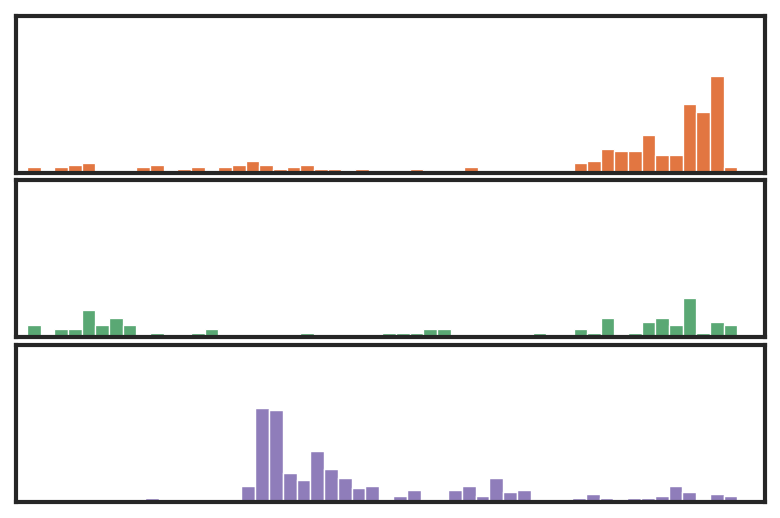

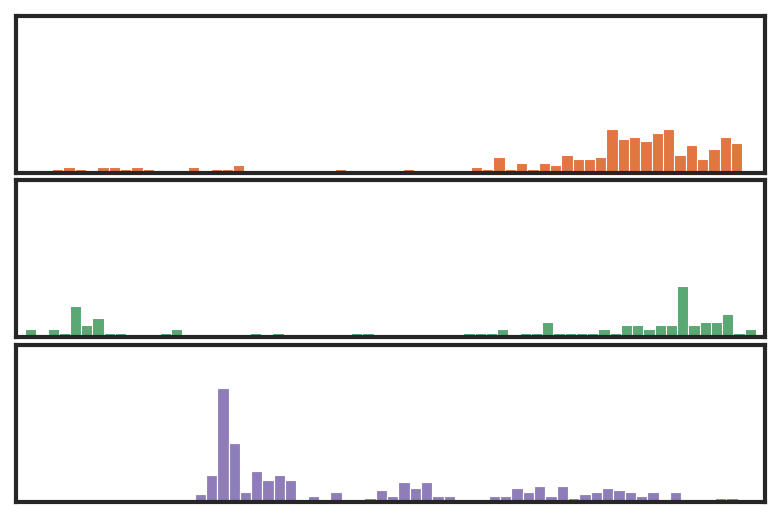

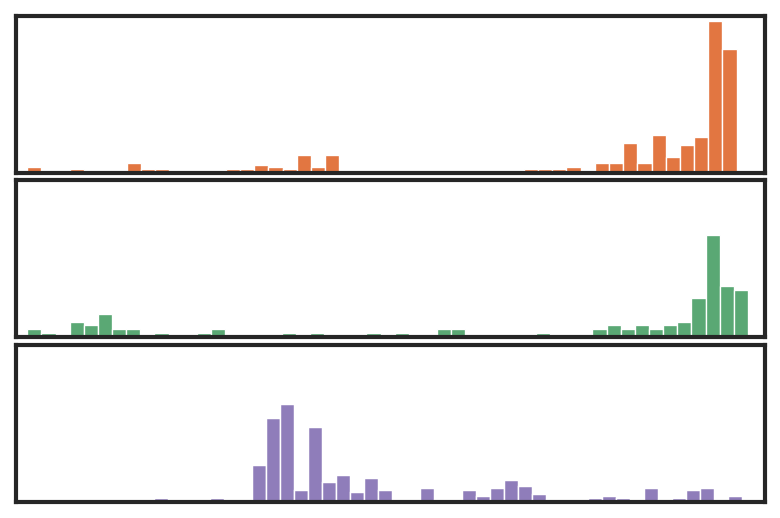

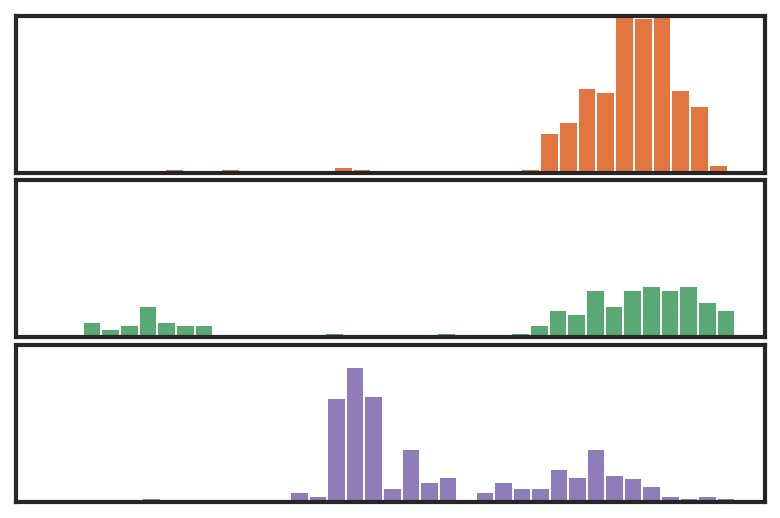

In [170]:
plotChanges(ecto_changes_f,'ect1',save = 'figs/20250417_histplot_changes_stdev_ect1.png')
plotChanges(ecto_changes_f,'ect2',save = 'figs/20250417_histplot_changes_stdev_ect2.png')
plotChanges(ecto_changes_f,'ect3',save = 'figs/20250417_histplot_changes_stdev_ect3.png')

plotChanges(meso_changes_f,'mes1',save = 'figs/20250417_histplot_changes_stdev_mes1.png')
plotChanges(meso_changes_f,'mes2',save = 'figs/20250417_histplot_changes_stdev_mes2.png')
plotChanges(meso_changes_f,'mes3',save = 'figs/20250417_histplot_changes_stdev_mes3.png')

plotChanges(endo_changes_f,'endo1',save = 'figs/20250417_histplot_changes_stdev_end1.png')

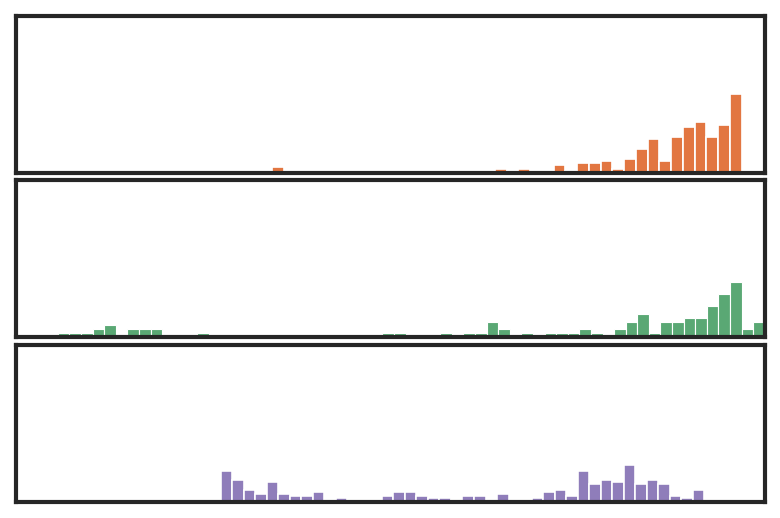

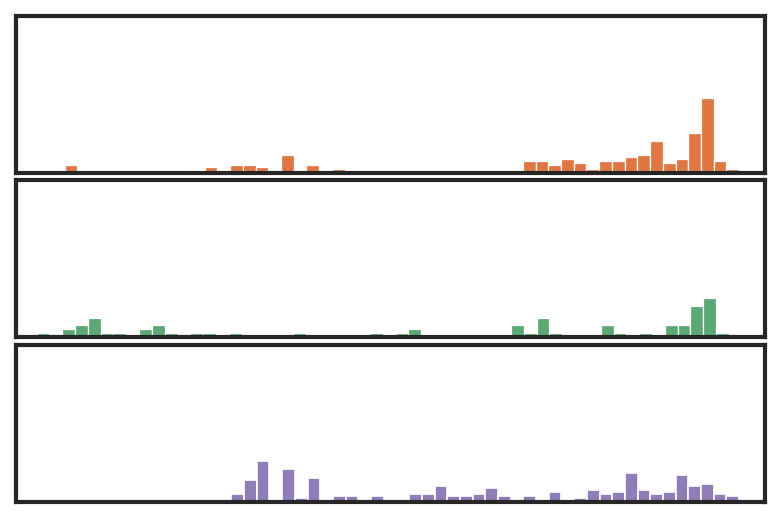

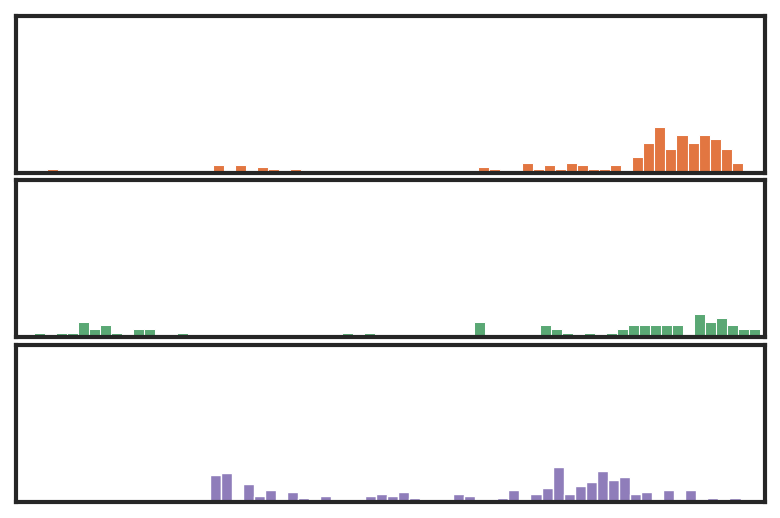

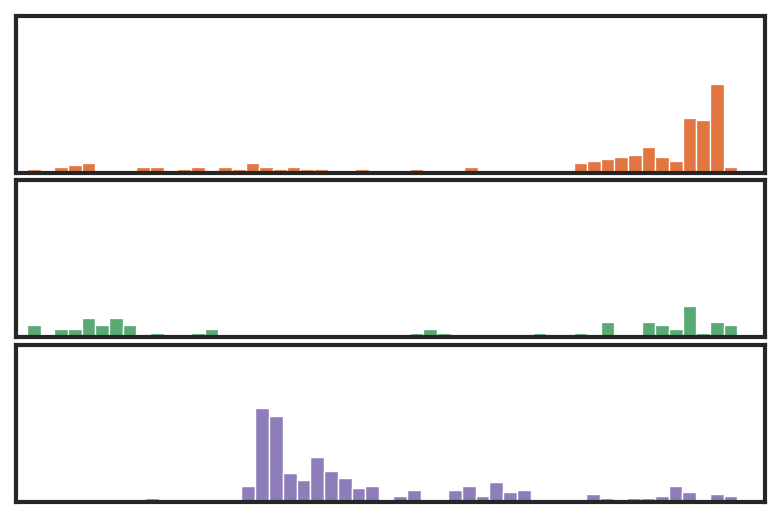

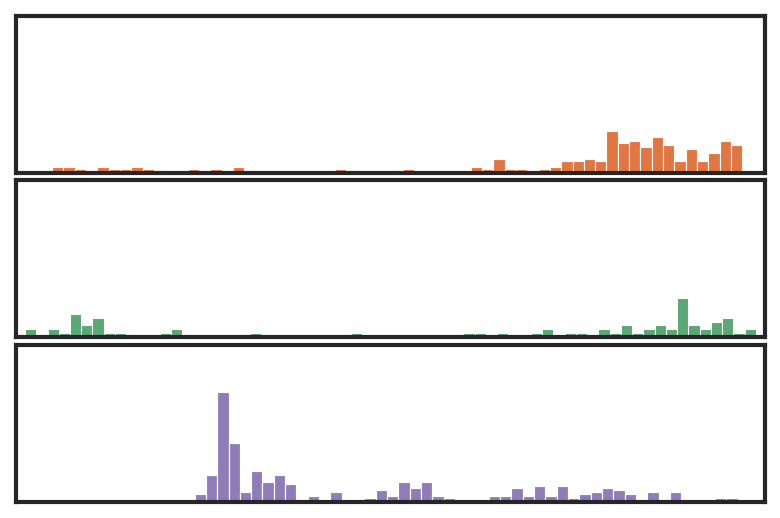

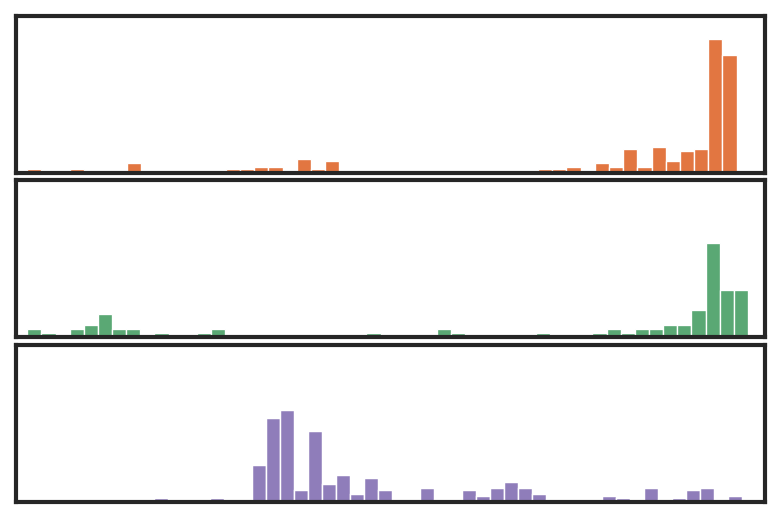

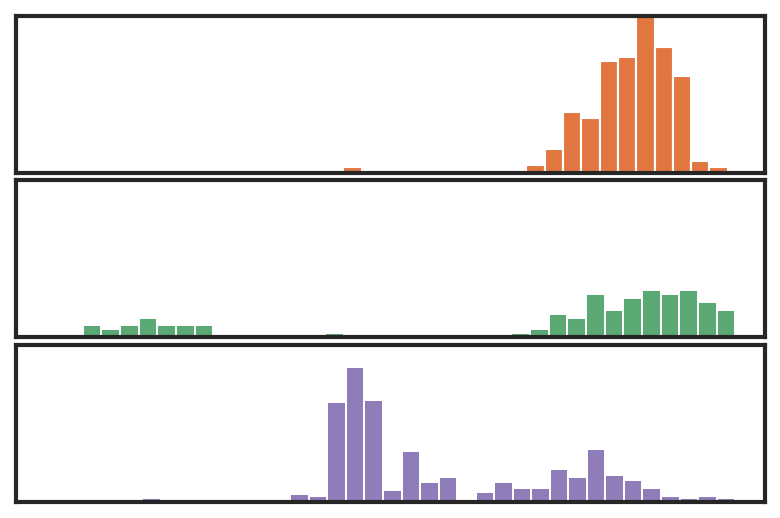

In [202]:
plotChanges(ecto_changes_f[ecto_changes_f['gene'].isin(ecto_K27RNA_changing)],'ect1',save = 'figs/20250415_histplot_changes_stdev_K27RNA_ect1.png')
plotChanges(ecto_changes_f[ecto_changes_f['gene'].isin(ecto_K27RNA_changing)],'ect2',save = 'figs/20250415_histplot_changes_stdev_K27RNA_ect2.png')
plotChanges(ecto_changes_f[ecto_changes_f['gene'].isin(ecto_K27RNA_changing)],'ect3',save = 'figs/20250415_histplot_changes_stdev_K27RNA_ect3.png')

plotChanges(meso_changes_f[meso_changes_f['gene'].isin(meso_K27RNA_changing)],'mes1',save = 'figs/20250415_histplot_changes_stdev_K27RNA_mes1.png')
plotChanges(meso_changes_f[meso_changes_f['gene'].isin(meso_K27RNA_changing)],'mes2',save = 'figs/20250415_histplot_changes_stdev_K27RNA_mes2.png')
plotChanges(meso_changes_f[meso_changes_f['gene'].isin(meso_K27RNA_changing)],'mes3',save = 'figs/20250415_histplot_changes_stdev_K27RNA_mes3.png')

plotChanges(endo_changes_f[endo_changes_f['gene'].isin(endo_K27RNA_changing)],'endo1',save = 'figs/20250415_histplot_changes_stdev__K27RNA_end1.png')

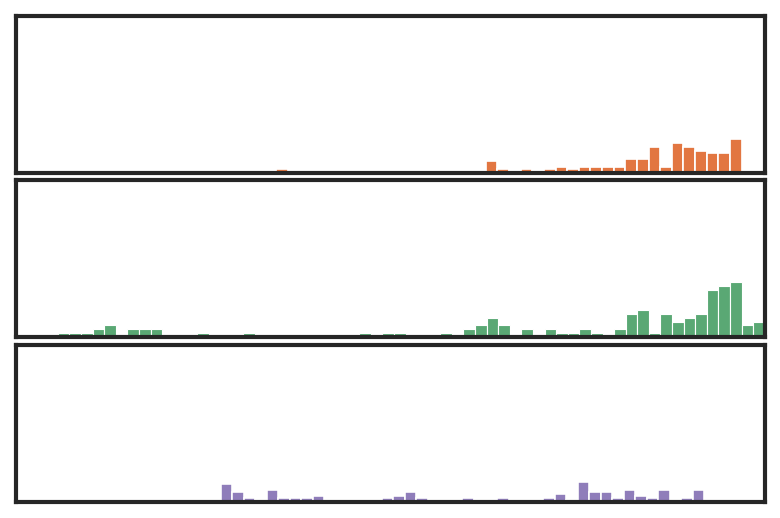

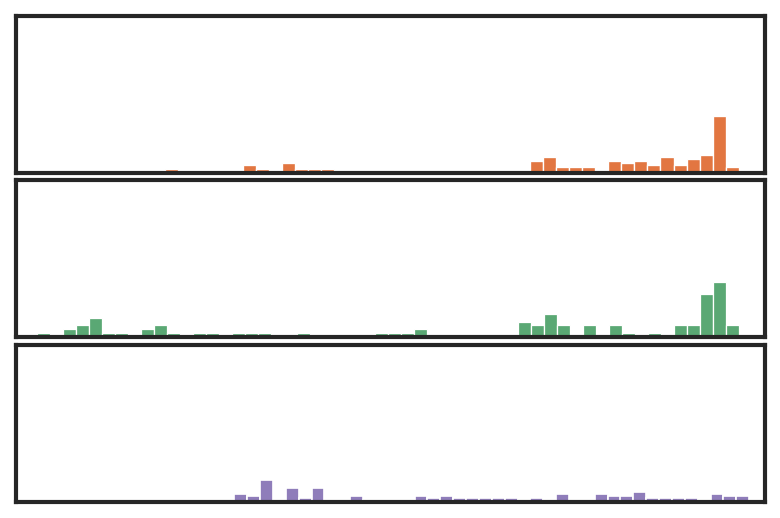

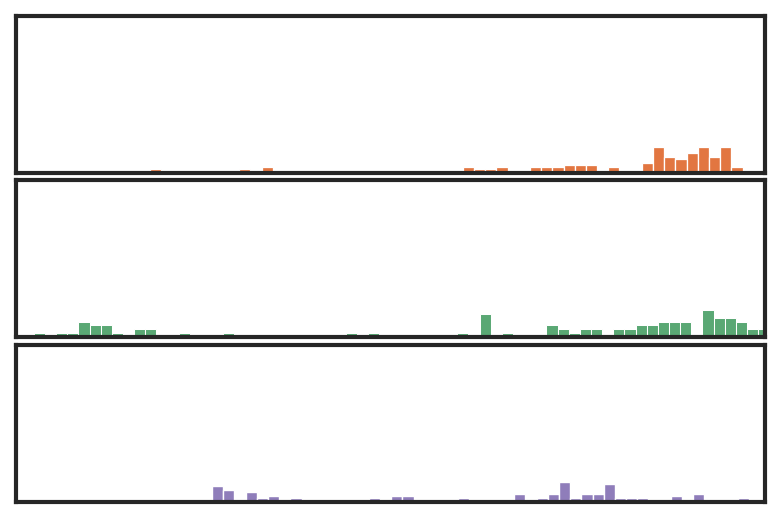

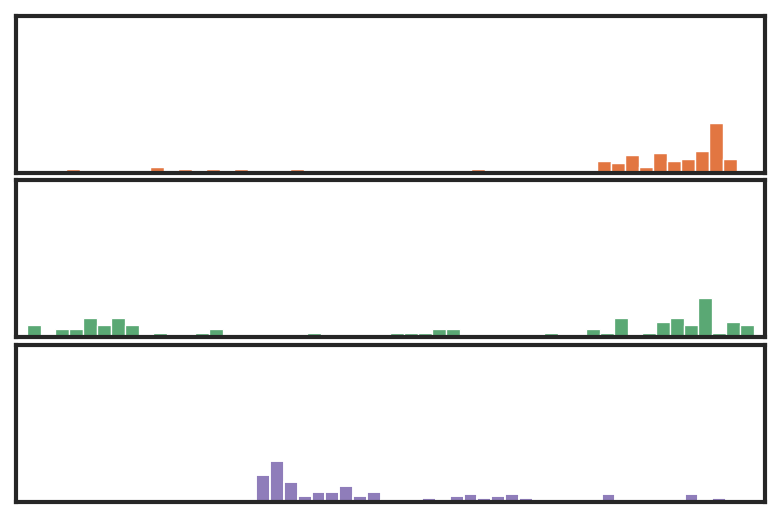

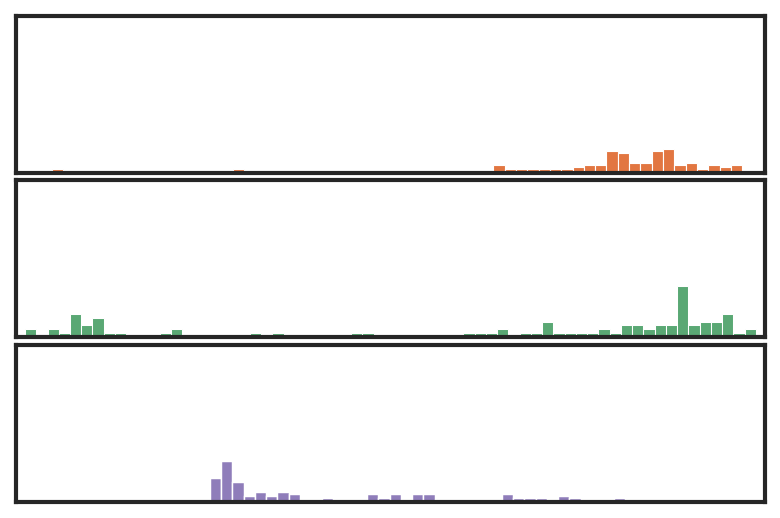

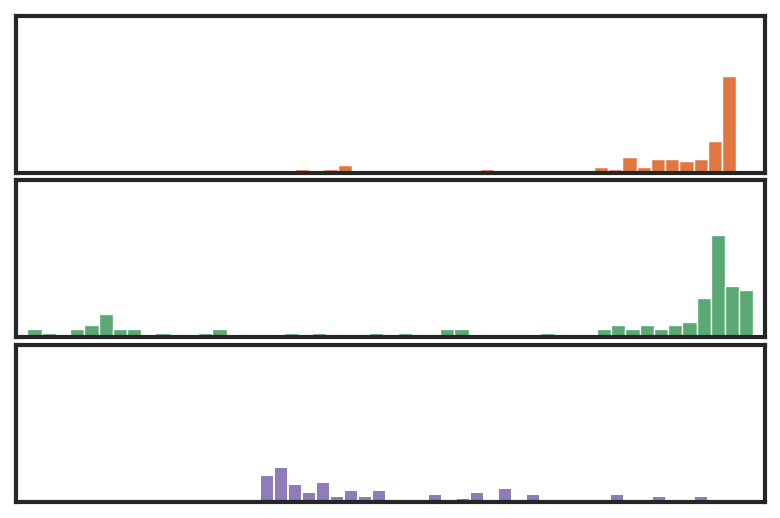

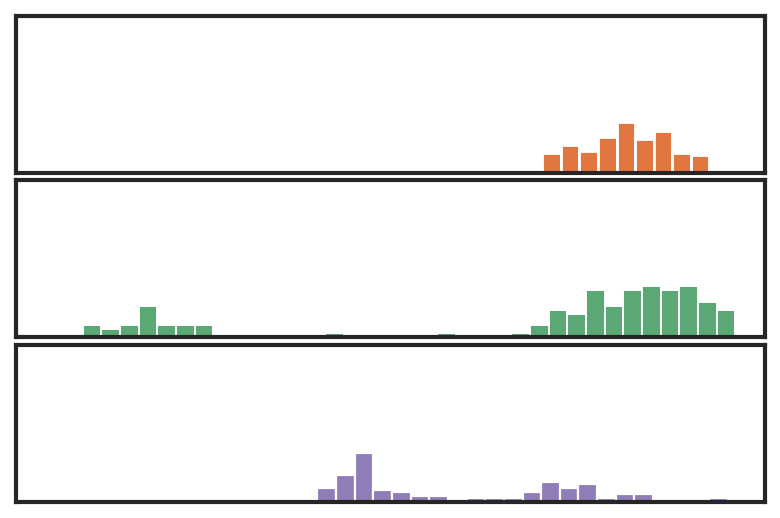

In [203]:
plotChanges(ecto_changes_f[ecto_changes_f['gene'].isin(ecto_K4RNA_changing)],'ect1',save = 'figs/20250415_histplot_changes_stdev_K4RNA_ect1.png')
plotChanges(ecto_changes_f[ecto_changes_f['gene'].isin(ecto_K4RNA_changing)],'ect2',save = 'figs/20250415_histplot_changes_stdev_K4RNA_ect2.png')
plotChanges(ecto_changes_f[ecto_changes_f['gene'].isin(ecto_K4RNA_changing)],'ect3',save = 'figs/20250415_histplot_changes_stdev_K4RNA_ect3.png')

plotChanges(meso_changes_f[meso_changes_f['gene'].isin(meso_K4RNA_changing)],'mes1',save = 'figs/20250415_histplot_changes_stdev_K4RNA_mes1.png')
plotChanges(meso_changes_f[meso_changes_f['gene'].isin(meso_K4RNA_changing)],'mes2',save = 'figs/20250415_histplot_changes_stdev_K4RNA_mes2.png')
plotChanges(meso_changes_f[meso_changes_f['gene'].isin(meso_K4RNA_changing)],'mes3',save = 'figs/20250415_histplot_changes_stdev_K4RNA_mes3.png')

plotChanges(endo_changes_f[endo_changes_f['gene'].isin(endo_K4RNA_changing)],'endo1',save = 'figs/20250415_histplot_changes_stdev__K4RNA_end1.png')

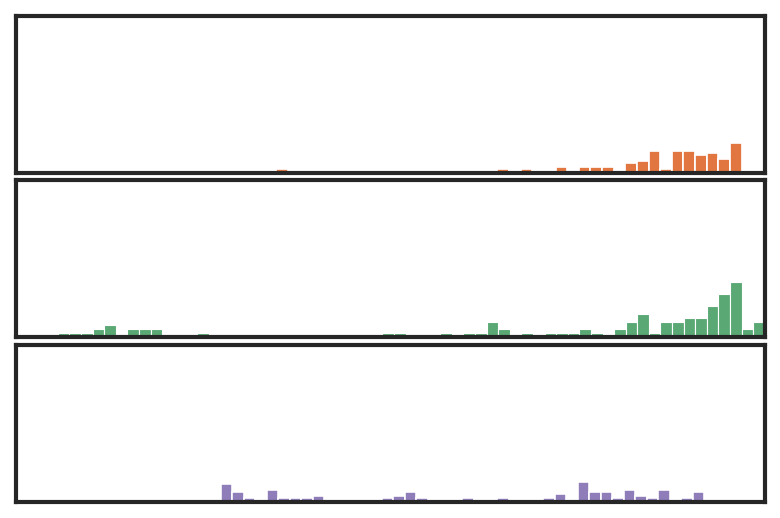

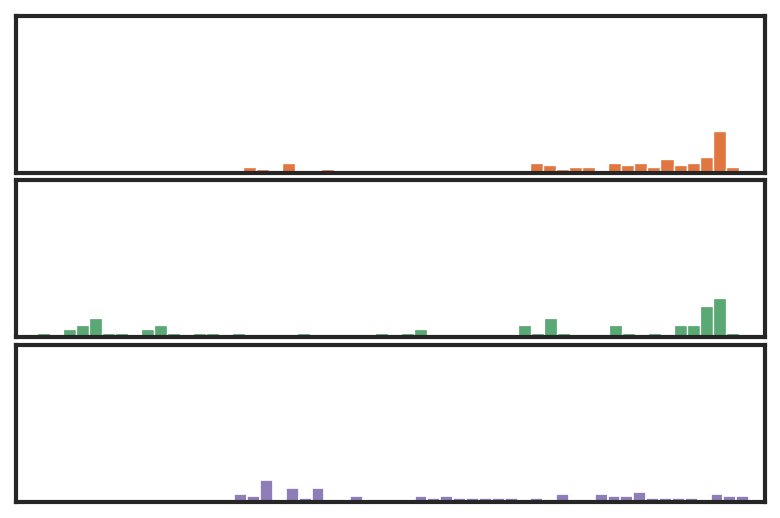

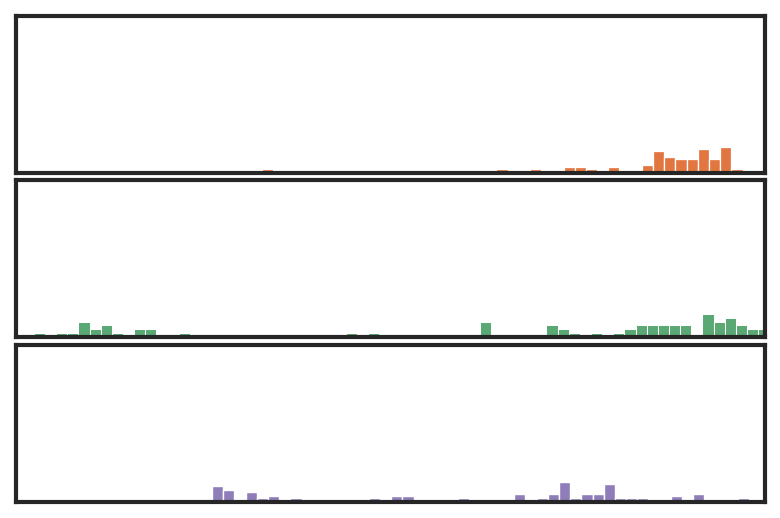

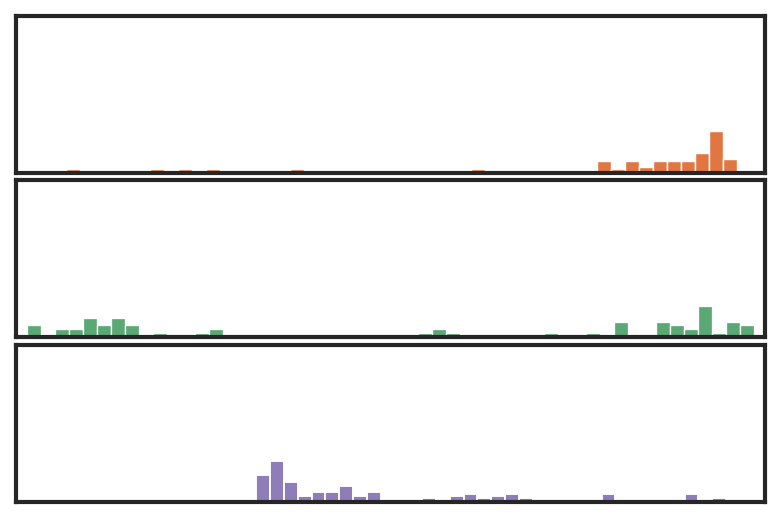

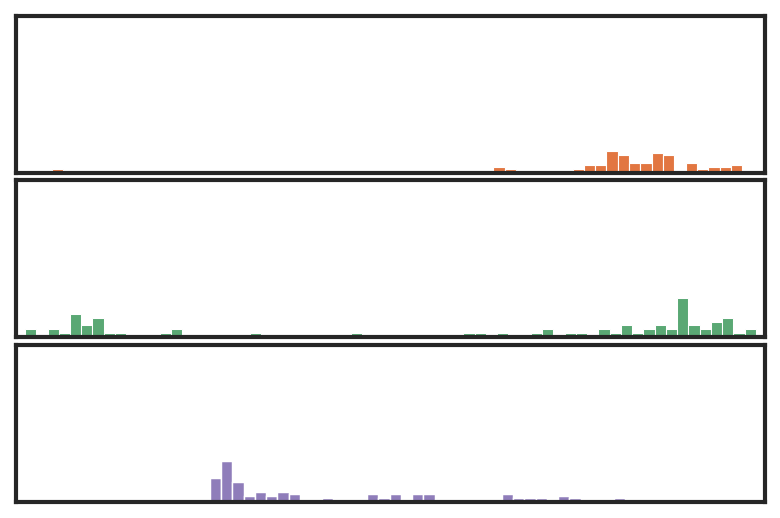

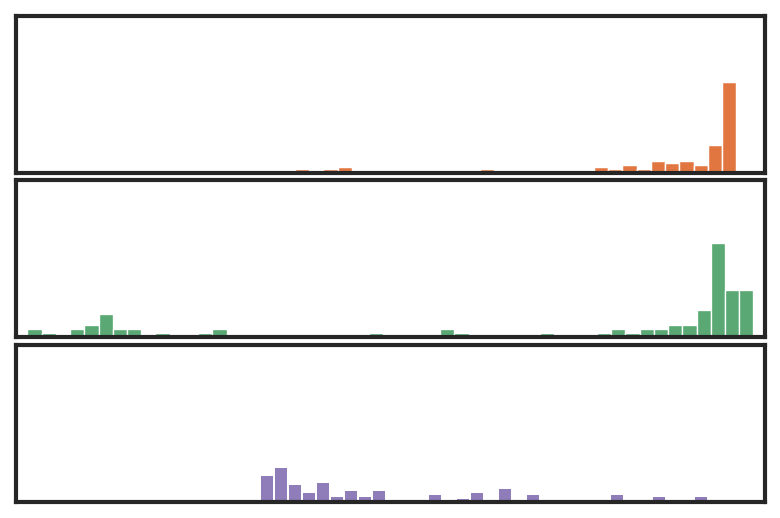

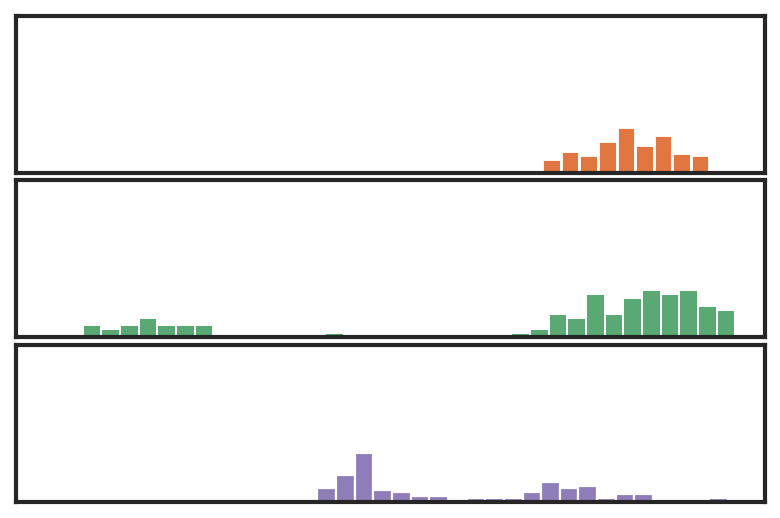

In [206]:
plotChanges(ecto_changes_f[ecto_changes_f['gene'].isin(ecto_allchanging)],'ect1',save = 'figs/20250415_histplot_changes_stdev_all_ect1.png')
plotChanges(ecto_changes_f[ecto_changes_f['gene'].isin(ecto_allchanging)],'ect2',save = 'figs/20250415_histplot_changes_stdev_all_ect2.png')
plotChanges(ecto_changes_f[ecto_changes_f['gene'].isin(ecto_allchanging)],'ect3',save = 'figs/20250415_histplot_changes_stdev_all_ect3.png')

plotChanges(meso_changes_f[meso_changes_f['gene'].isin(meso_allchanging)],'mes1',save = 'figs/20250415_histplot_changes_stdev_all_mes1.png')
plotChanges(meso_changes_f[meso_changes_f['gene'].isin(meso_allchanging)],'mes2',save = 'figs/20250415_histplot_changes_stdev_all_mes2.png')
plotChanges(meso_changes_f[meso_changes_f['gene'].isin(meso_allchanging)],'mes3',save = 'figs/20250415_histplot_changes_stdev_all_mes3.png')

plotChanges(endo_changes_f[endo_changes_f['gene'].isin(endo_allchanging)],'endo1',save = 'figs/20250415_histplot_changes_stdev__all_end1.png')

# sources and targets

In [96]:
all_source_target_genes = np.load('../dfs/source_target_genes.npy',allow_pickle='TRUE').item()

In [97]:
all_source_target_genes.keys()

dict_keys(['ect_source', 'ect_target', 'mes_source', 'mes_target', 'end_source', 'end_target', 'plu_source', 'plu_target'])

In [98]:
d4 = calculateDiff(meso_changes_f,'mes1',keep = 'first')
#d4 = d4[d4.index.isin(list(all_source_target_genes['mes_source']))]
d4

,rna,K27,diff,lin
gene,,,,
Mc2r,2,41,39,mes1
Fzd4,4,60,56,mes1
Myocos,9,43,34,mes1
Gng11,9,73,64,mes1
Nlrc3,10,42,32,mes1
...,...,...,...,...
Smyd1,129,44,-85,mes1
Ppfibp2,129,46,-83,mes1
Col6a1,130,47,-83,mes1


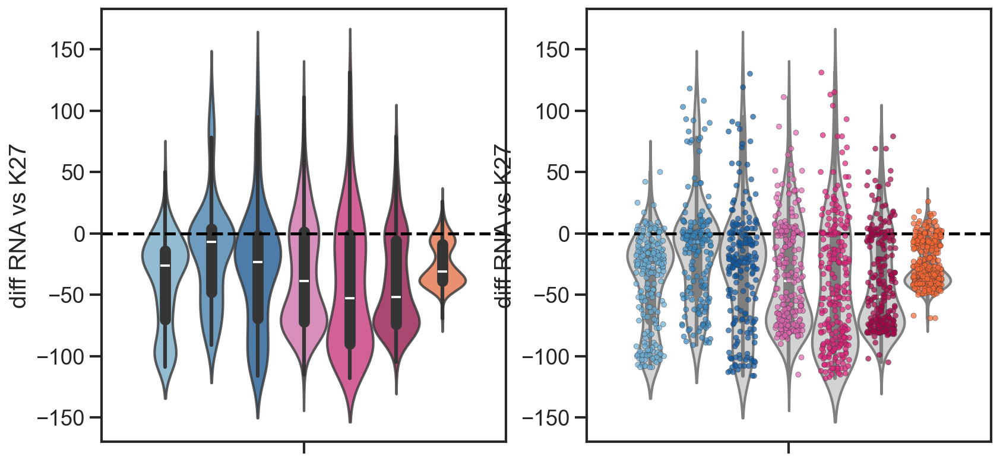

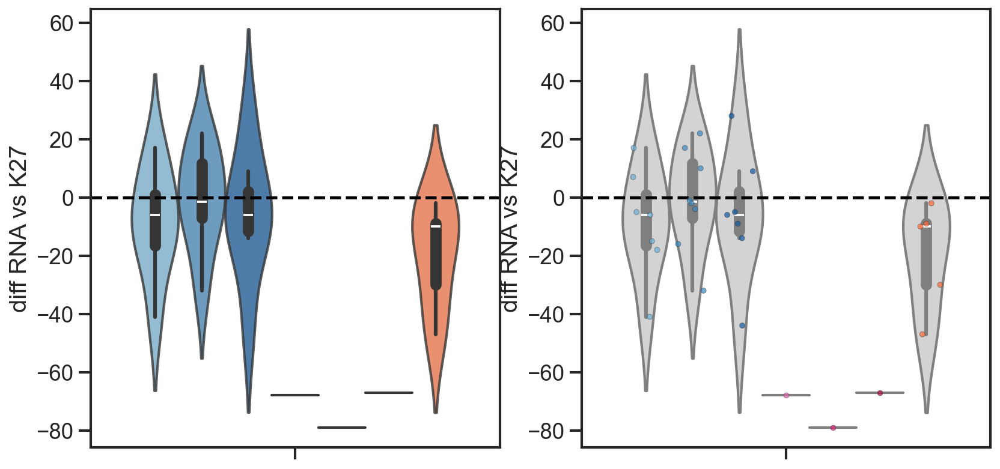

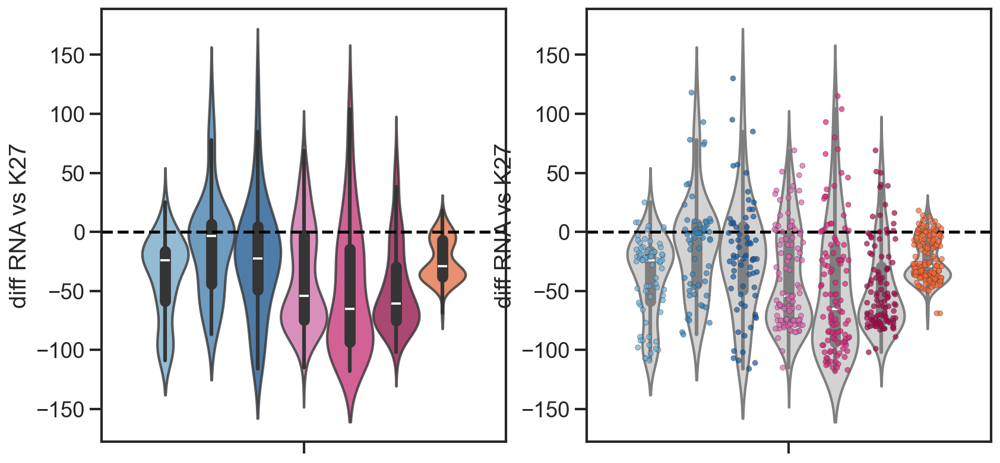

In [99]:
d1 = calculateDiff(ecto_changes_f,'ect1',keep = 'first')
d2 = calculateDiff(ecto_changes_f,'ect2',keep = 'first')
d3 = calculateDiff(ecto_changes_f,'ect3',keep = 'first')

d4 = calculateDiff(meso_changes_f,'mes1',keep = 'first')
d5 = calculateDiff(meso_changes_f,'mes2',keep = 'first')
d6 = calculateDiff(meso_changes_f,'mes3',keep = 'first')

d7 = calculateDiff(endo_changes_f,'endo1',keep = 'first')

pal = ['#6AAED6', '#3787C0', '#105BA4', '#DF64AF', '#DF2179', '#A90649', '#FC6832',]
fig,ax = plt.subplots(1,2,figsize = (12,6))
sns.violinplot(data = pd.concat([d1,d2,d3,d4,d5,d6,d7]),ax=ax[0],
        y = 'diff', #fliersize = False,
               palette = pal,alpha = 0.8,
            hue = 'lin')
ax[0].legend([],frameon=False)
ax[0].axhline(0, linestyle = 'dashed', c = 'black')
ax[0].set_ylabel('diff RNA vs K27')
#plt.savefig('figs/20250409_barplot_deltaRNAvsK27_stdev.png',bbox_inches = 'tight')
sns.violinplot(data = pd.concat([d1,d2,d3,d4,d5,d6,d7]),ax=ax[1],
        y = 'diff', #fliersize = False,
               palette = ['lightgrey'],
            hue = 'lin')
sns.stripplot(data = pd.concat([d1,d2,d3,d4,d5,d6,d7]),ax=ax[1],
        y = 'diff',palette = pal,dodge = True, size = 4, alpha = 0.7, jitter = 0.25,linewidth = 0.3,
            hue = 'lin')
ax[1].legend([],frameon=False)
ax[1].axhline(0, linestyle = 'dashed', c = 'black')
ax[1].set_ylabel('diff RNA vs K27')
#plt.savefig('figs/20250306_barplot_deltaRNAvsK27_fix.png',bbox_inches = 'tight')
plt.show()

d1 = calculateDiff(ecto_changes_f,'ect1',keep = 'first')
d1 = d1[d1.index.isin(list(all_source_target_genes['ect_source']))]
d2 = calculateDiff(ecto_changes_f,'ect2',keep = 'first')
d2 = d2[d2.index.isin(list(all_source_target_genes['ect_source']))]
d3 = calculateDiff(ecto_changes_f,'ect3',keep = 'first')
d3 = d3[d3.index.isin(list(all_source_target_genes['ect_source']))]

d4 = calculateDiff(meso_changes_f,'mes1',keep = 'first')
d4 = d4[d4.index.isin(list(all_source_target_genes['mes_source']))]
d5 = calculateDiff(meso_changes_f,'mes2',keep = 'first')
d5 = d5[d5.index.isin(list(all_source_target_genes['mes_source']))]
d6 = calculateDiff(meso_changes_f,'mes3',keep = 'first')
d6 = d6[d6.index.isin(list(all_source_target_genes['mes_source']))]

d7 = calculateDiff(endo_changes_f,'endo1',keep = 'first')
d7 = d7[d7.index.isin(list(all_source_target_genes['end_source']))]

pal = ['#6AAED6', '#3787C0', '#105BA4', '#DF64AF', '#DF2179', '#A90649', '#FC6832',]
fig,ax = plt.subplots(1,2,figsize = (12,6))
sns.violinplot(data = pd.concat([d1,d2,d3,d4,d5,d6,d7]),ax=ax[0],
        y = 'diff', #fliersize = False,
               palette = pal,alpha = 0.8,
            hue = 'lin')
ax[0].legend([],frameon=False)
ax[0].axhline(0, linestyle = 'dashed', c = 'black')
ax[0].set_ylabel('diff RNA vs K27')
#plt.savefig('figs/20250409_barplot_deltaRNAvsK27_stdev.png',bbox_inches = 'tight')
sns.violinplot(data = pd.concat([d1,d2,d3,d4,d5,d6,d7]),ax=ax[1],
        y = 'diff', #fliersize = False,
               palette = ['lightgrey'],
            hue = 'lin')
sns.stripplot(data = pd.concat([d1,d2,d3,d4,d5,d6,d7]),ax=ax[1],
        y = 'diff',palette = pal,dodge = True, size = 4, alpha = 0.7, jitter = 0.25,linewidth = 0.3,
            hue = 'lin')
ax[1].legend([],frameon=False)
ax[1].axhline(0, linestyle = 'dashed', c = 'black')
ax[1].set_ylabel('diff RNA vs K27')
#plt.savefig('figs/20250306_barplot_deltaRNAvsK27_fix.png',bbox_inches = 'tight')
plt.show()

d1 = calculateDiff(ecto_changes_f,'ect1',keep = 'first')
d1 = d1[d1.index.isin(list(all_source_target_genes['ect_target']))]
d2 = calculateDiff(ecto_changes_f,'ect2',keep = 'first')
d2 = d2[d2.index.isin(list(all_source_target_genes['ect_target']))]
d3 = calculateDiff(ecto_changes_f,'ect3',keep = 'first')
d3 = d3[d3.index.isin(list(all_source_target_genes['ect_target']))]

d4 = calculateDiff(meso_changes_f,'mes1',keep = 'first')
d4 = d4[d4.index.isin(list(all_source_target_genes['mes_target']))]
d5 = calculateDiff(meso_changes_f,'mes2',keep = 'first')
d5 = d5[d5.index.isin(list(all_source_target_genes['mes_target']))]
d6 = calculateDiff(meso_changes_f,'mes3',keep = 'first')
d6 = d6[d6.index.isin(list(all_source_target_genes['mes_target']))]

d7 = calculateDiff(endo_changes_f,'endo1',keep = 'first')
d7 = d7[d7.index.isin(list(all_source_target_genes['end_target']))]

pal = ['#6AAED6', '#3787C0', '#105BA4', '#DF64AF', '#DF2179', '#A90649', '#FC6832',]
fig,ax = plt.subplots(1,2,figsize = (12,6))
sns.violinplot(data = pd.concat([d1,d2,d3,d4,d5,d6,d7]),ax=ax[0],
        y = 'diff', #fliersize = False,
               palette = pal,alpha = 0.8,
            hue = 'lin')
ax[0].legend([],frameon=False)
ax[0].axhline(0, linestyle = 'dashed', c = 'black')
ax[0].set_ylabel('diff RNA vs K27')
#plt.savefig('figs/20250409_barplot_deltaRNAvsK27_stdev.png',bbox_inches = 'tight')
sns.violinplot(data = pd.concat([d1,d2,d3,d4,d5,d6,d7]),ax=ax[1],
        y = 'diff', #fliersize = False,
               palette = ['lightgrey'],
            hue = 'lin')
sns.stripplot(data = pd.concat([d1,d2,d3,d4,d5,d6,d7]),ax=ax[1],
        y = 'diff',palette = pal,dodge = True, size = 4, alpha = 0.7, jitter = 0.25,linewidth = 0.3,
            hue = 'lin')
ax[1].legend([],frameon=False)
ax[1].axhline(0, linestyle = 'dashed', c = 'black')
ax[1].set_ylabel('diff RNA vs K27')
#plt.savefig('figs/20250306_barplot_deltaRNAvsK27_fix.png',bbox_inches = 'tight')
plt.show()

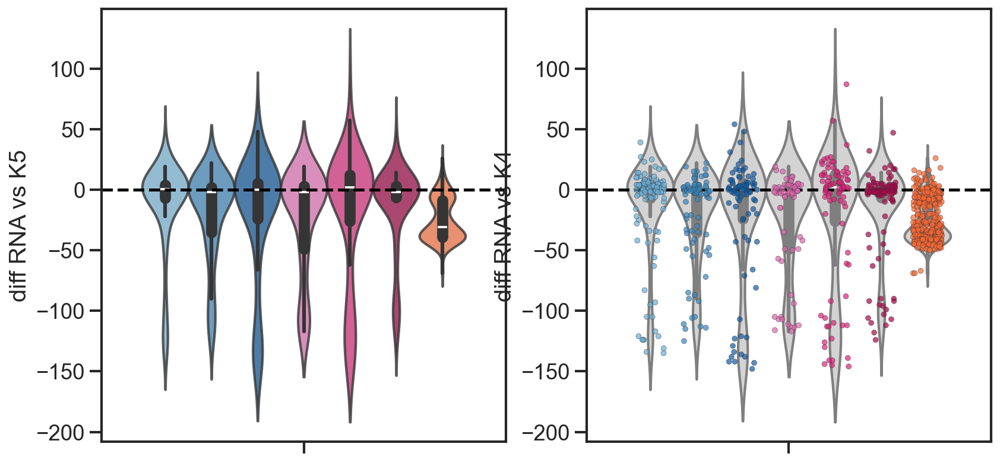

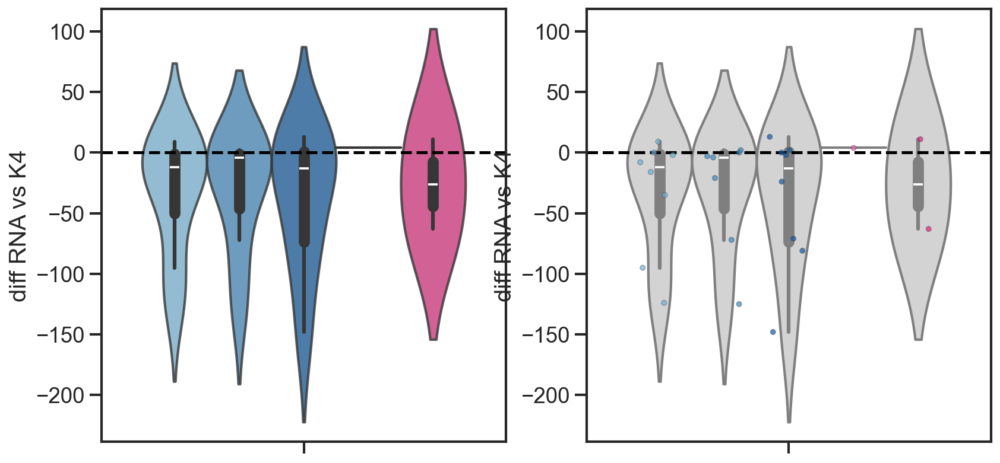

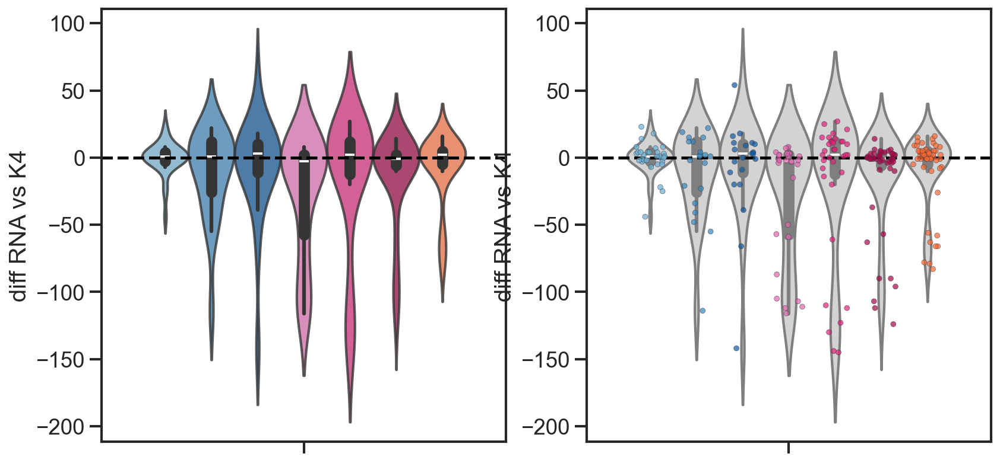

In [100]:
d1 = calculateDiff(ecto_changes_f,'ect1',keep = 'first', mark = 'K4')
d2 = calculateDiff(ecto_changes_f,'ect2',keep = 'first', mark = 'K4')
d3 = calculateDiff(ecto_changes_f,'ect3',keep = 'first', mark = 'K4')

d4 = calculateDiff(meso_changes_f,'mes1',keep = 'first', mark = 'K4')
d5 = calculateDiff(meso_changes_f,'mes2',keep = 'first', mark = 'K4')
d6 = calculateDiff(meso_changes_f,'mes3',keep = 'first', mark = 'K4')

d7 = calculateDiff(endo_changes_f,'endo1',keep = 'first')

pal = ['#6AAED6', '#3787C0', '#105BA4', '#DF64AF', '#DF2179', '#A90649', '#FC6832',]
fig,ax = plt.subplots(1,2,figsize = (12,6))
sns.violinplot(data = pd.concat([d1,d2,d3,d4,d5,d6,d7]),ax=ax[0],
        y = 'diff', #fliersize = False,
               palette = pal,alpha = 0.8,
            hue = 'lin')
ax[0].legend([],frameon=False)
ax[0].axhline(0, linestyle = 'dashed', c = 'black')
ax[0].set_ylabel('diff RNA vs K5')
#plt.savefig('figs/20250409_barplot_deltaRNAvsK27_stdev.png',bbox_inches = 'tight')
sns.violinplot(data = pd.concat([d1,d2,d3,d4,d5,d6,d7]),ax=ax[1],
        y = 'diff', #fliersize = False,
               palette = ['lightgrey'],
            hue = 'lin')
sns.stripplot(data = pd.concat([d1,d2,d3,d4,d5,d6,d7]),ax=ax[1],
        y = 'diff',palette = pal,dodge = True, size = 4, alpha = 0.7, jitter = 0.25,linewidth = 0.3,
            hue = 'lin')
ax[1].legend([],frameon=False)
ax[1].axhline(0, linestyle = 'dashed', c = 'black')
ax[1].set_ylabel('diff RNA vs K4')
#plt.savefig('figs/20250306_barplot_deltaRNAvsK27_fix.png',bbox_inches = 'tight')
plt.show()

d1 = calculateDiff(ecto_changes_f,'ect1',keep = 'first', mark = 'K4')
d1 = d1[d1.index.isin(list(all_source_target_genes['ect_source']))]
d2 = calculateDiff(ecto_changes_f,'ect2',keep = 'first', mark = 'K4')
d2 = d2[d2.index.isin(list(all_source_target_genes['ect_source']))]
d3 = calculateDiff(ecto_changes_f,'ect3',keep = 'first', mark = 'K4')
d3 = d3[d3.index.isin(list(all_source_target_genes['ect_source']))]

d4 = calculateDiff(meso_changes_f,'mes1',keep = 'first', mark = 'K4')
d4 = d4[d4.index.isin(list(all_source_target_genes['mes_source']))]
d5 = calculateDiff(meso_changes_f,'mes2',keep = 'first', mark = 'K4')
d5 = d5[d5.index.isin(list(all_source_target_genes['mes_source']))]
d6 = calculateDiff(meso_changes_f,'mes3',keep = 'first', mark = 'K4')
d6 = d6[d6.index.isin(list(all_source_target_genes['mes_source']))]

d7 = calculateDiff(endo_changes_f,'endo1',keep = 'first', mark = 'K4')
d7 = d7[d7.index.isin(list(all_source_target_genes['end_source']))]

pal = ['#6AAED6', '#3787C0', '#105BA4', '#DF64AF', '#DF2179', '#A90649', '#FC6832',]
fig,ax = plt.subplots(1,2,figsize = (12,6))
sns.violinplot(data = pd.concat([d1,d2,d3,d4,d5,d6,d7]),ax=ax[0],
        y = 'diff', #fliersize = False,
               palette = pal,alpha = 0.8,
            hue = 'lin')
ax[0].legend([],frameon=False)
ax[0].axhline(0, linestyle = 'dashed', c = 'black')
ax[0].set_ylabel('diff RNA vs K4')
#plt.savefig('figs/20250409_barplot_deltaRNAvsK27_stdev.png',bbox_inches = 'tight')
sns.violinplot(data = pd.concat([d1,d2,d3,d4,d5,d6,d7]),ax=ax[1],
        y = 'diff', #fliersize = False,
               palette = ['lightgrey'],
            hue = 'lin')
sns.stripplot(data = pd.concat([d1,d2,d3,d4,d5,d6,d7]),ax=ax[1],
        y = 'diff',palette = pal,dodge = True, size = 4, alpha = 0.7, jitter = 0.25,linewidth = 0.3,
            hue = 'lin')
ax[1].legend([],frameon=False)
ax[1].axhline(0, linestyle = 'dashed', c = 'black')
ax[1].set_ylabel('diff RNA vs K4')
#plt.savefig('figs/20250306_barplot_deltaRNAvsK27_fix.png',bbox_inches = 'tight')
plt.show()

d1 = calculateDiff(ecto_changes_f,'ect1',keep = 'first', mark = 'K4')
d1 = d1[d1.index.isin(list(all_source_target_genes['ect_target']))]
d2 = calculateDiff(ecto_changes_f,'ect2',keep = 'first', mark = 'K4')
d2 = d2[d2.index.isin(list(all_source_target_genes['ect_target']))]
d3 = calculateDiff(ecto_changes_f,'ect3',keep = 'first', mark = 'K4')
d3 = d3[d3.index.isin(list(all_source_target_genes['ect_target']))]

d4 = calculateDiff(meso_changes_f,'mes1',keep = 'first', mark = 'K4')
d4 = d4[d4.index.isin(list(all_source_target_genes['mes_target']))]
d5 = calculateDiff(meso_changes_f,'mes2',keep = 'first', mark = 'K4')
d5 = d5[d5.index.isin(list(all_source_target_genes['mes_target']))]
d6 = calculateDiff(meso_changes_f,'mes3',keep = 'first', mark = 'K4')
d6 = d6[d6.index.isin(list(all_source_target_genes['mes_target']))]

d7 = calculateDiff(endo_changes_f,'endo1',keep = 'first', mark = 'K4')
d7 = d7[d7.index.isin(list(all_source_target_genes['end_target']))]

pal = ['#6AAED6', '#3787C0', '#105BA4', '#DF64AF', '#DF2179', '#A90649', '#FC6832',]
fig,ax = plt.subplots(1,2,figsize = (12,6))
sns.violinplot(data = pd.concat([d1,d2,d3,d4,d5,d6,d7]),ax=ax[0],
        y = 'diff', #fliersize = False,
               palette = pal,alpha = 0.8,
            hue = 'lin')
ax[0].legend([],frameon=False)
ax[0].axhline(0, linestyle = 'dashed', c = 'black')
ax[0].set_ylabel('diff RNA vs K4')
#plt.savefig('figs/20250409_barplot_deltaRNAvsK27_stdev.png',bbox_inches = 'tight')
sns.violinplot(data = pd.concat([d1,d2,d3,d4,d5,d6,d7]),ax=ax[1],
        y = 'diff', #fliersize = False,
               palette = ['lightgrey'],
            hue = 'lin')
sns.stripplot(data = pd.concat([d1,d2,d3,d4,d5,d6,d7]),ax=ax[1],
        y = 'diff',palette = pal,dodge = True, size = 4, alpha = 0.7, jitter = 0.25,linewidth = 0.3,
            hue = 'lin')
ax[1].legend([],frameon=False)
ax[1].axhline(0, linestyle = 'dashed', c = 'black')
ax[1].set_ylabel('diff RNA vs K4')
#plt.savefig('figs/20250306_barplot_deltaRNAvsK27_fix.png',bbox_inches = 'tight')
plt.show()

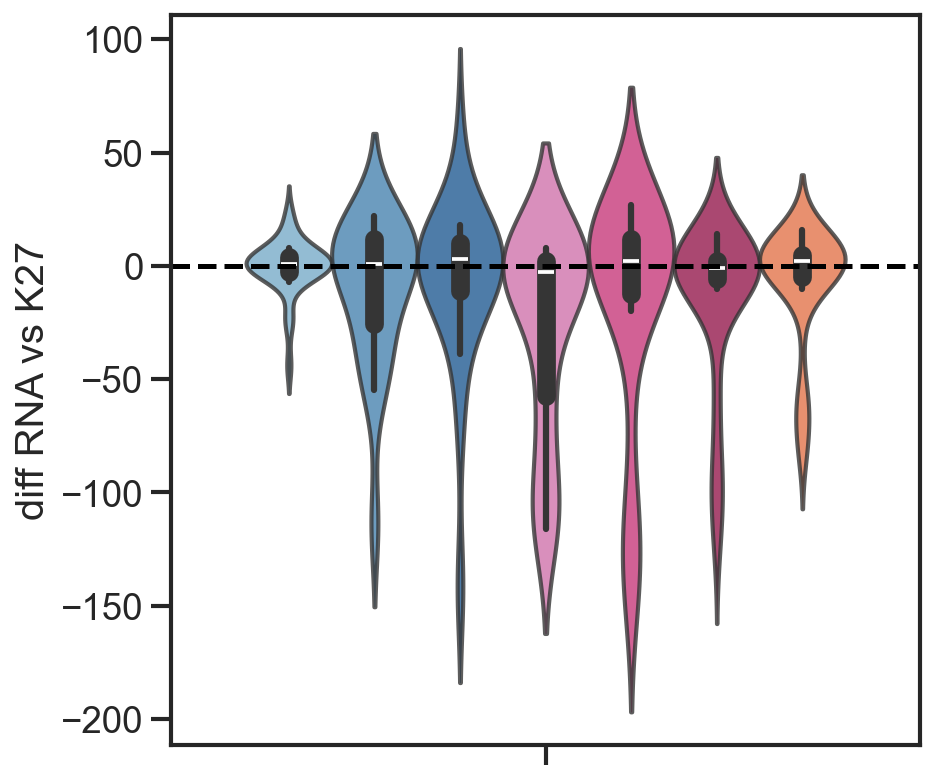

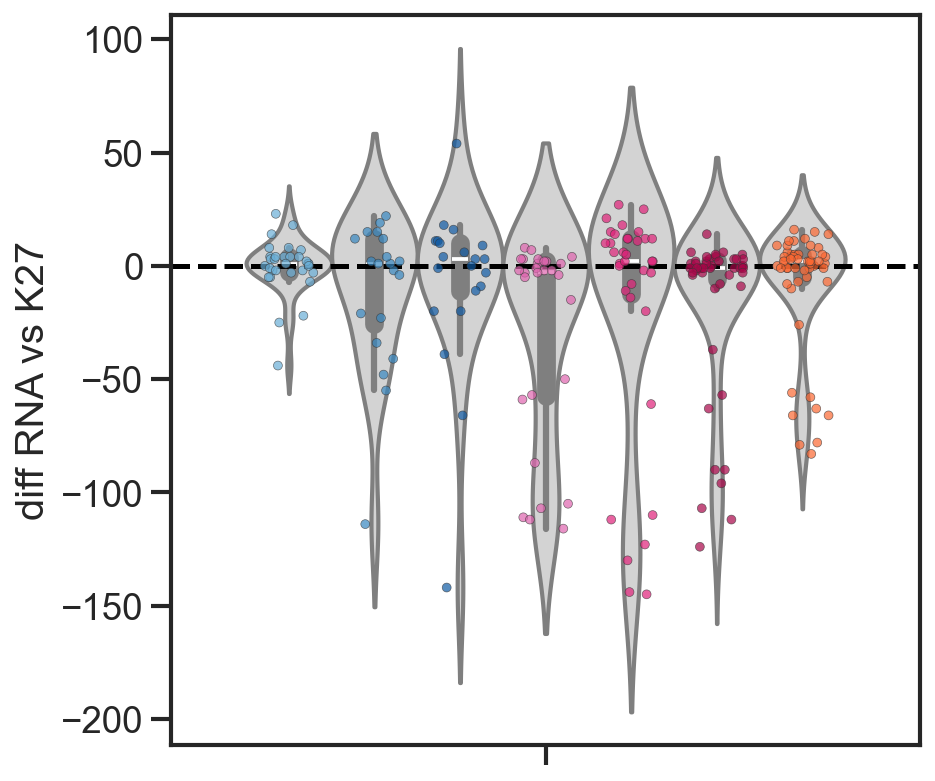

In [101]:
pal = ['#6AAED6', '#3787C0', '#105BA4', '#DF64AF', '#DF2179', '#A90649', '#FC6832',]
fig,ax = plt.subplots(figsize = (6,6))
sns.violinplot(data = pd.concat([d1,d2,d3,d4,d5,d6,d7]),ax=ax,
        y = 'diff', #fliersize = False,
               palette = pal,alpha = 0.8,
            hue = 'lin')
plt.legend([],frameon=False)
plt.axhline(0, linestyle = 'dashed', c = 'black')
plt.ylabel('diff RNA vs K27')
plt.show()

fig,ax = plt.subplots(figsize = (6,6))
sns.violinplot(data = pd.concat([d1,d2,d3,d4,d5,d6,d7]),ax=ax,
        y = 'diff', #fliersize = False,
               palette = ['lightgrey'],
            hue = 'lin')
sns.stripplot(data = pd.concat([d1,d2,d3,d4,d5,d6,d7]),ax=ax,
        y = 'diff',palette = pal,dodge = True, size = 4, alpha = 0.7, jitter = 0.25,linewidth = 0.3,
            hue = 'lin')
plt.legend([],frameon=False)
plt.axhline(0, linestyle = 'dashed', c = 'black')
plt.ylabel('diff RNA vs K27')
#plt.savefig('figs/20250306_barplot_deltaRNAvsK27_fix.png',bbox_inches = 'tight')
plt.show()

# other

In [ ]:
for lins in ect_changes['lin'].unique():
    print(lins)
    sns.stripplot(data = ect_changes_unique[ect_changes_unique['lin'] == lins],
                    y = 'step', palette =[Orange,Green,Purple], hue_order = ['RNA','K4','K27']
                  ,s = 4, alpha = 0.5,# [lightOrange,Orange,lightPurple,Purple,lightGreen,Green], 
                  jitter = 0.3,
                    x = 'change',
                  hue = 'layer',dodge = True)
    sns.boxplot(data = ect_changes_unique[ect_changes_unique['lin'] == lins],
                   y = 'step',palette = ['lightgrey','lightgrey','lightgrey'],
                x = 'change',hue_order = ['RNA','K4','K27'],
                    hue = 'layer', dodge = True)
    plt.legend([],frameon = False)
    plt.show()

In [869]:
def plotChanges(df,lin,keep='first',save = None):
    df['dup'] = df['lin_layer'] + '_' + df['gene']
    df_unique = df[~df['dup'].duplicated(keep = keep)]
    fig,ax = plt.subplots(3,1, figsize = (6,4),gridspec_kw = {'wspace':0, 'hspace':0.05})
    sns.histplot(df_unique[(df_unique['lin'] == lin) & (df_unique['layer'] == 'RNA')]['step'],
                ax=ax[0], color= Orange, bins=40)
    sns.histplot(df_unique[(df_unique['lin'] == lin) & (df_unique['layer'] == 'K4')]['step'],
                ax=ax[1], color= Green,bins = 40)
    sns.histplot(df_unique[(df_unique['lin'] == lin) & (df_unique['layer'] == 'K27')]['step'],
                ax=ax[2], color= Purple, bins = 40)
    for x in range(3):
        ax[x].set_xlim([0,dict1[lin+'_RNA']+5])
        ax[x].set_xticks([])
        ax[x].set_xlabel('')
        ax[x].set_yticks([])
        ax[x].set_ylabel('')
        ax[x].set_ylim([0,55])

    if save != None:
        plt.savefig(save,bbox_inches='tight')
    plt.show()



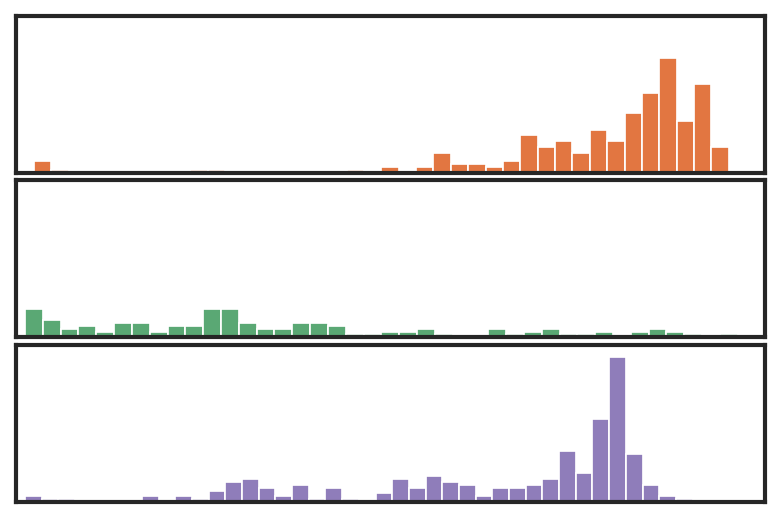

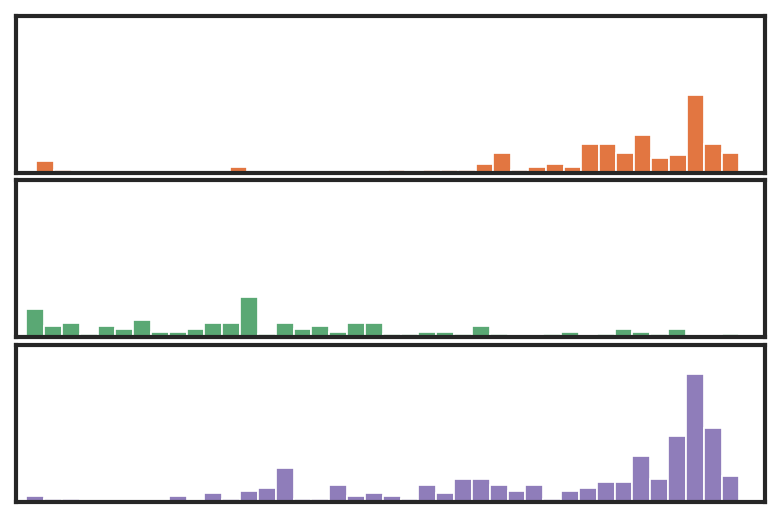

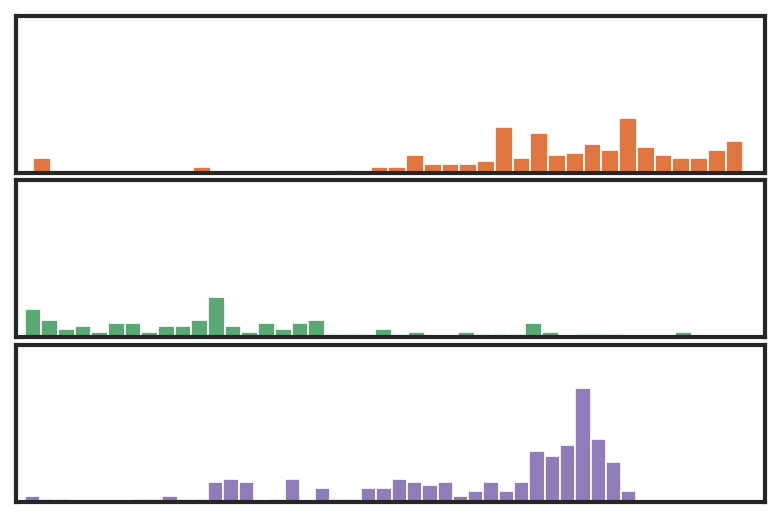

In [795]:
plotChanges(ect_changes,'ect1',save = 'figs/20250306_histplot_changes_ect1.png')
plotChanges(ect_changes,'ect2',save = 'figs/20250306_histplot_changes_ect2.png')
plotChanges(ect_changes,'ect3',save = 'figs/20250306_histplot_changes_ect3.png')

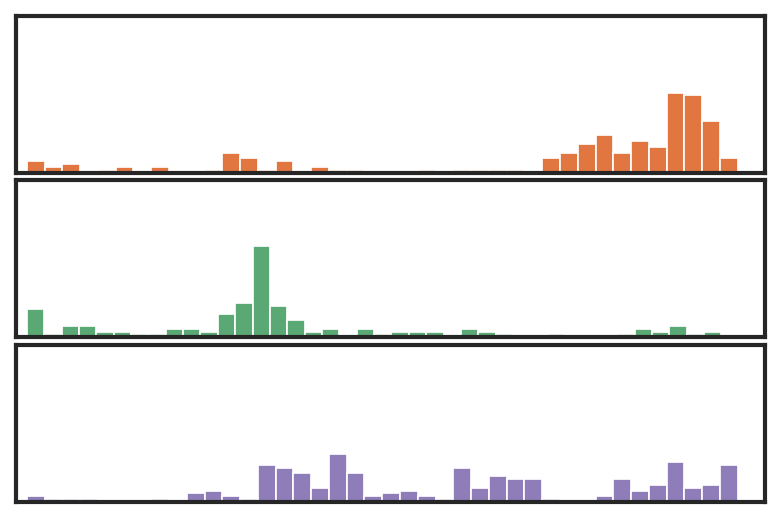

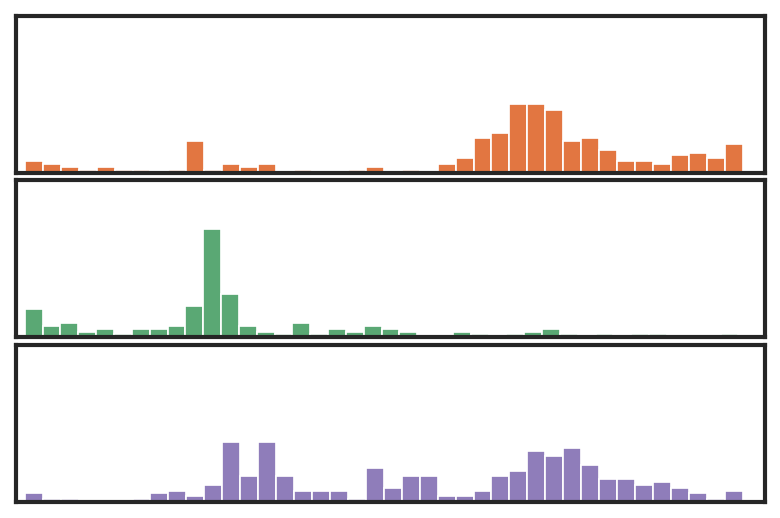

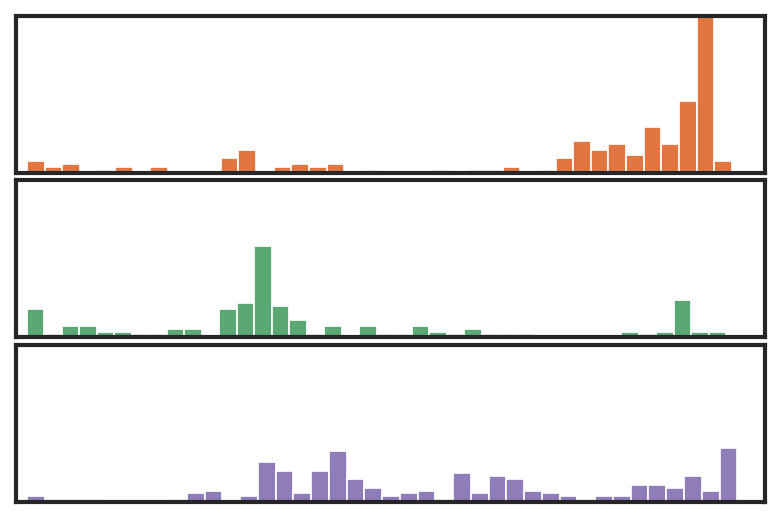

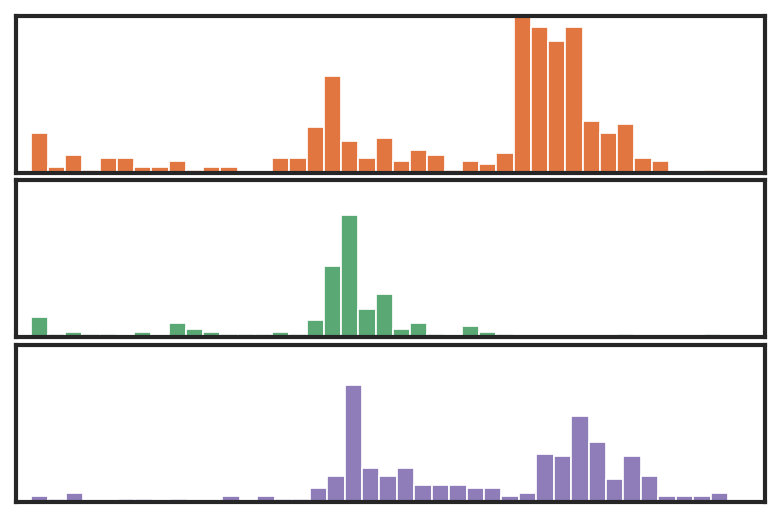

In [796]:
plotChanges(mes_changes,'mes1',save = 'figs/20250306_histplot_changes_mes1.png')
plotChanges(mes_changes,'mes2',save = 'figs/20250306_histplot_changes_mes2.png')
plotChanges(mes_changes,'mes3',save = 'figs/20250306_histplot_changes_mes3.png')
plotChanges(end_changes,'endo1',save = 'figs/20250306_histplot_changes_end1.png')

In [369]:
to_plot1.head(2)

,step,layer,counts,lin,sm_short,counts_log2,sm_short_log2,sm_short_state_fix,sm_short_state_dyn,p_99,p_98,p_95,p98_log2,p98_log10,step_id,RT,lin_layer
gene,,,,,,,,,,,,,,,,,
Tnfrsf12a,1,RNA,0.01,ect1,0.014000,-5.643856,-5.380822,0.0,1.0,0.002357,0.003447,0.006167,0.004965,0.001495,1:ect1,mESCs,ect1_RNA
Tnfrsf12a,2,RNA,0.01,ect1,0.011667,-5.643856,-5.528379,0.0,1.0,0.001964,0.002873,0.005140,0.004139,0.001246,2:ect1,mESCs,ect1_RNA


In [372]:
tests = to_plot1[(to_plot1['lin'] == 'endo1') & (to_plot1['layer'] == 'RNA')][['step','sm_short_state_fix','sm_short_state_dyn']]#.loc['Car2']

In [810]:
fig, ax = plt.subplots(1,2, figsize = (8,4))
sns.scatterplot(data = tests.loc['Car2'],ax=ax[0],
                x = 'step',
                y = 'sm_short_state_fix')
sns.scatterplot(data = tests.loc['Car2'],ax=ax[1],
                x = 'step',
                y = 'sm_short_state_dyn')
plt.show()

NameError: name 'tests' is not defined

In [811]:
list(d3.index)

['B630019K06Rik',
 'Crp',
 'Peg12',
 'Tnfrsf14',
 'Fndc5',
 'Slc22a15',
 'Abcd2',
 'Tceal3',
 'Cnmd',
 'Vxn',
 'Slitrk2',
 'Pou3f2',
 'Wnt4',
 'Mfng',
 'Ndnf',
 'Scn3a',
 'Crabp2',
 'Stmn4',
 'Grm2',
 'Trim9',
 'Lfng',
 'Insc',
 'Gas1',
 'Tagln3',
 'Pkd2l1',
 'Dbx2',
 'Ypel4',
 'Nkain4',
 'Hoxa7',
 'Pou3f4',
 'Hoxb3',
 'Pmp22',
 'Zfp663',
 'Vit',
 'Skida1',
 'Myt1',
 'Atcay',
 'Kif19a',
 'Cfap97d2',
 'Serping1',
 'Hoxc4',
 'Ndp',
 'Hoxd4',
 'Prss23',
 'Irx5',
 'C1qtnf3',
 'Pnoc',
 'Trappc3l',
 'Agtr1a',
 'Nsg2',
 'Dpysl4',
 'Celsr2',
 'Cldn14',
 'Neurod4',
 'Hoxd3',
 'BC024139',
 'Celf3',
 'Tmprss7',
 'Lrrn1',
 'Spock2',
 'Add2',
 'Chrna4',
 'Arhgap33',
 'Gm28230',
 'Plk3',
 'Nefm',
 'Hoxb6',
 'Apc2',
 'Gdf10',
 'Podxl2',
 'Serinc2',
 'Rprm',
 'Fabp7',
 'Tmem169',
 'Ube2l6',
 'Scg3',
 'Chrnb4',
 'Hoxc6']

In [812]:
d3.head(50)

,rna,k27,diff,lin
gene,,,,
B630019K06Rik,41,115,74,ect3
Crp,73,58,-15,ect3
Peg12,15,131,116,ect3
Tnfrsf14,140,111,-29,ect3
Fndc5,49,140,91,ect3
Slc22a15,3,128,125,ect3
Abcd2,2,56,54,ect3
Tceal3,38,40,2,ect3
Cnmd,11,135,124,ect3


In [771]:
ect_changes[(ect_changes['gene'] == 'Syt2') & (ect_changes['lin'] == lin)]

,step,gene,layer,lin,counts,sm_short,counts_log2,sm_short_log2,sm_short_state_fix,sm_short_state_dyn,RT,lin_layer,change,val_change,steps1,total_change


In [772]:
d3

,rna,k27,diff,lin
gene,,,,
Syt2,157,134,-23,ect3
B630019K06Rik,164,122,-42,ect3
Dmd,143,89,-54,ect3
Cacng4,124,132,8,ect3
Adamts20,142,110,-32,ect3
...,...,...,...,...
Ube2l6,142,120,-22,ect3
Gm973,142,132,-10,ect3
Plxnc1,114,133,19,ect3


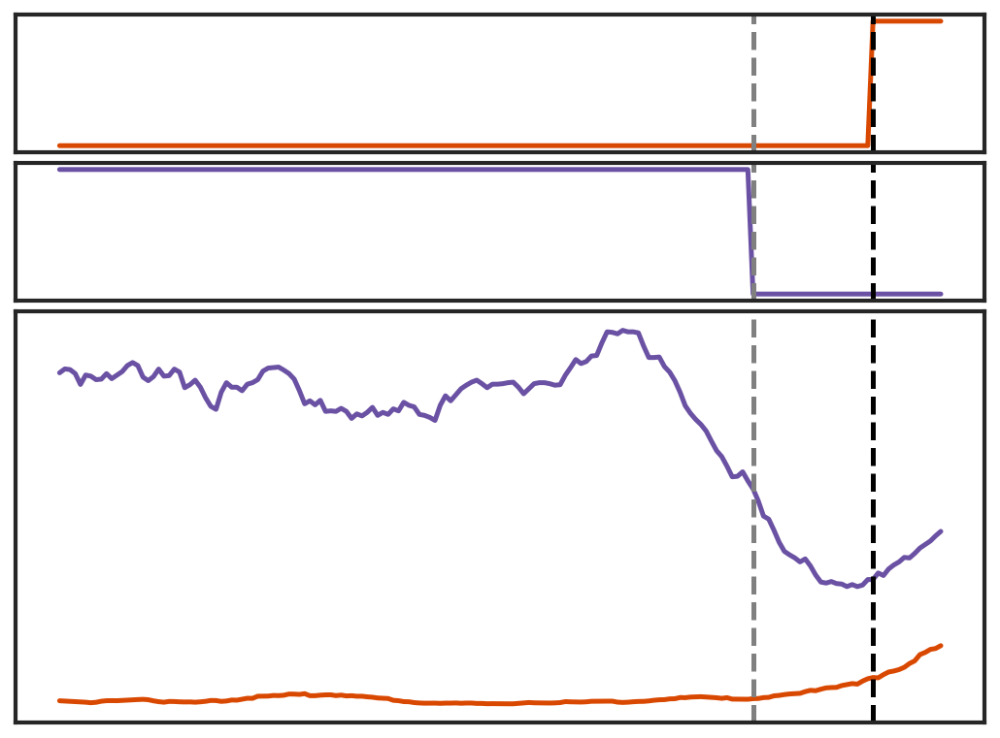

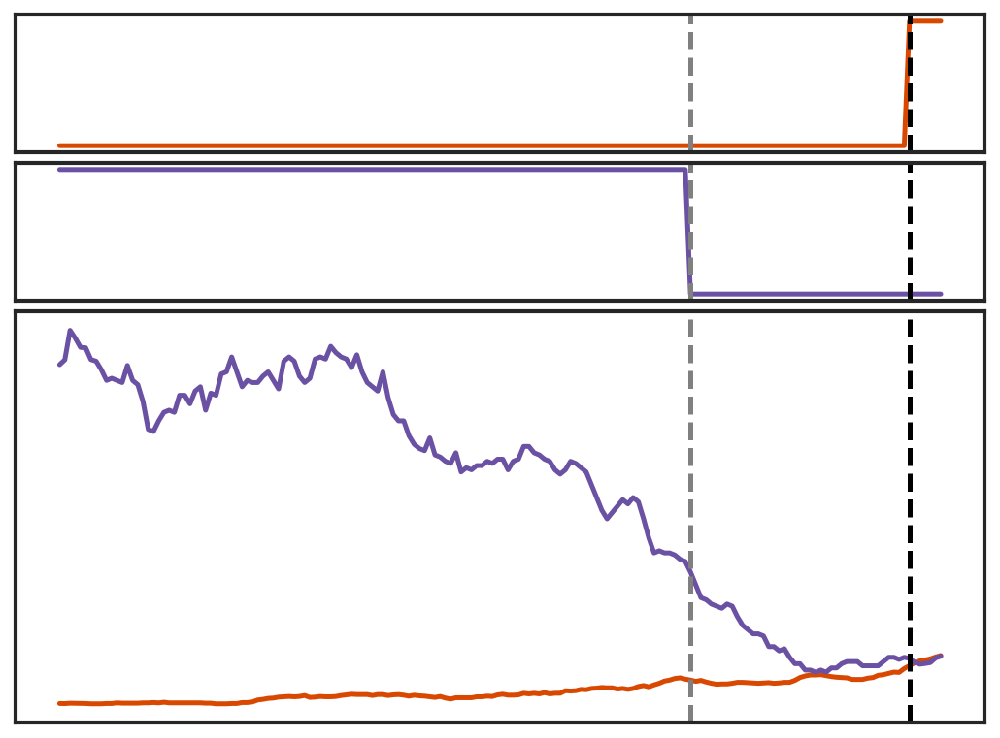

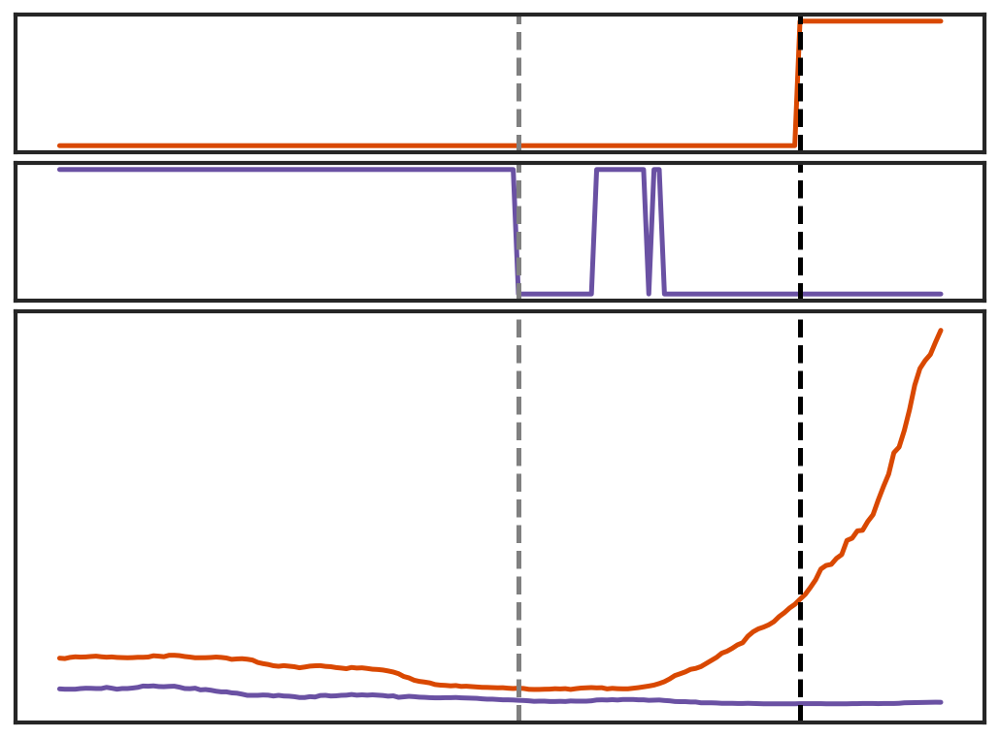

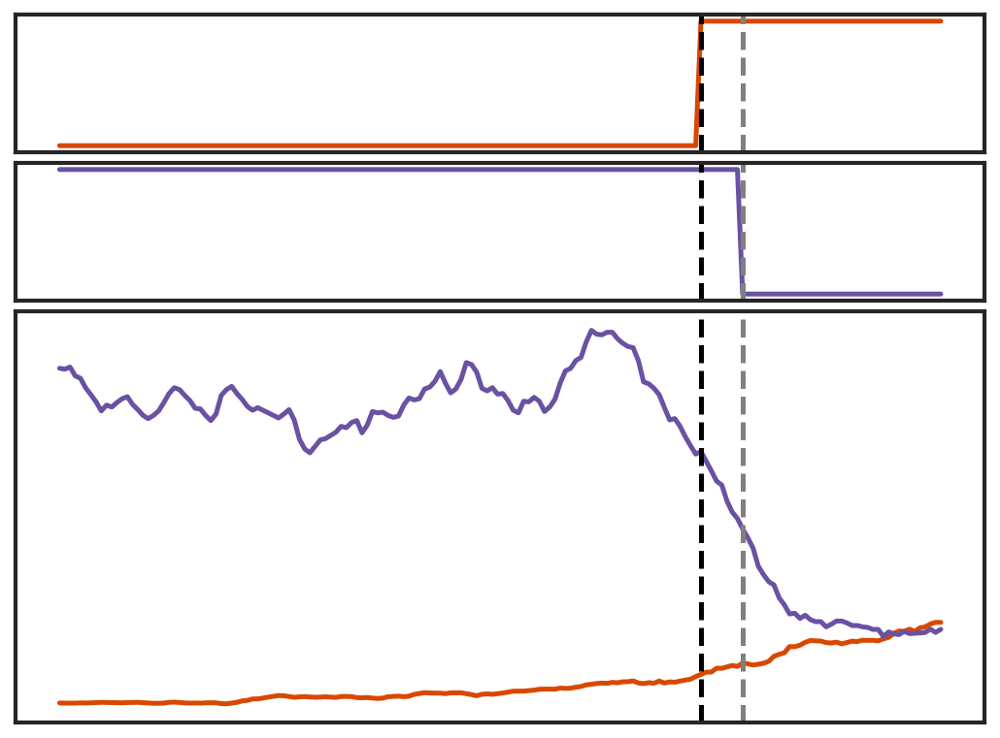

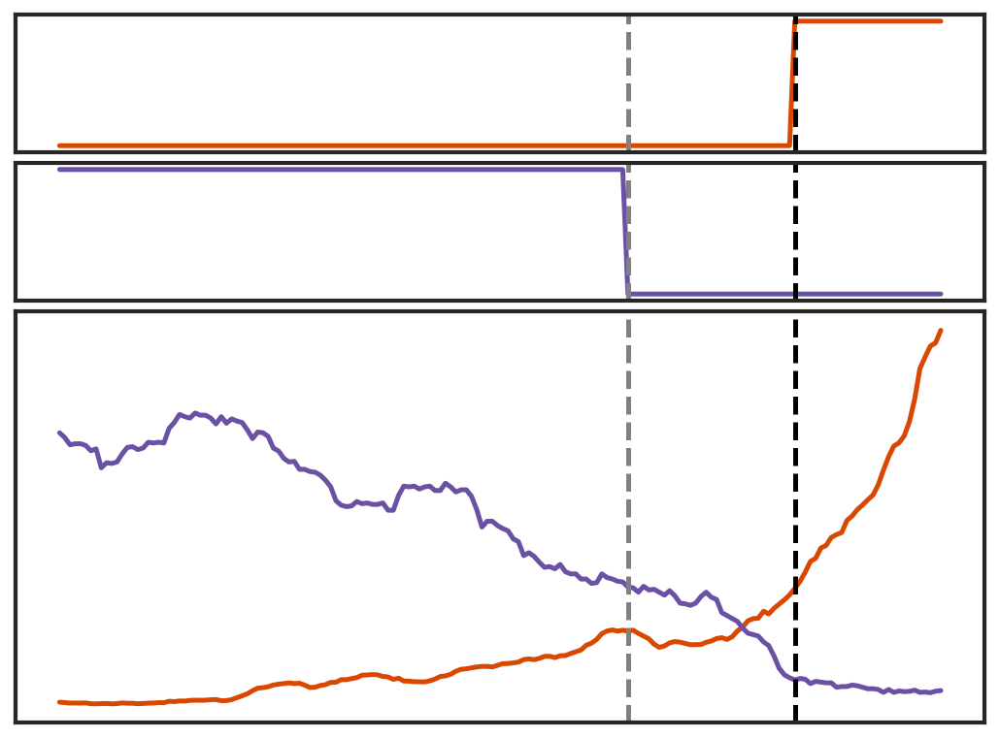

...

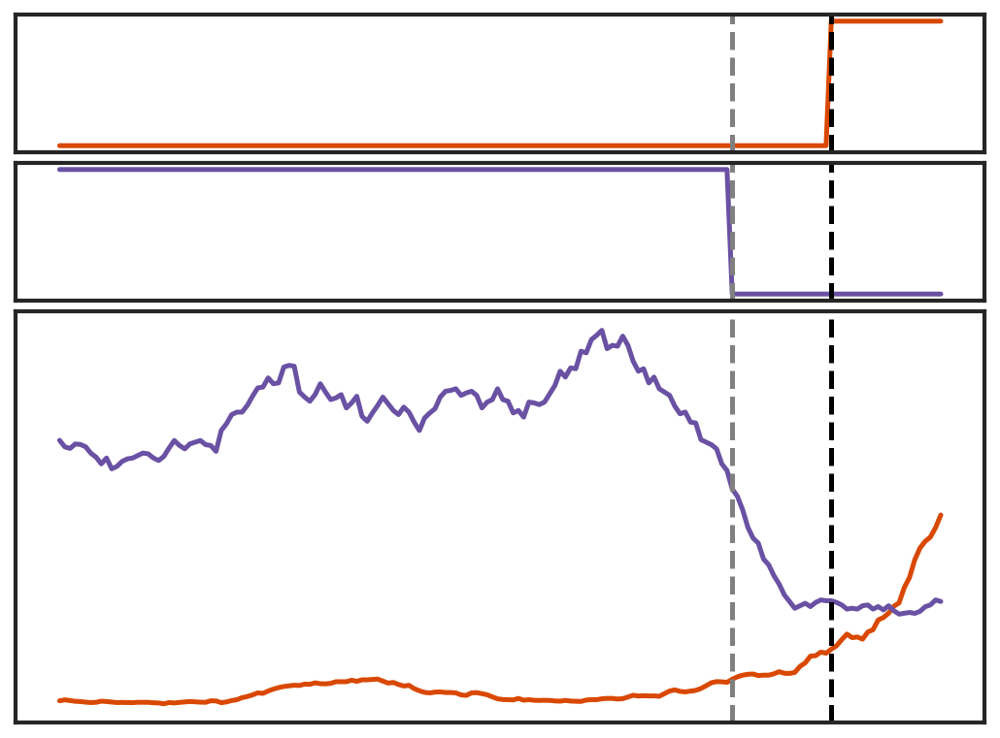

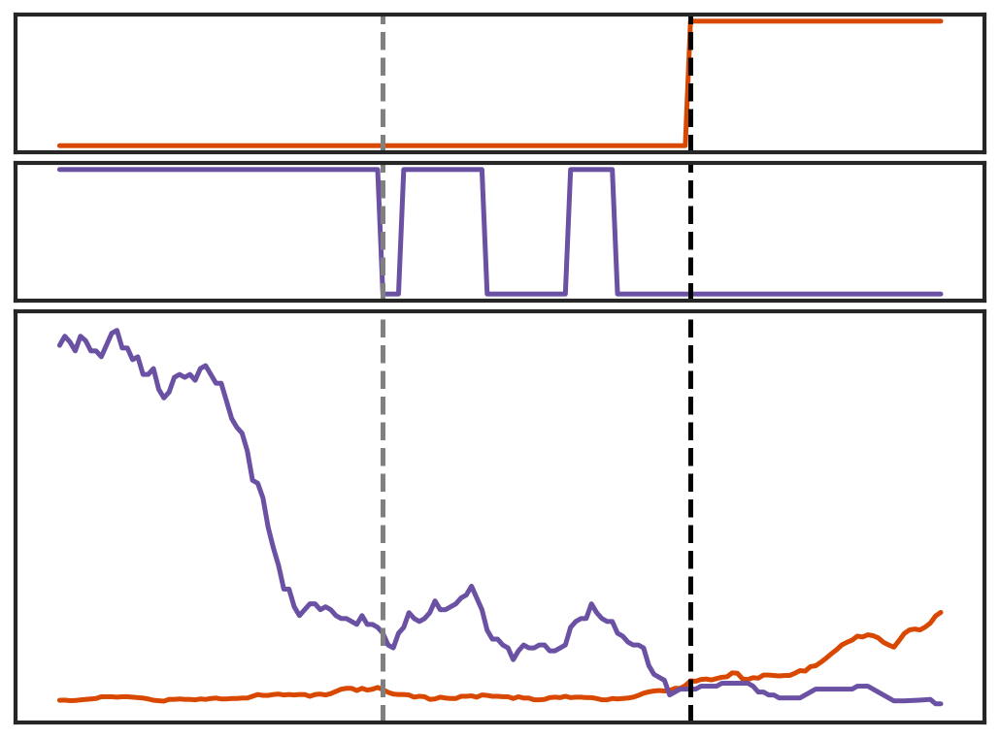

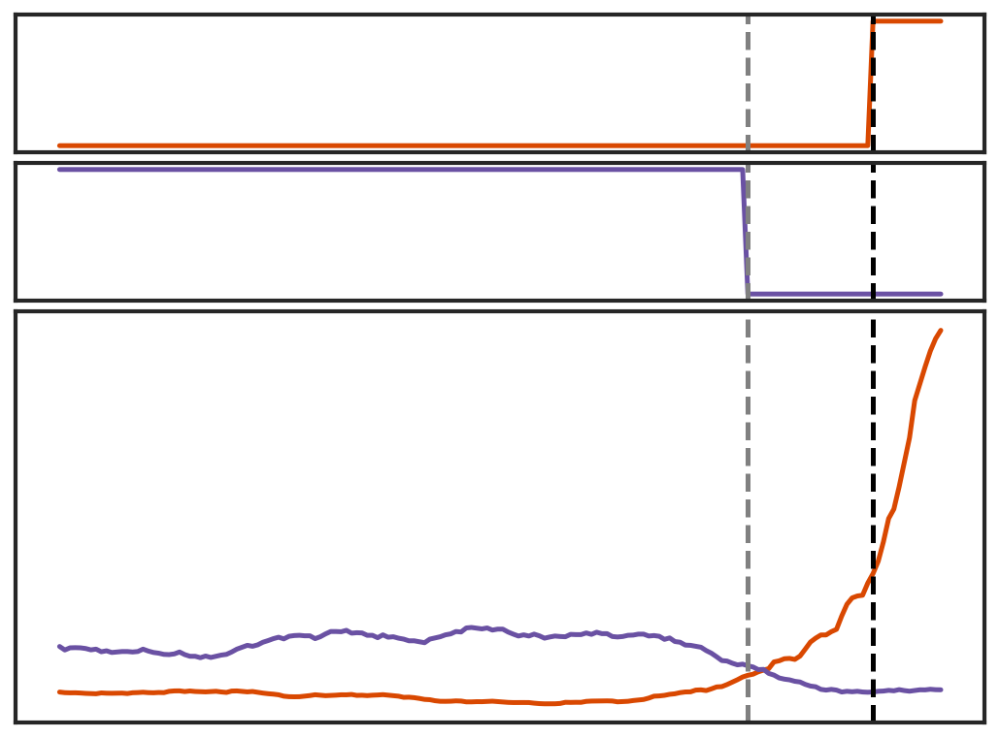

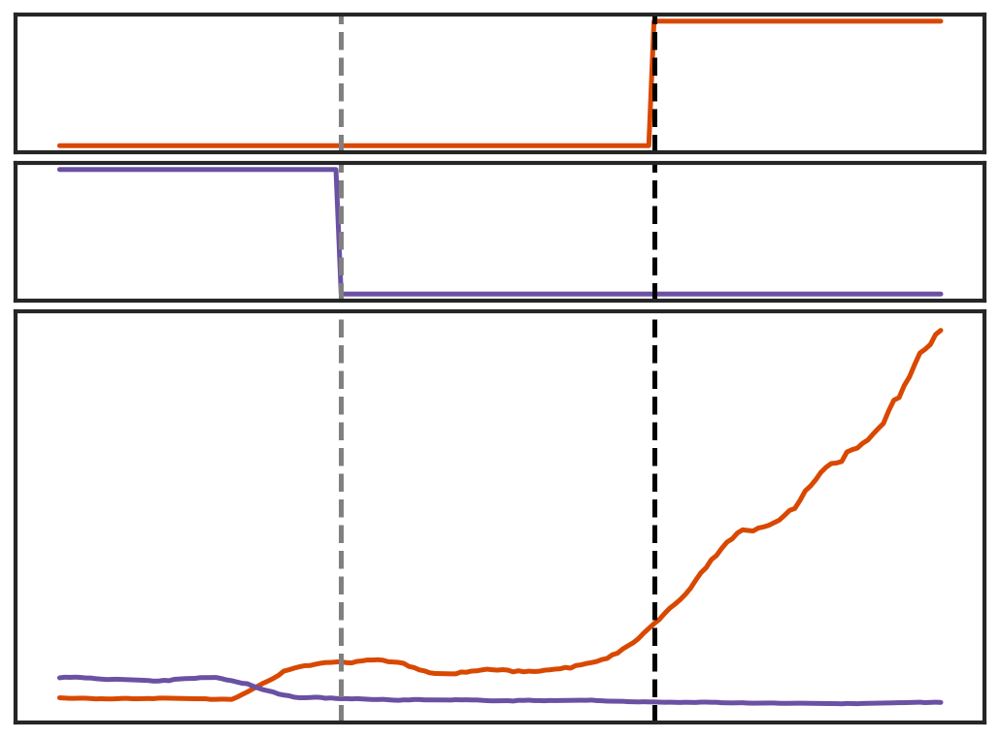

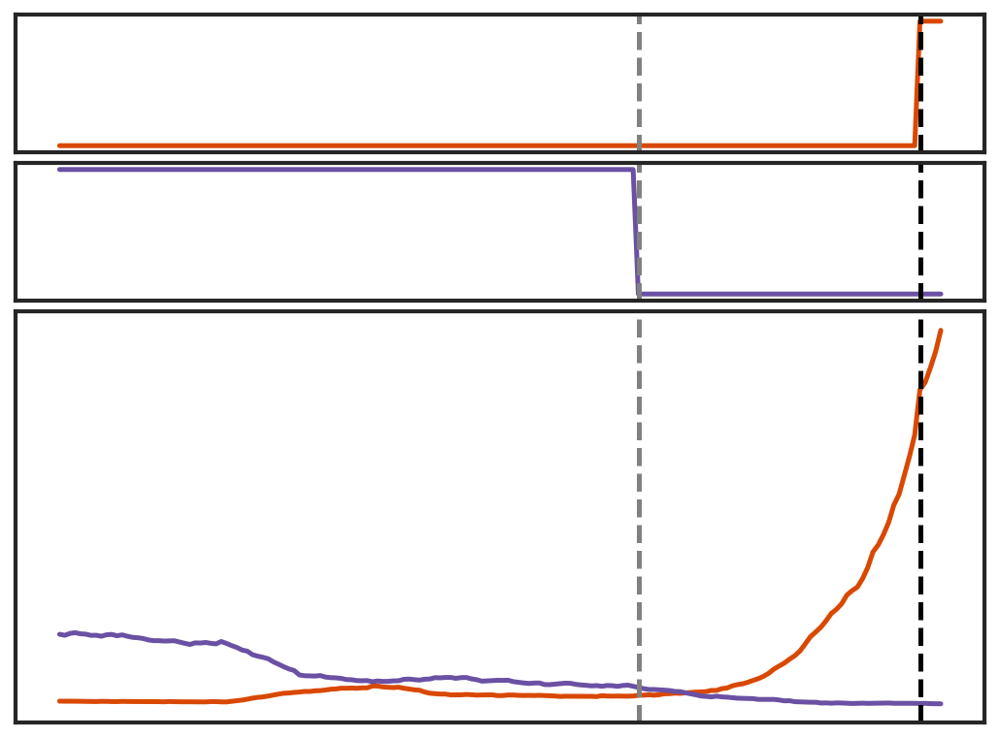

In [870]:
genes = list(d3.head(20).index)
lin = 'ect3'

for gene in genes:
    fig, ax = plt.subplots(3,1,figsize = (8,6), height_ratios=[0.2,0.2,0.6],gridspec_kw = {'wspace':0, 'hspace':0.05})
    
    sns.lineplot(data = ct_normalised[(ct_normalised['lin'] == lin) & (ct_normalised.index == gene)],
                 x = 'step',
                 y = 'sm_short_state_dyn',
                 hue = 'layer', hue_order = ['RNA'],ax=ax[0],
                 palette = [Orange])
    sns.lineplot(data = ct_normalised[(ct_normalised['lin'] == lin) & (ct_normalised.index == gene)],
                 x = 'step',
                 y = 'sm_short_state_dyn',ax=ax[1],
                 hue = 'layer', hue_order = ['K27'],
                 palette = [Purple])
    
    sns.lineplot(data = ct_normalised[(ct_normalised['lin'] == lin) & (ct_normalised.index == gene)],
                 x = 'step',ax=ax[2],
                 y = 'p_98',
                 hue = 'layer', hue_order = ['RNA','K27'],
                 palette = [Orange,Purple])
    
    for num in range(3):
        ax[num].axvline(d3.loc[gene]['rna'], c = 'black', linestyle = 'dashed',)
        ax[num].axvline(d3.loc[gene]['k27'], c = 'grey', linestyle = 'dashed',)
        ax[num].legend([],frameon=False)
        ax[num].set_xticks([])
        ax[num].set_xlabel('')
        ax[num].set_yticks([])
        ax[num].set_ylabel('')
    plt.show()

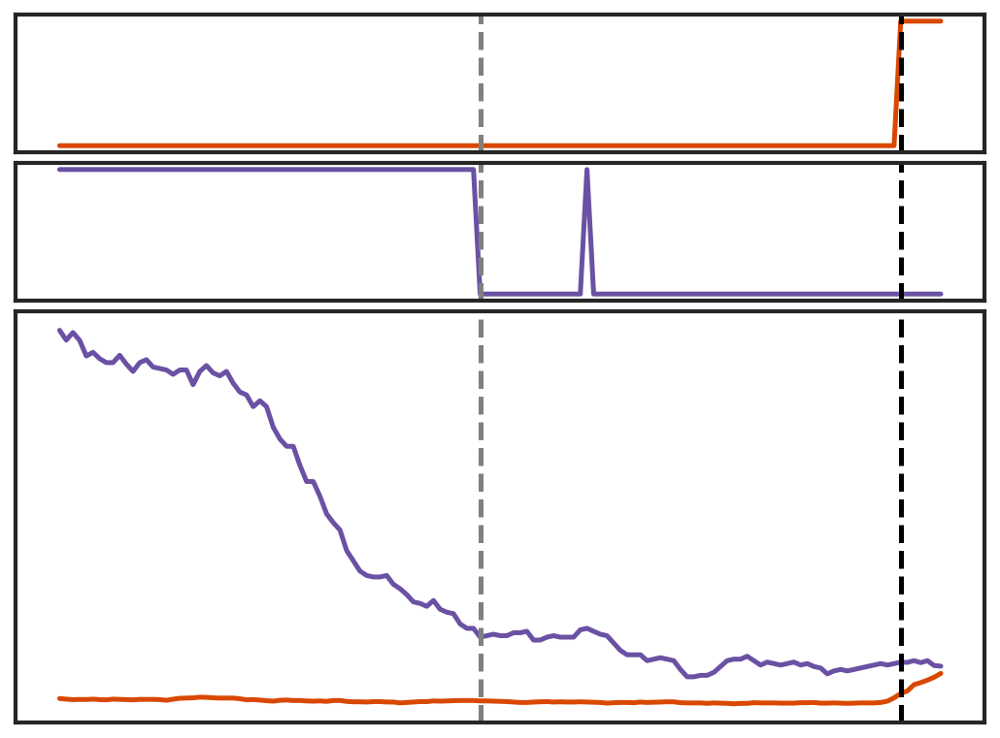

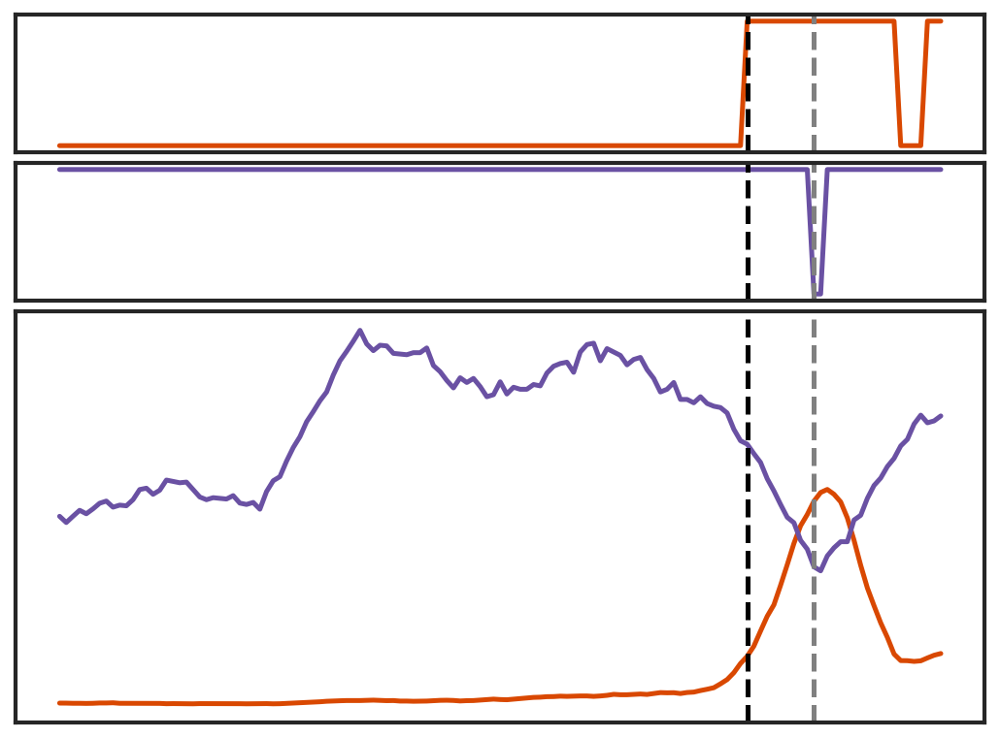

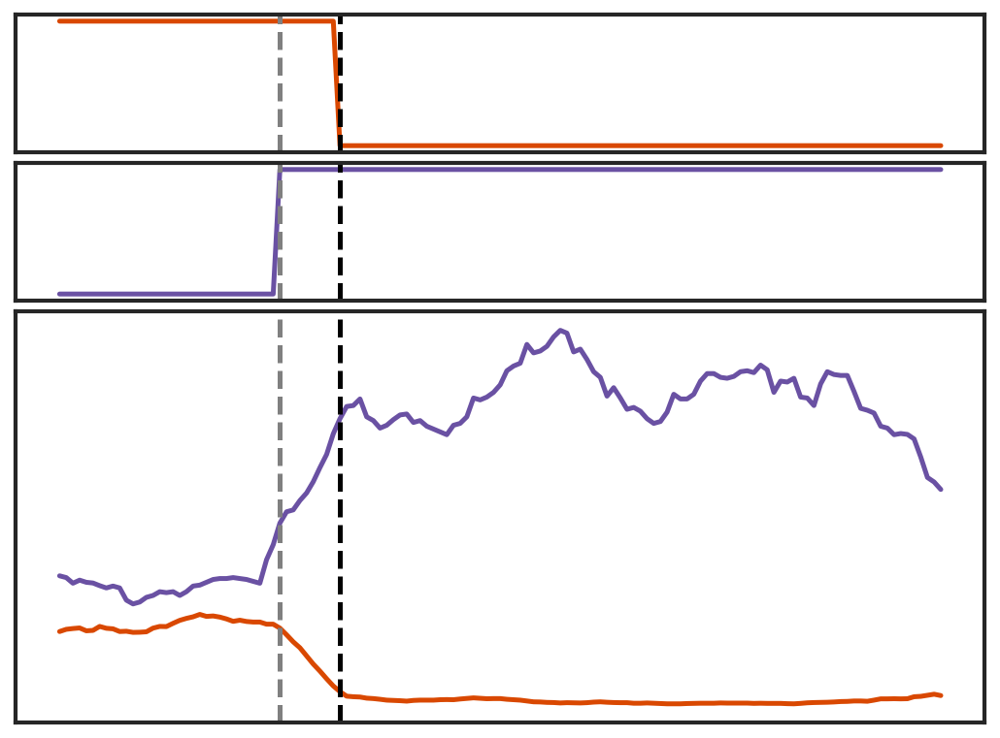

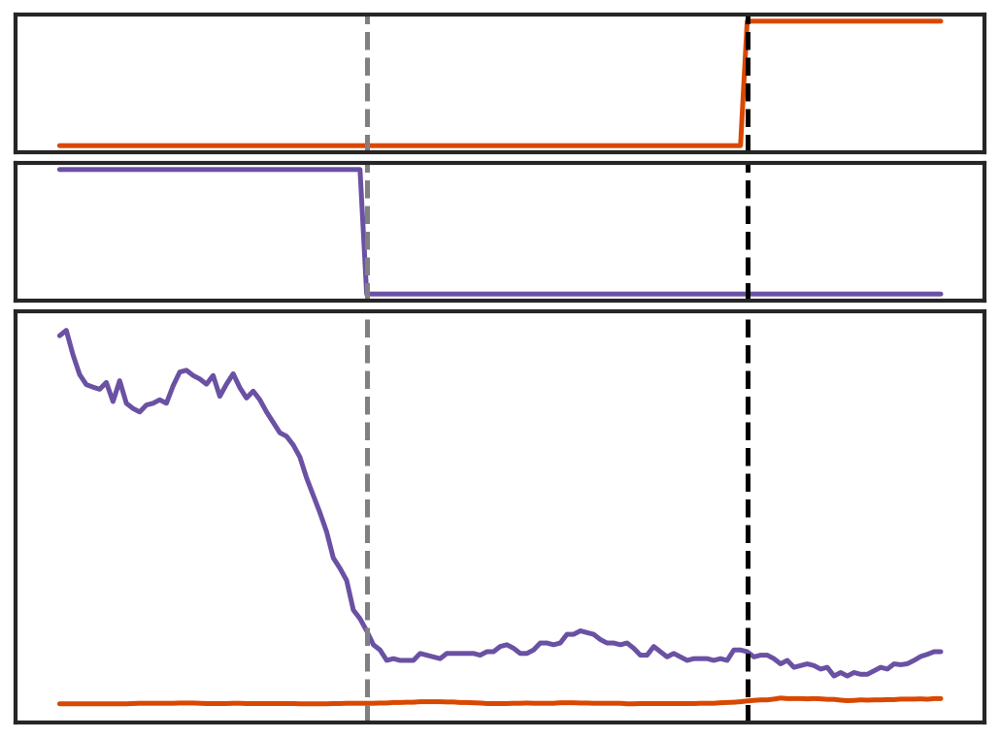

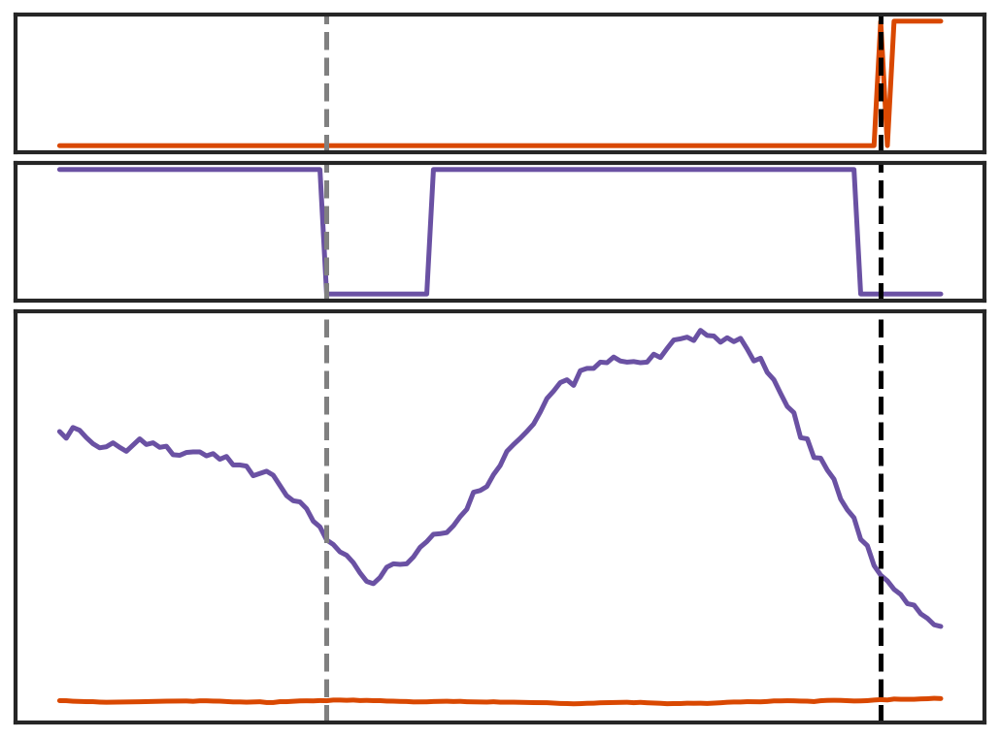

...

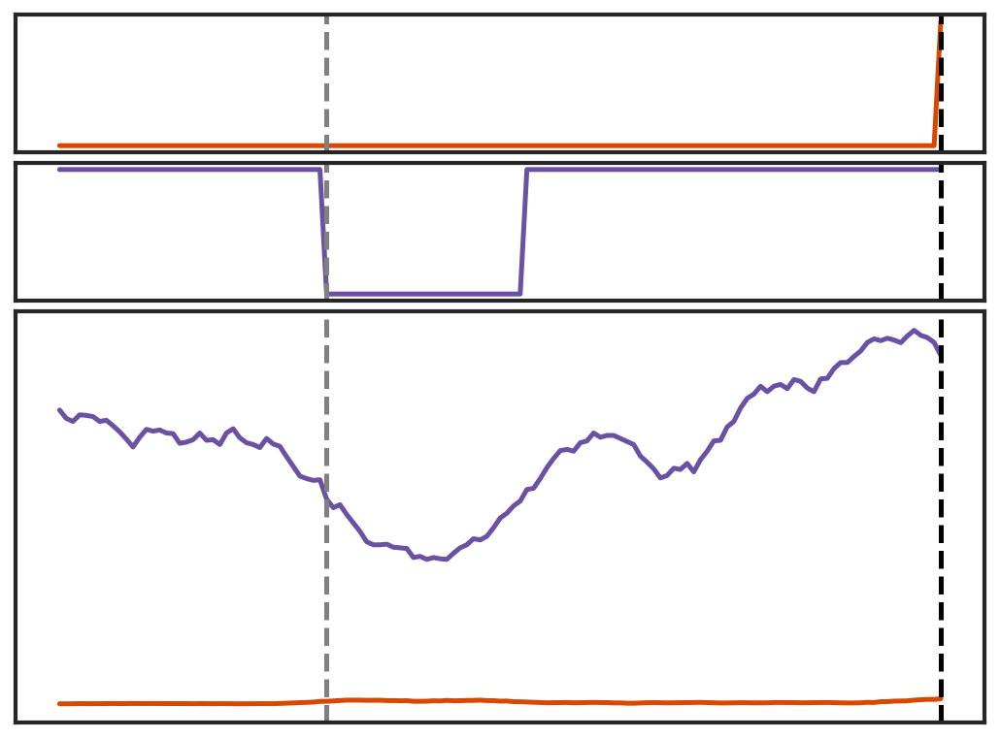

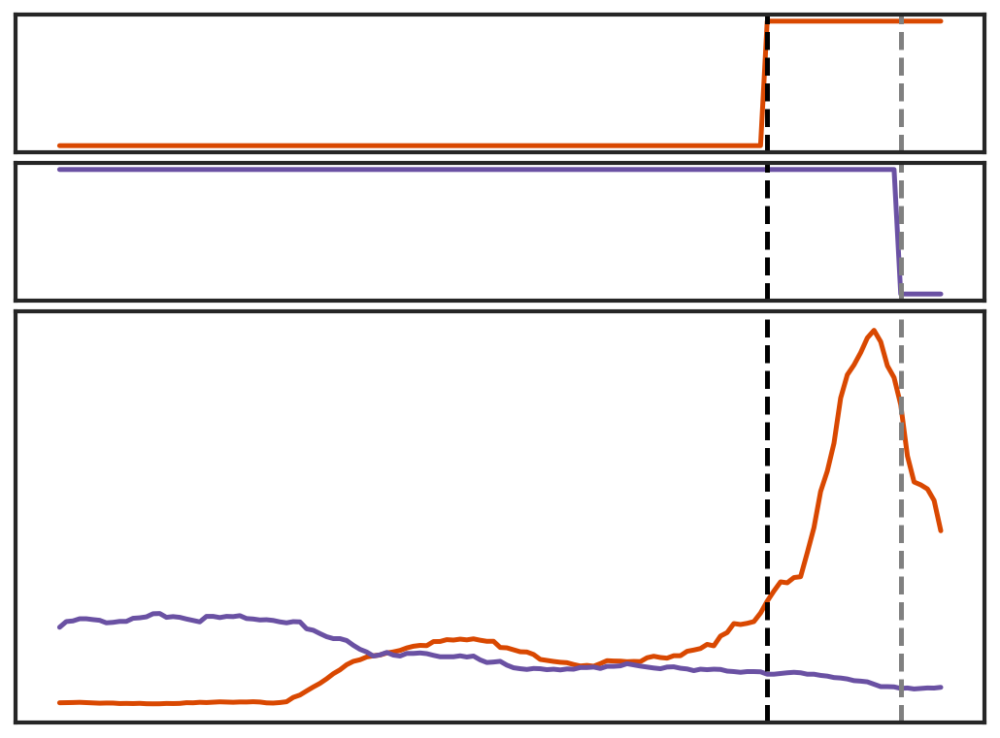

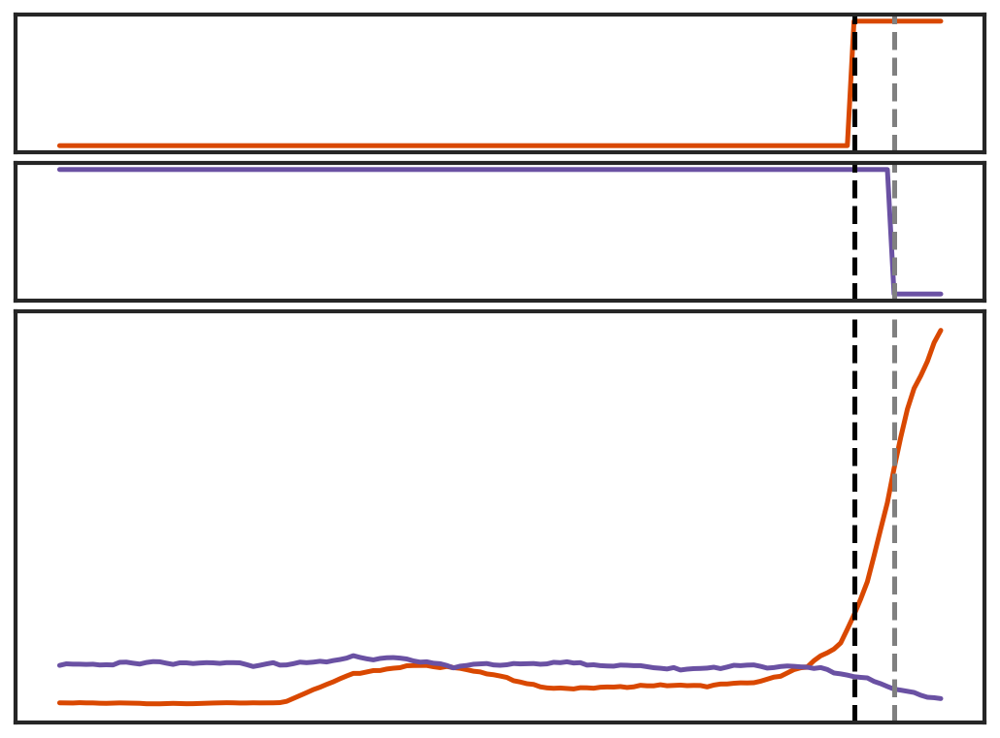

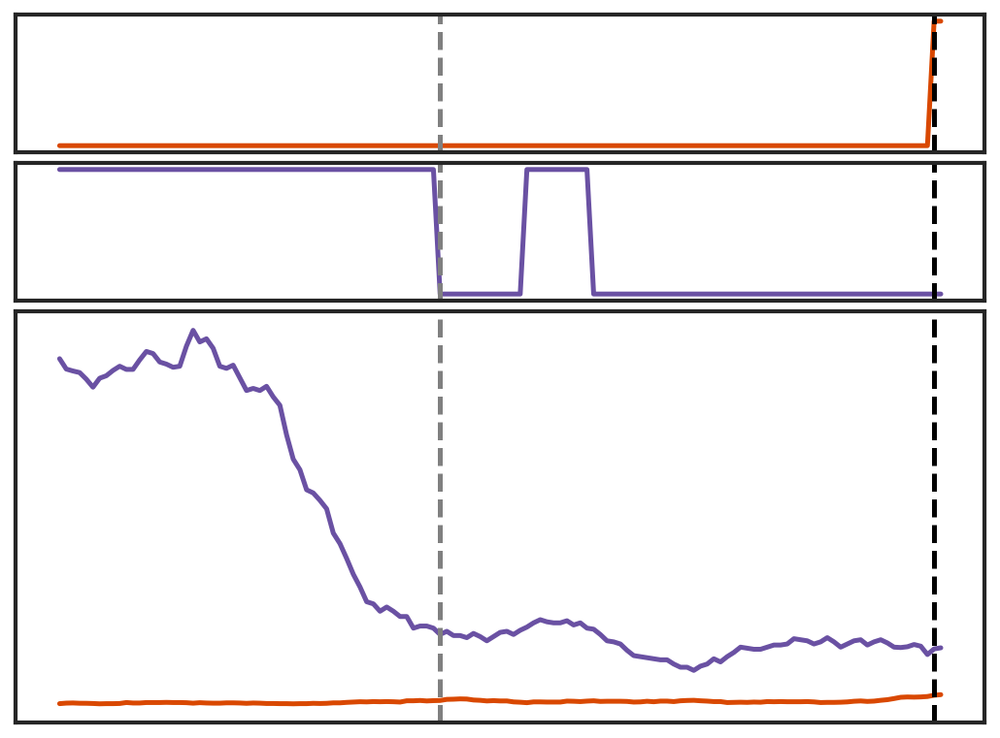

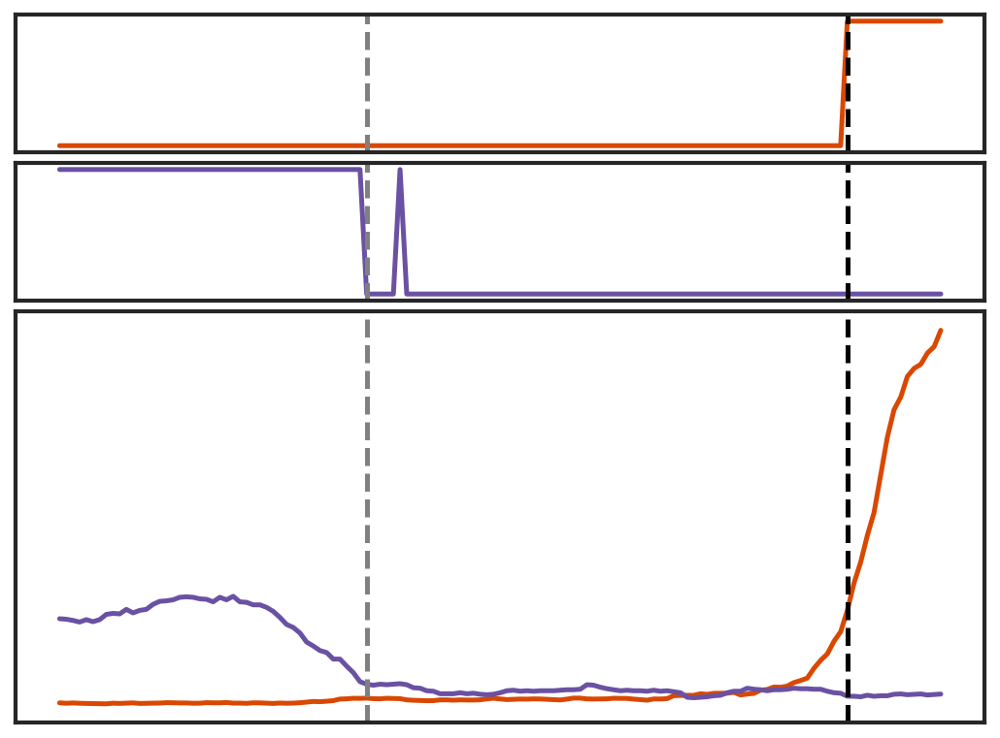

In [871]:
genes = list(d4.head(20).index)
lin = 'mes1'

for gene in genes:
    fig, ax = plt.subplots(3,1,figsize = (8,6), height_ratios=[0.2,0.2,0.6],gridspec_kw = {'wspace':0, 'hspace':0.05})
    
    sns.lineplot(data = ct_normalised[(ct_normalised['lin'] == lin) & (ct_normalised.index == gene)],
                 x = 'step',
                 y = 'sm_short_state_dyn',
                 hue = 'layer', hue_order = ['RNA'],ax=ax[0],
                 palette = [Orange])
    sns.lineplot(data = ct_normalised[(ct_normalised['lin'] == lin) & (ct_normalised.index == gene)],
                 x = 'step',
                 y = 'sm_short_state_dyn',ax=ax[1],
                 hue = 'layer', hue_order = ['K27'],
                 palette = [Purple])
    
    sns.lineplot(data = ct_normalised[(ct_normalised['lin'] == lin) & (ct_normalised.index == gene)],
                 x = 'step',ax=ax[2],
                 y = 'p_98',
                 hue = 'layer', hue_order = ['RNA','K27'],
                 palette = [Orange,Purple])
    
    for num in range(3):
        ax[num].axvline(d4.loc[gene]['rna'], c = 'black', linestyle = 'dashed',)
        ax[num].axvline(d4.loc[gene]['k27'], c = 'grey', linestyle = 'dashed',)
        ax[num].legend([],frameon=False)
        ax[num].set_xticks([])
        ax[num].set_xlabel('')
        ax[num].set_yticks([])
        ax[num].set_ylabel('')
    plt.show()

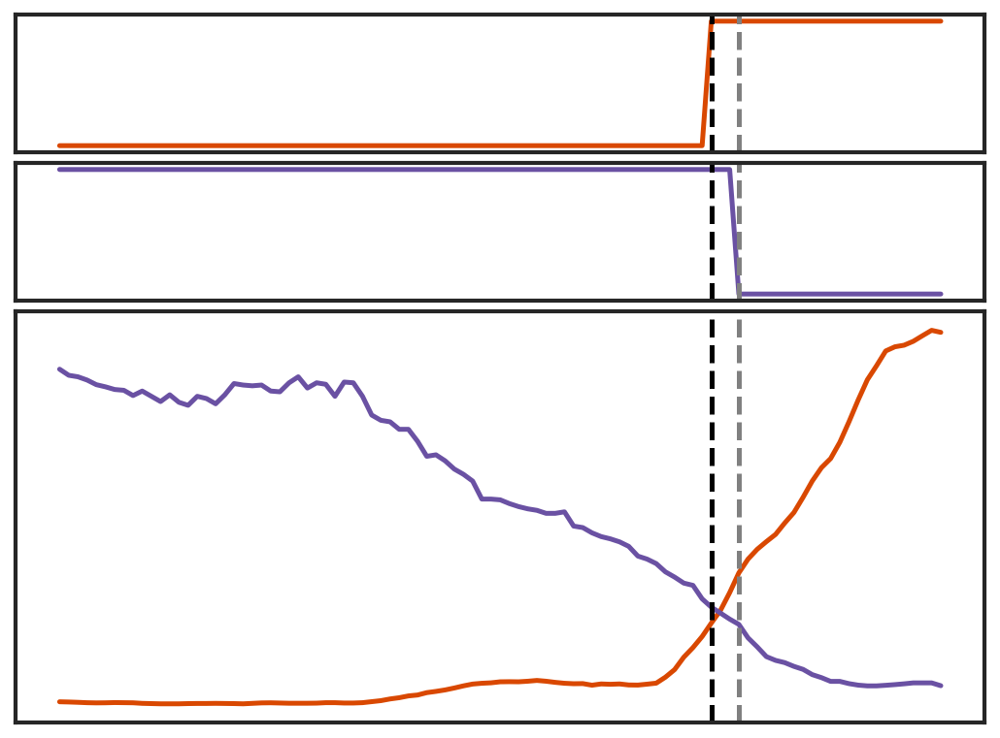

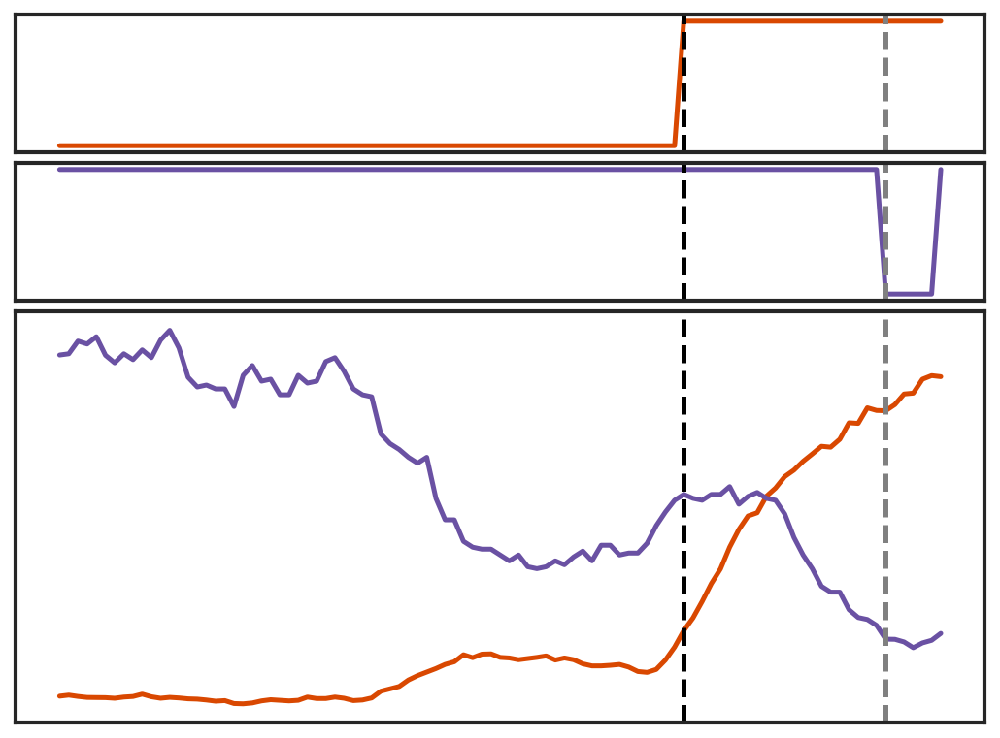

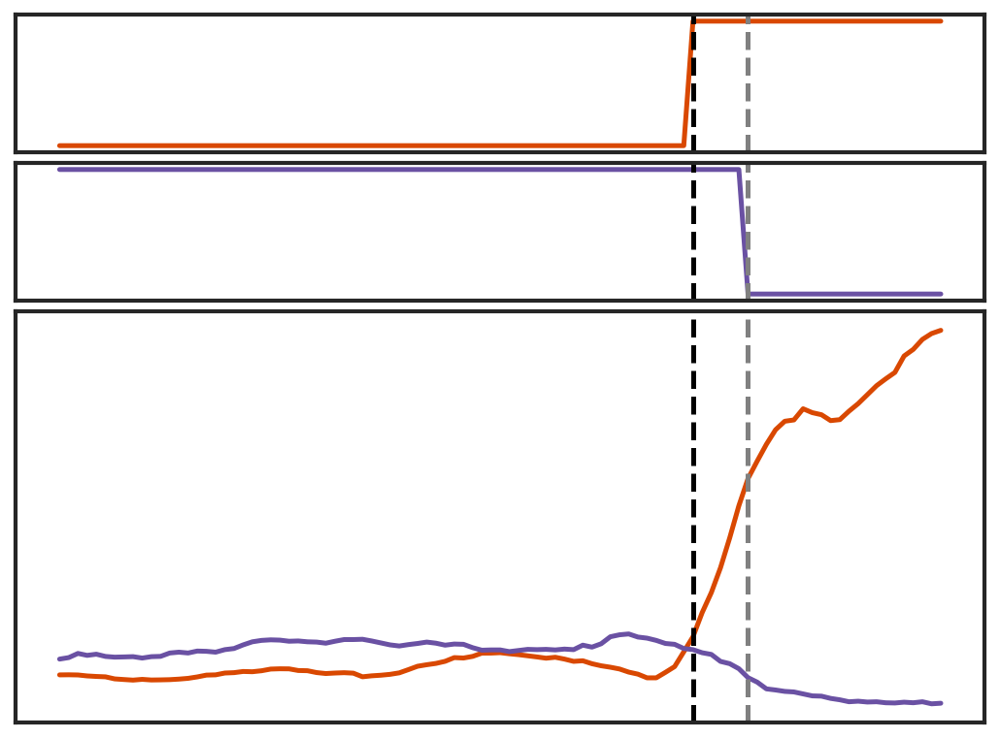

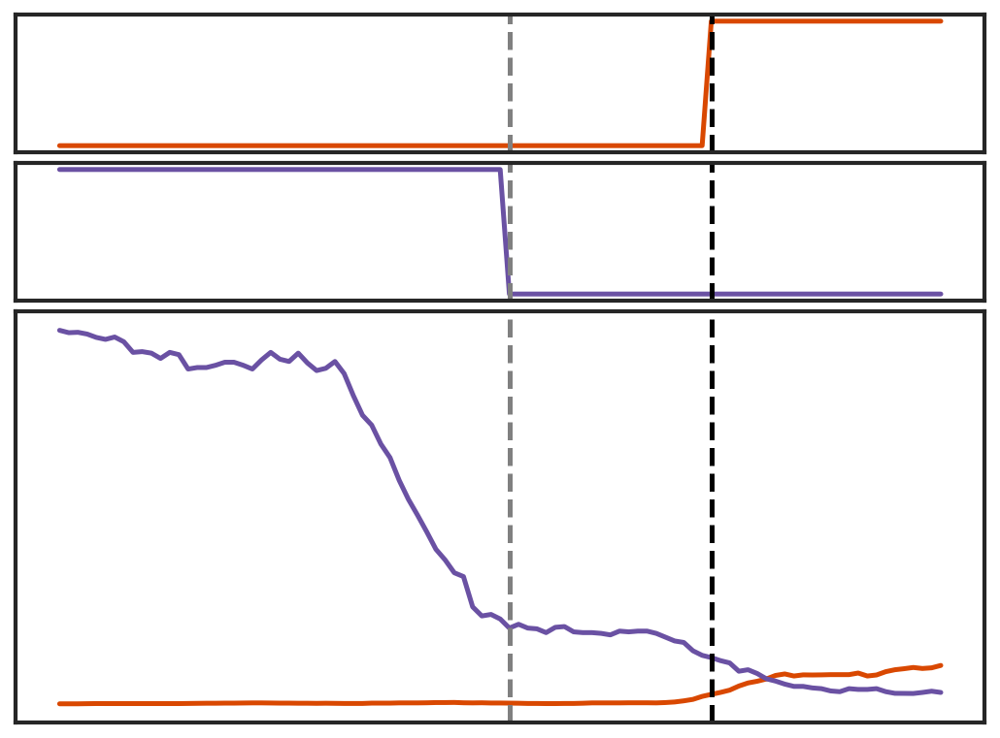

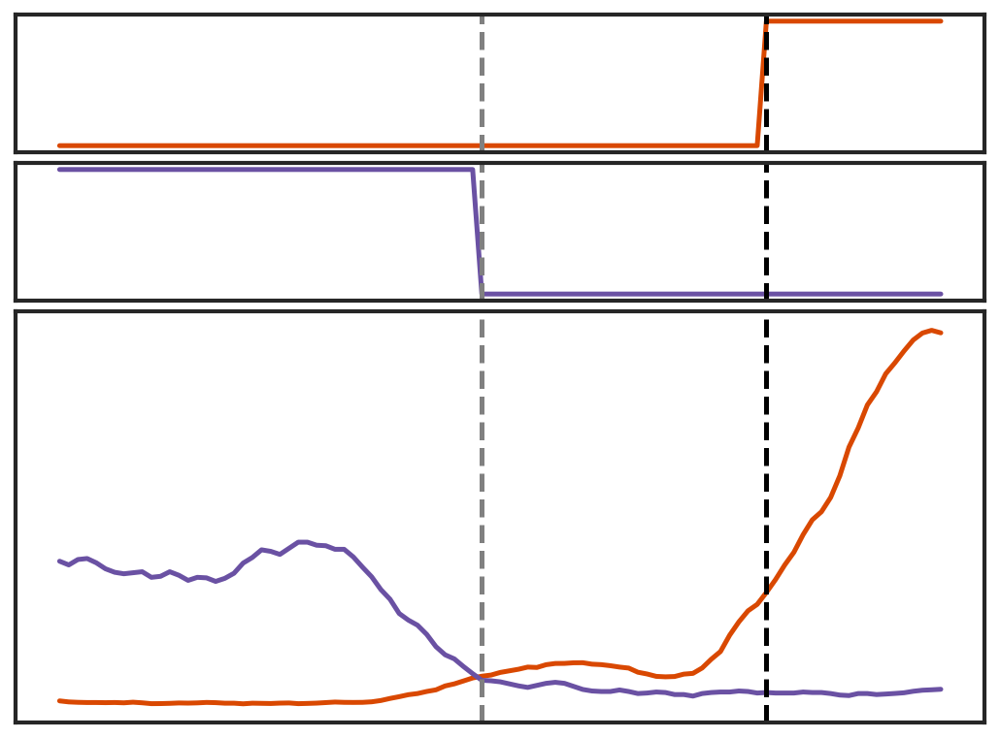

...

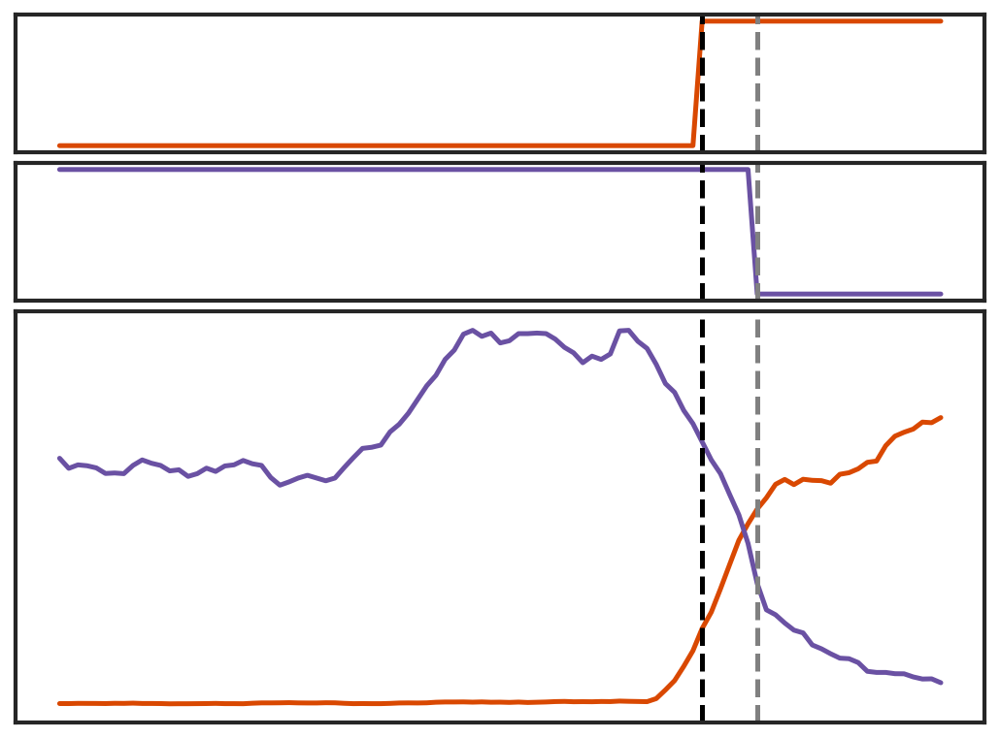

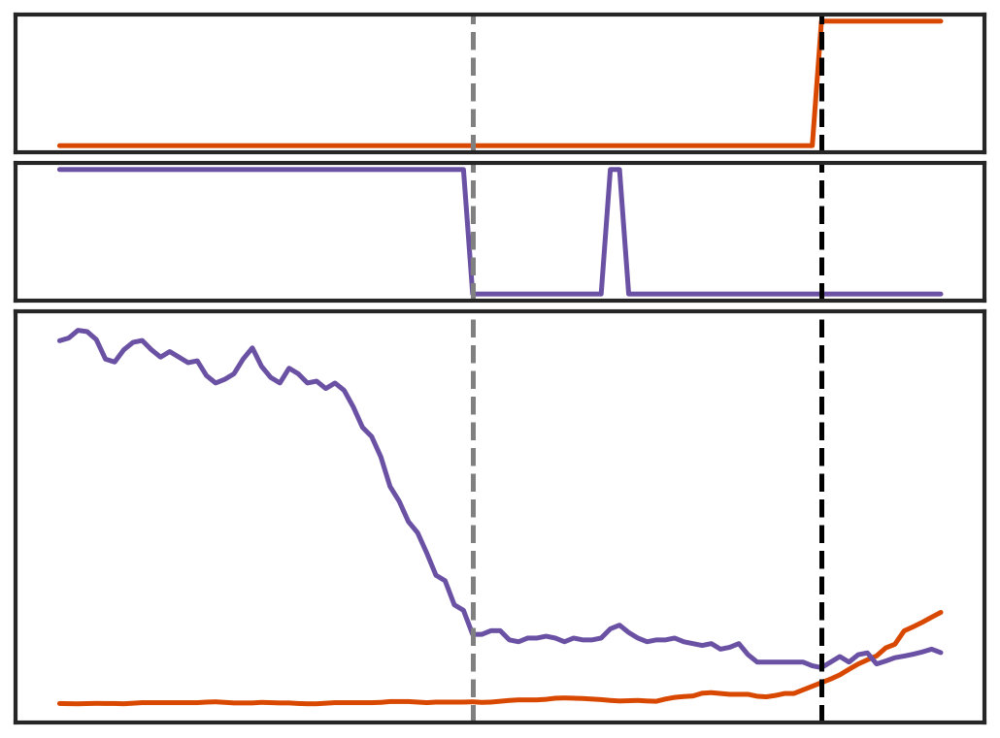

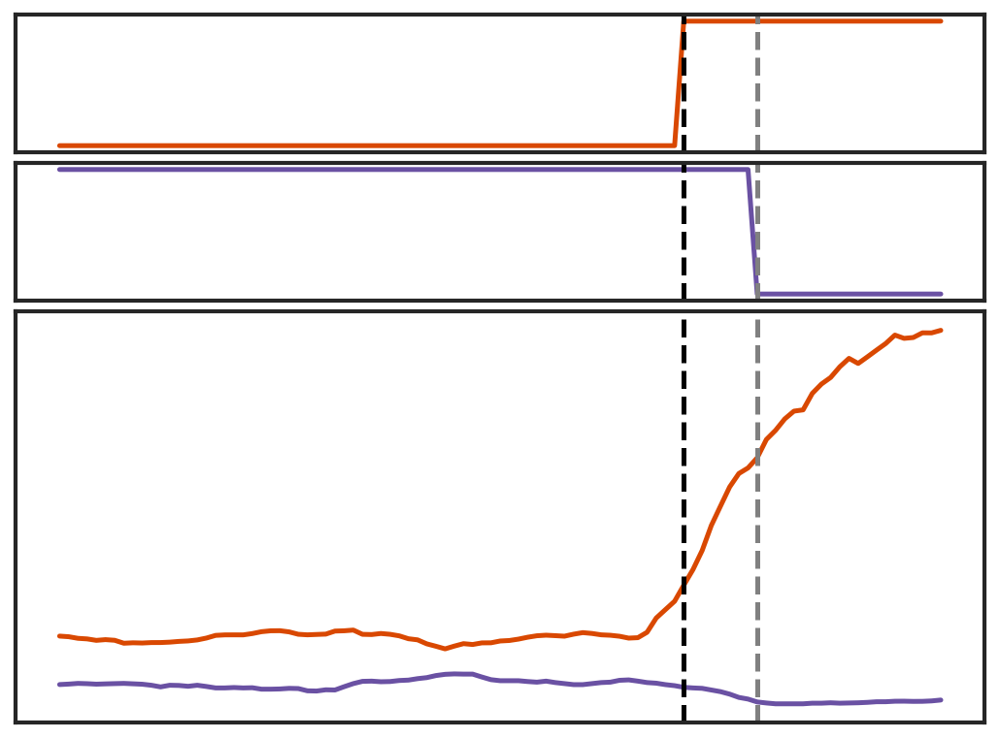

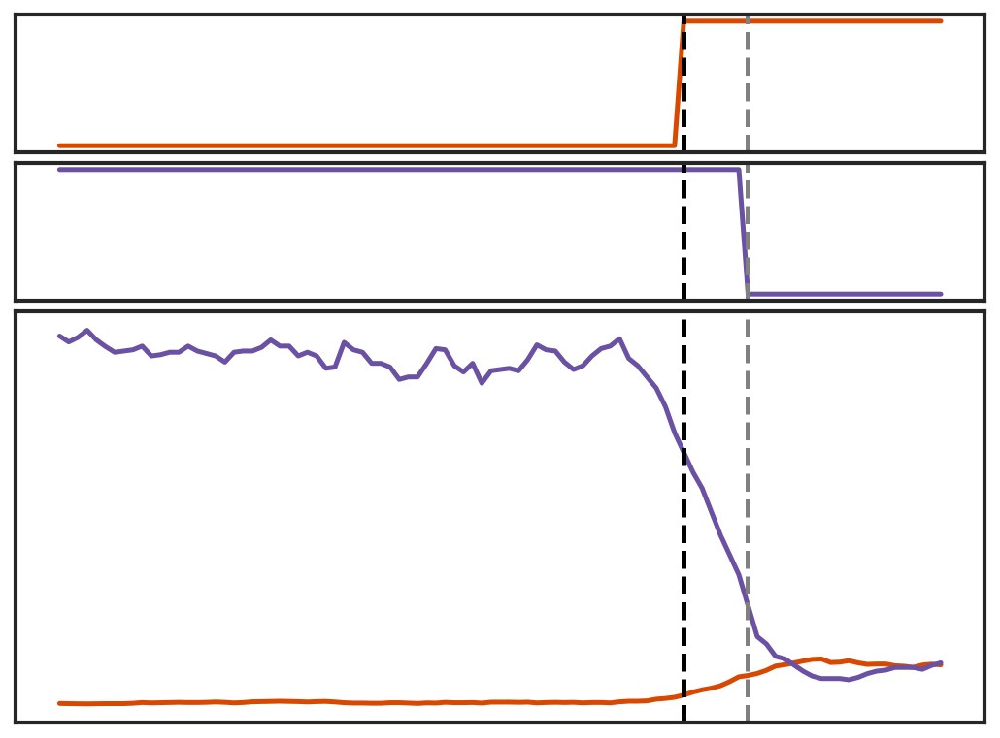

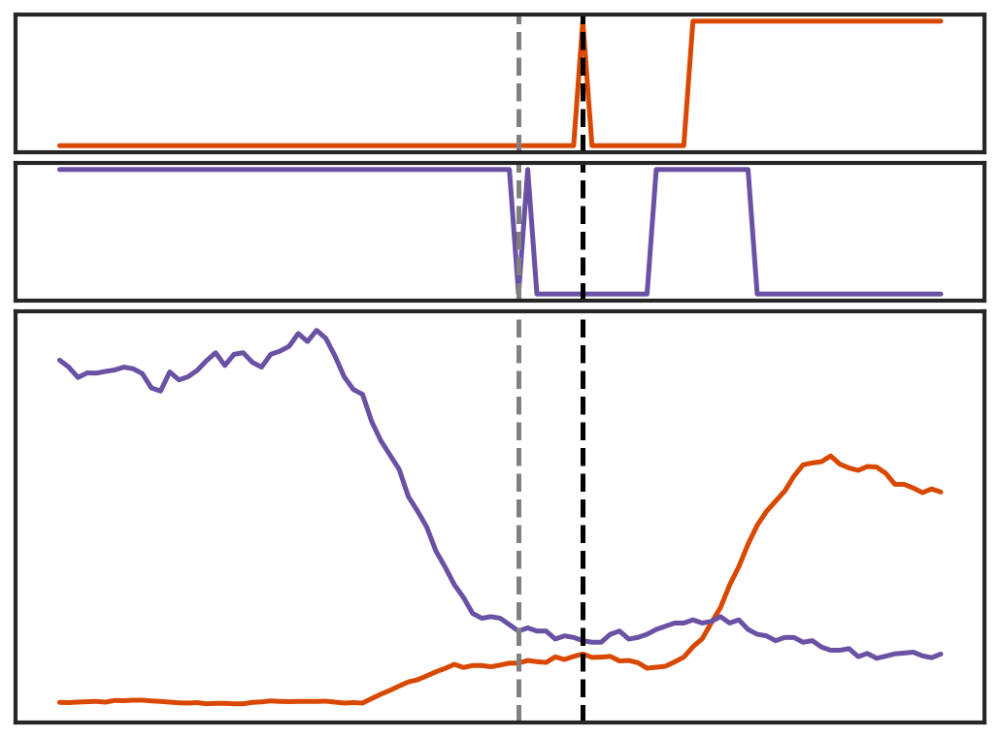

In [872]:
genes = list(d7.head(20).index)
lin = 'endo1'

for gene in genes:
    fig, ax = plt.subplots(3,1,figsize = (8,6), height_ratios=[0.2,0.2,0.6],gridspec_kw = {'wspace':0, 'hspace':0.05})
    
    sns.lineplot(data = ct_normalised[(ct_normalised['lin'] == lin) & (ct_normalised.index == gene)],
                 x = 'step',
                 y = 'sm_short_state_dyn',
                 hue = 'layer', hue_order = ['RNA'],ax=ax[0],
                 palette = [Orange])
    sns.lineplot(data = ct_normalised[(ct_normalised['lin'] == lin) & (ct_normalised.index == gene)],
                 x = 'step',
                 y = 'sm_short_state_dyn',ax=ax[1],
                 hue = 'layer', hue_order = ['K27'],
                 palette = [Purple])
    
    sns.lineplot(data = ct_normalised[(ct_normalised['lin'] == lin) & (ct_normalised.index == gene)],
                 x = 'step',ax=ax[2],
                 y = 'p_98',
                 hue = 'layer', hue_order = ['RNA','K27'],
                 palette = [Orange,Purple])
    
    for num in range(3):
        ax[num].axvline(d7.loc[gene]['rna'], c = 'black', linestyle = 'dashed',)
        ax[num].axvline(d7.loc[gene]['k27'], c = 'grey', linestyle = 'dashed',)
        ax[num].legend([],frameon=False)
        ax[num].set_xticks([])
        ax[num].set_xlabel('')
        ax[num].set_yticks([])
        ax[num].set_ylabel('')
    plt.show()

In [828]:
ct_normalised.head(2)

,step,layer,counts,lin,sm_short,counts_log2,sm_short_log2,sm_short_state_fix,sm_short_state_dyn,p_99,p_98,p_95,p98_log2,p98_log10,step_id,RT,lin_layer
gene,,,,,,,,,,,,,,,,,
Xkr4,1,RNA,0.25,ect1,0.284,-1.943416,-1.766112,1.0,0.0,0.047819,0.069934,0.125110,0.097521,0.029357,1:ect1,mESCs,ect1_RNA
Rp1,1,RNA,0.23,ect1,0.278,-2.058894,-1.795859,1.0,1.0,0.046809,0.068456,0.122467,0.095528,0.028757,1:ect1,mESCs,ect1_RNA


In [854]:
d7.head(20)

,rna,k27,diff,lin
gene,,,,
Slc39a8,11,78,67,endo1
Car4,69,70,1,endo1
Krt8,57,66,9,endo1
Tnfrsf12a,80,77,-3,endo1
Lgals3bp,49,47,-2,endo1
Cltrn,73,44,-29,endo1
Trp53inp2,8,84,76,endo1
Lrrn4,38,48,10,endo1
Selenop,51,42,-9,endo1


counts


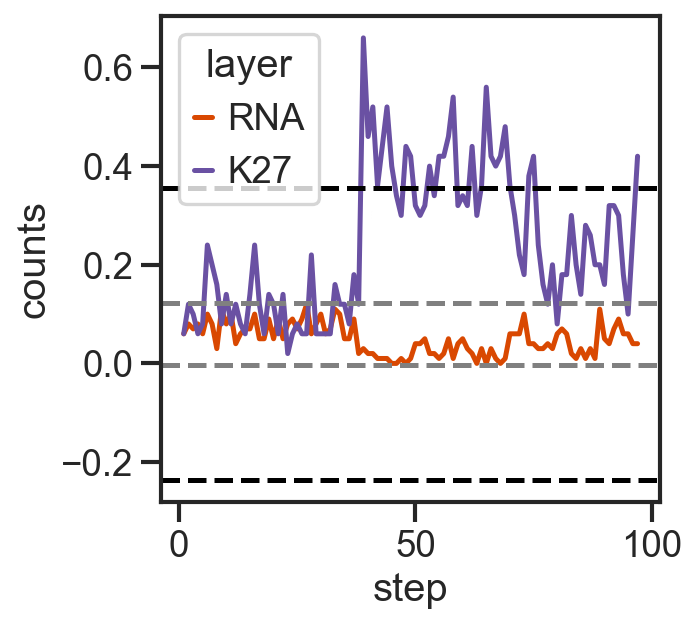

sm_short


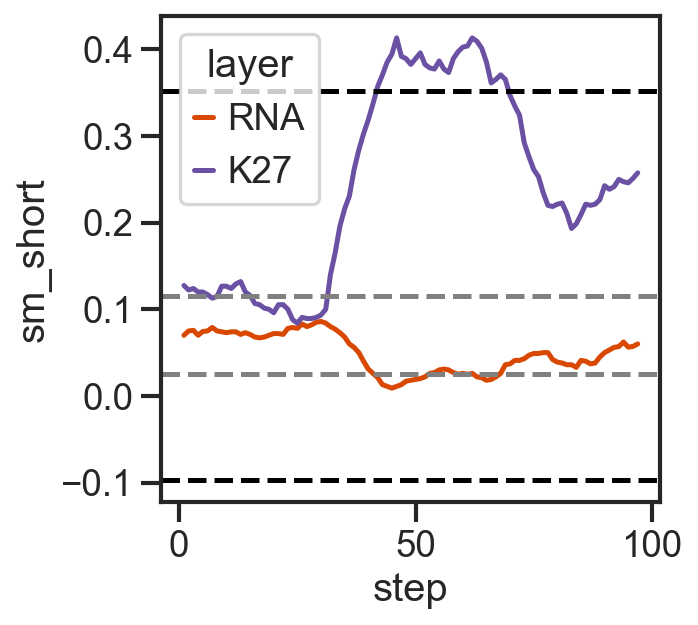

counts_log2


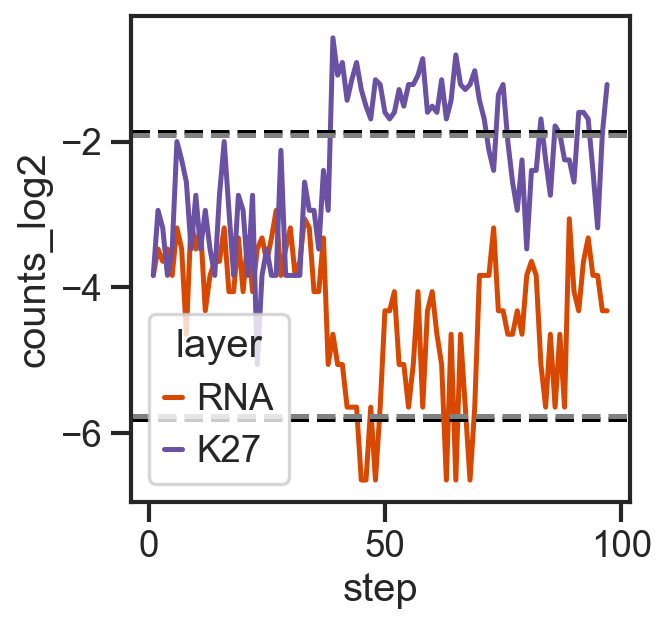

sm_short_log2


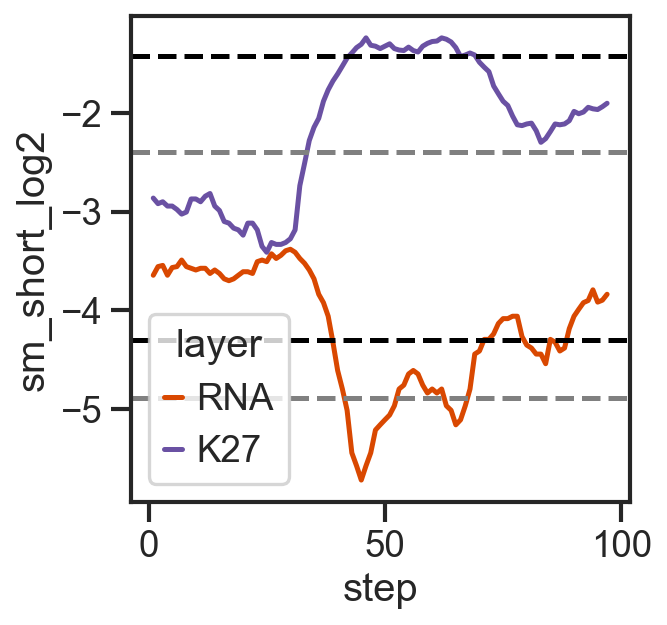

p_99


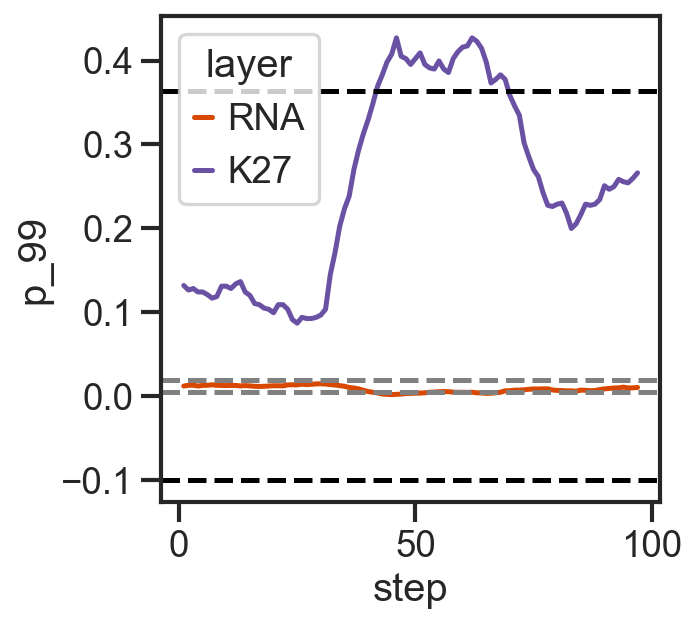

p_98


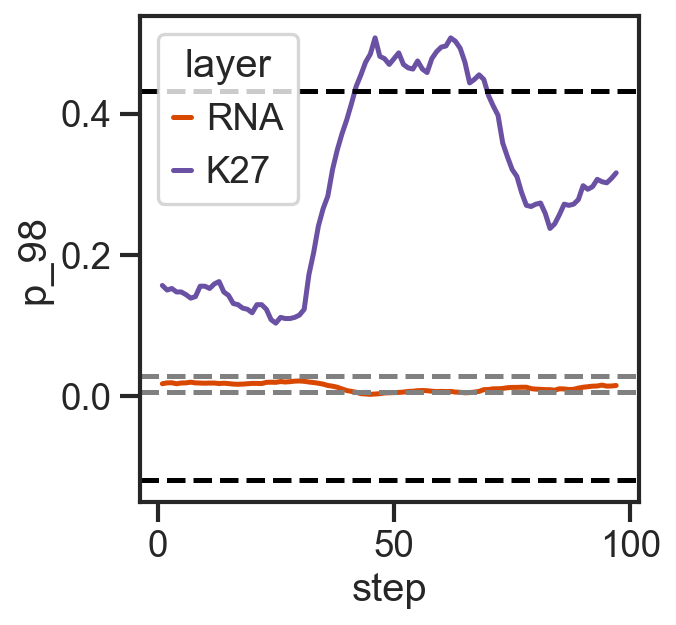

p_95


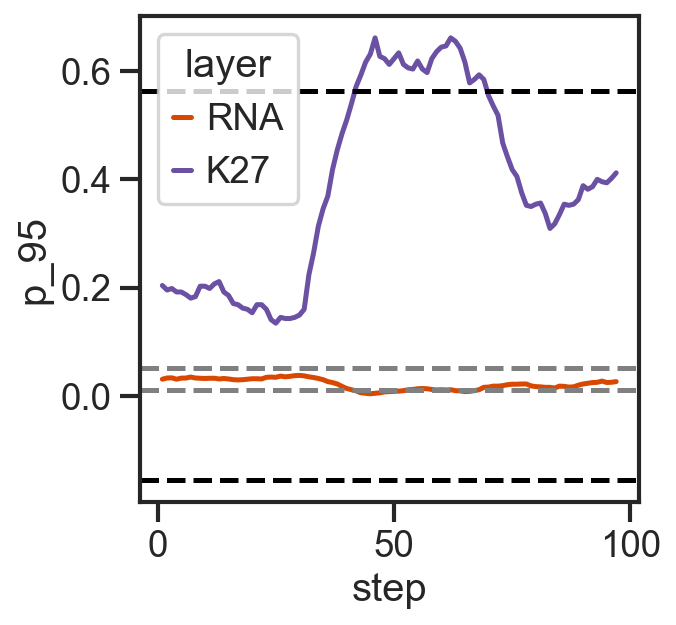

p98_log2


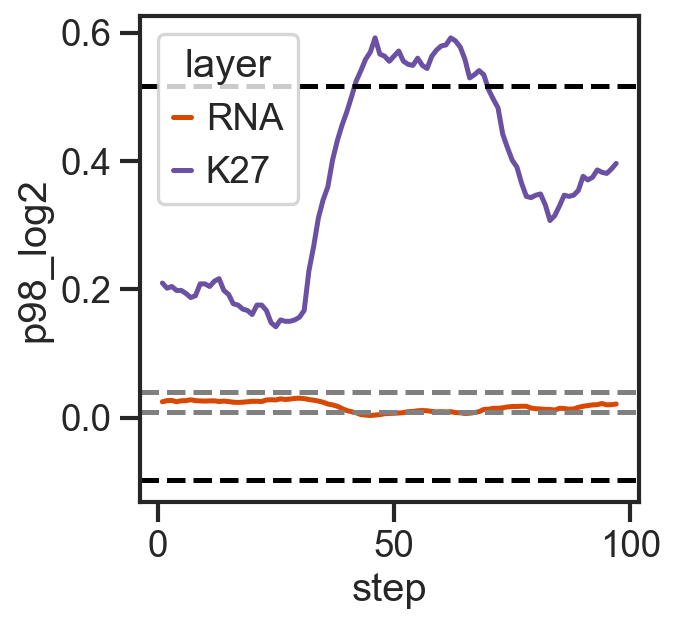

p98_log10


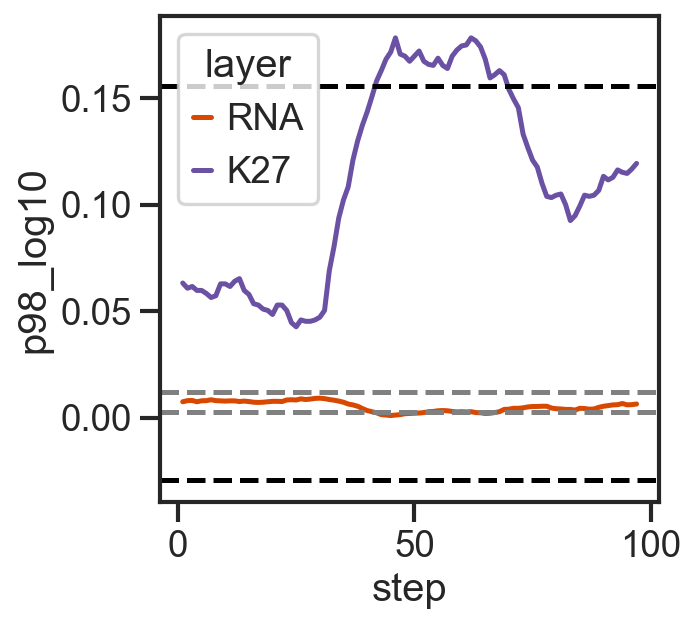

In [855]:
gene = 'Hbegf'#'Tnfrsf12a'#'Habp2'
lin = 'endo1'

vals = ['counts','sm_short','counts_log2','sm_short_log2','p_99','p_98','p_95','p98_log2','p98_log10']

for x in vals:
    print(x)
    testgene = ct_normalised[(ct_normalised['lin'] == lin) & (ct_normalised.index == gene)]
    
    sns.lineplot(data = testgene,
                 x = 'step',
                 y = x,
                 hue = 'layer', hue_order = ['RNA','K27'],
                 palette = [Orange,Purple])
    plt.axhline(list(testgene[(testgene['layer'] == 'K27') & (testgene['step'] == 1)][x]+np.std(testgene[testgene['layer'] == 'K27'][x])*2),
               c = 'black', linestyle = 'dashed')
    plt.axhline(list(testgene[(testgene['layer'] == 'K27') & (testgene['step'] == 1)][x]-np.std(testgene[testgene['layer'] == 'K27'][x])*2),
                c = 'black', linestyle = 'dashed')
    plt.axhline(list(testgene[(testgene['layer'] == 'RNA') & (testgene['step'] == 1)][x]+np.std(testgene[testgene['layer'] == 'RNA'][x])*2),
               c = 'grey', linestyle = 'dashed')
    plt.axhline(list(testgene[(testgene['layer'] == 'RNA') & (testgene['step'] == 1)][x]-np.std(testgene[testgene['layer'] == 'RNA'][x])*2),
                c = 'grey', linestyle = 'dashed')
    plt.show()


In [830]:
testgene = ct_normalised[(ct_normalised['lin'] == lin) & (ct_normalised.index == gene)]

In [835]:
import statistics

In [845]:
testgene[(testgene['layer'] == 'K27') & (testgene['step'] == 1)]['sm_short']+np.std(testgene[testgene['layer'] == 'K27']['sm_short'])*2
testgene[(testgene['layer'] == 'K27') & (testgene['step'] == 1)]['sm_short']-np.std(testgene[testgene['layer'] == 'K27']['sm_short'])*2

gene
Habp2    0.182954
Name: sm_short, dtype: float64

In [842]:
testgene[(testgene['layer'] == 'K27') & (testgene['step'] == 1)]

,step,layer,counts,lin,sm_short,counts_log2,sm_short_log2,sm_short_state_fix,sm_short_state_dyn,p_99,p_98,p_95,p98_log2,p98_log10,step_id,RT,lin_layer
gene,,,,,,,,,,,,,,,,,
Habp2,1,K27,0.6,endo1,0.5225,-0.713119,-0.909147,1.0,1.0,0.539773,0.641367,0.835554,0.714898,0.215206,1:endo1,mESCs,endo1_K27


In [874]:
adata.obs.head(4)

,batch,day,replicates,mark,day_rep,dataset,hour,celltype,celltype_general,lineage,...,n_genes,S_score,G2M_score,phase,enrichment,coverage,QC,pseudotime,pseudotime2,diffx_all
index,,,,,,,,,,,,,,,,,,,,,
PZ-MB-TChIC-Gastd5-rep2-H3K27me3-1_341,PZ-MB-TChIC-Gastd5-rep2-H3K27me3-1,Gastd5,rep2,H3K27me3,Gastd5_rep2,old,120h,Endothelium,Haemogenic,Mesoderm,...,3597,-0.025686,-0.040124,G1,78.808261,38.540,good,56.601980,51.219790,Mesoderm
PZ-MB-TChIC-Gastd5-rep2-H3K27me3-1_310,PZ-MB-TChIC-Gastd5-rep2-H3K27me3-1,Gastd5,rep2,H3K27me3,Gastd5_rep2,old,120h,Neural Progenitors,Neural Progenitors,Ectoderm,...,5887,0.113965,0.081538,S,70.389349,34.978,good,30.236847,14.116035,Ectoderm
PZ-MB-TChIC-Gastd5-rep2-H3K27me3-1_302,PZ-MB-TChIC-Gastd5-rep2-H3K27me3-1,Gastd5,rep2,H3K27me3,Gastd5_rep2,old,120h,NMPs,NMPs,Ectoderm,...,3649,-0.032971,-0.025892,G1,82.261681,47.160,good,30.302296,13.390260,Ectoderm
PZ-MB-TChIC-Gastd5-rep2-H3K27me3-1_5,PZ-MB-TChIC-Gastd5-rep2-H3K27me3-1,Gastd5,rep2,H3K27me3,Gastd5_rep2,old,120h,NMPs,NMPs,Ectoderm,...,4818,0.098372,0.055178,S,71.349690,40.068,good,29.653845,13.194938,Ectoderm


In [91]:
greens_r = sns.blend_palette(['black','#238b45', '#75c477', '#c8e9c1' ], as_cmap = True)
purples_r = sns.blend_palette(['black','#6a51a3', '#9e9bc8', '#dadaeb'], as_cmap = True)
oranges_r = sns.blend_palette(['black','#d94801', '#fd8e3d', '#fdd1a3'], as_cmap = True)

import scipy 

def plotline(count_table, lineage = 'ect1',genelist = ['Onecut2'], val = 'sm',xval = 'step', save = None,figsize = (4,4)):

    df = pd.pivot_table(count_table[count_table['lin'] == lineage][[val, 'layer',xval]], columns = 'gene', index = ['layer',xval],values = val)
    fig,ax=plt.subplots(figsize=(figsize))
    

    df_rna = df.loc['RNA']
    df_k4 = df.loc['K4']
    df_k27 = df.loc['K27']

    df_rna = df_rna[genelist]
    df_k4 = df_k4[genelist]
    df_k27 = df_k27[genelist]
    
    # order = scipy.cluster.hierarchy.leaves_list(scipy.cluster.hierarchy.linkage(df.T.fillna(0)))
    df_k271 = pd.DataFrame(df_k27.unstack()).rename(columns={0:'vals'})
    df_k271['mod'] = 'k27'
    df_k41 = pd.DataFrame(df_k4.unstack()).rename(columns={0:'vals'})
    df_k41['mod'] = 'k4'
    df_rna1 = pd.DataFrame(df_rna.unstack()).rename(columns={0:'vals'})
    df_rna1['mod'] = 'rna'
        
    sns.lineplot(data = pd.concat([df_k271, df_k41, df_rna1]), ax=ax,
                    x = xval,
                    y = 'vals',
                    hue = 'mod',
                     hue_order = ['rna','k4','k27'],
                    palette = [Orange, Green, Purple])
    

    ax.legend([],frameon=False)
    
    ax.set_xticks([])
    ax.set_xlabel('')
    ax.set_ylabel('')   
    
    #ax[0].set_xlim(df_k271.index.get_level_values(xval).unique()[[0,-1]])
    ax.set_ylim([0,1])
    ax.set_yticks([0,0.2,0.4,0.6,0.8,1.0])
    if save != None:
        plt.savefig(save , bbox_inches='tight')
    plt.show()
    plt.close()

In [ ]:
plotline(to_plot1, lineage = 'endo1', genelist = to_plot1.index.unique(), val = 'p_98', xval = 'RT', save = 'figs/20250415_endogenes_endo1_RT.png')
plotline(to_plot2, lineage = 'mes1', genelist = to_plot2.index.unique(), val = 'p_98', xval = 'RT', save = 'figs/20250415_mesogenes_mes1_RT.png')
plotline(to_plot2, lineage = 'mes2', genelist = to_plot2.index.unique(), val = 'p_98', xval = 'RT', save = 'figs/20250415_mesogenes_mes2_RT.png')
plotline(to_plot2, lineage = 'mes3', genelist = to_plot2.index.unique(), val = 'p_98', xval = 'RT', save = 'figs/20250415_mesogenes_mes3_RT.png')
plotline(to_plot3, lineage = 'ect1', genelist = to_plot3.index.unique(), val = 'p_98', xval = 'RT', save = 'figs/20250415_ectogenes_ect1_RT.png')
plotline(to_plot3, lineage = 'ect2', genelist = to_plot3.index.unique(), val = 'p_98', xval = 'RT', save = 'figs/20250415_ectogenes_ect2_RT.png')
plotline(to_plot3, lineage = 'ect3', genelist = to_plot3.index.unique(), val = 'p_98', xval = 'RT', save = 'figs/20250415_ectogenes_ect3_RT.png')

plotline(to_plot4, lineage = 'mes1', genelist = to_plot4.index.unique(), val = 'p_98', xval = 'RT', save = 'figs/20250415_plurigenes_mes1_RT.png')
plotline(to_plot4, lineage = 'mes2', genelist = to_plot4.index.unique(), val = 'p_98', xval = 'RT', save = 'figs/20250415_plurigenes_mes2_RT.png')
plotline(to_plot4, lineage = 'mes3', genelist = to_plot4.index.unique(), val = 'p_98', xval = 'RT', save = 'figs/20250415_plurigenes_mes3_RT.png')
plotline(to_plot4, lineage = 'ect1', genelist = to_plot4.index.unique(), val = 'p_98', xval = 'RT', save = 'figs/20250415_plurigenes_ect1_RT.png')
plotline(to_plot4, lineage = 'ect2', genelist = to_plot4.index.unique(), val = 'p_98', xval = 'RT', save = 'figs/20250415_plurigenes_ect2_RT.png')
plotline(to_plot4, lineage = 'ect3', genelist = to_plot4.index.unique(), val = 'p_98', xval = 'RT', save = 'figs/20250415_plurigenes_ect3_RT.png')
plotline(to_plot4, lineage = 'endo1', genelist = to_plot4.index.unique(), val = 'p_98', xval = 'RT', save = 'figs/20250415_plurigenes_endo1_RT.png')

In [92]:
def plotChanges(df,lin,keep='first',save = None):
    df['dup'] = df['lin_layer'] + '_' + df['gene']
    df_unique = df[~df['dup'].duplicated(keep = keep)]
    fig,ax = plt.subplots(3,1, figsize = (6,4),gridspec_kw = {'wspace':0, 'hspace':0.05})
    sns.histplot(df_unique[(df_unique['lin'] == lin) & (df_unique['layer'] == 'RNA')]['step'],
                ax=ax[0], color= Orange, bins=40)
    sns.histplot(df_unique[(df_unique['lin'] == lin) & (df_unique['layer'] == 'K4')]['step'],
                ax=ax[1], color= Green,bins = 40)
    sns.histplot(df_unique[(df_unique['lin'] == lin) & (df_unique['layer'] == 'K27')]['step'],
                ax=ax[2], color= Purple, bins = 40)
    for x in range(3):
        ax[x].set_xlim([0,dict1[lin+'_RNA']+5])
        ax[x].set_xticks([])
        ax[x].set_xlabel('')
        ax[x].set_yticks([])
        ax[x].set_ylabel('')
        ax[x].set_ylim([0,55])

    if save != None:
        plt.savefig(save,bbox_inches='tight')
    plt.show()



In [ ]:
plotChanges(ect_changes,'ect1',save = 'figs/20250306_histplot_changes_ect1.png')
plotChanges(ect_changes,'ect2',save = 'figs/20250306_histplot_changes_ect2.png')
plotChanges(ect_changes,'ect3',save = 'figs/20250306_histplot_changes_ect3.png')
plotChanges(mes_changes,'mes1',save = 'figs/20250306_histplot_changes_mes1.png')
plotChanges(mes_changes,'mes2',save = 'figs/20250306_histplot_changes_mes2.png')
plotChanges(mes_changes,'mes3',save = 'figs/20250306_histplot_changes_mes3.png')
plotChanges(end_changes,'endo1',save = 'figs/20250306_histplot_changes_end1.png')

In [98]:
endo

,Gene,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj,p_log10
9537,Plekhg5,423.352313,2.001138,0.070436,28.410670,1.492867e-177,2.435996e-176,175.613323
3703,Ebf4,644.833193,2.005437,0.087547,22.907072,3.950213e-116,3.823553e-115,114.417533
10665,Rnf152,787.358236,2.008213,0.106992,18.769815,1.333501e-78,8.629936e-78,77.063992
13803,Wnk3,1700.817282,2.008996,0.071152,28.235349,2.153972e-175,3.444929e-174,173.462820
5487,Gm39526,129.305350,2.009764,0.113831,17.655696,9.199233e-70,5.344703e-69,68.272076
...,...,...,...,...,...,...,...,...
8466,Nepn,334.052473,7.218550,0.292978,24.638511,4.886813e-134,5.558078e-133,132.255075
1122,Apoa4,56.999561,7.378861,0.603562,12.225515,2.271380e-34,7.691586e-34,33.113984
6841,Kcnk16,299.490990,7.828282,0.318672,24.565340,2.965610e-133,3.354543e-132,131.474367
1121,Apoa1,469.053213,8.042573,0.267185,30.101129,4.683254e-199,8.778829e-198,197.056563


In [99]:
#d6[d6.index.isin(list(all_source_target_genes['mes_target']))]

ct_normalised.loc[ecto['Gene']]

KeyError: "['Gm5089', 'Gm19744', 'Gm49144', 'Gm33680', 'Gm48283', 'Hoxb5os', 'Gm45411', 'Gm26881', '2610307P16Rik', 'Gm26644', 'Gm715', 'Hoxd3os1', 'St8sia3os', 'C230034O21Rik', 'Celrr', 'A230057D06Rik', 'Gm37679', 'Gm14697', 'Gm5441', 'Gm37229', 'Gm26688', 'Gm14066', 'A330076H08Rik', 'Gm9934', 'Gm48747', 'Pard3bos1', 'AU022754', 'Gm47157', '2700069I18Rik', 'Gm29260', 'Gm14207', 'Gm9866', 'Gm20089', 'Gm12596', 'Grik2-1', 'Gm26862', 'Gm29478', 'Gm16701', 'Gm48742', 'Gm14664', '4930578G10Rik', 'Gm15893', 'G630064G18Rik', 'C130021I20Rik', 'Mapk10', 'Gm29684', 'B430319H21Rik', '1700108F19Rik', 'Gm15966', 'Syt11', 'Gm44593', 'Gm48898', 'Gm26801', 'Gm28511', 'Irx3os', 'Gm26936', '4930555G07Rik', 'Gm16141', 'Gm13481', '9130015G15Rik', 'Gm37335', '2810471M01Rik', '1500004A13Rik', 'Gm45350', 'Gm20501', '1700128E19Rik', 'Gm14204', 'Gm26911', 'Gm38534', '2810049E08Rik', 'Mir9-3hg', 'Neurog2', 'Mir124a-1hg', 'Gm30731', 'Hoxc10', 'Gm16010', 'C130026L21Rik', 'Gm20646', '5330434G04Rik', 'C130071C03Rik', 'Gm26871', 'Gm12239', 'Gm20083', 'Gm27199', 'Rmst', 'Gm26953', 'B020031H02Rik', 'Pantr1', 'Gm32061', 'Gm29508', 'Mir124-2hg', 'Gm46519', 'D930028M14Rik', 'Gm30340', 'Miat'] not in index"

In [97]:
xval = 'RT'
yval = 'p98_log10'
hue = 'lin'
hue_order = ['endo1',
            'mes1','mes2','mes3',
            'ect1','ect2','ect3']
palette = ['#FC6832',
          '#DF2179','#DF2179','#DF2179',
          '#3787C0','#3787C0','#3787C0']

mod = ['RNA', 'K4','K27']
plots = [endo,meso,ecto]

for num, item in enumerate(plots):
    print(num)
    to_plot = ct_normalised.loc[item['Gene']]
    fig,ax = plt.subplots(3,1, figsize = (3,6))
    for x in range(3):
        sns.lineplot(data = to_plot[to_plot['layer'] == mod[x]], linewidth = 2,
                     ax=ax[x],
                     x = xval, y = yval,hue = hue,hue_order = hue_order, palette = palette,errorbar = None,)
    
        ax[x].set_title(mod[x])

    for axes in ax:
        axes.set_xlabel('')
        axes.set_ylabel('')
        axes.set_ylim([0,0.31])
        axes.set_xticks([])
        axes.legend([],frameon=False) 
        axes.axvline('Gastd3',linestyle = 'dashed',c = 'black',linewidth = 1)
        axes.axvline('Gastd5',linestyle = 'dashed',c = 'black',linewidth = 1)
        axes.axvline('Gastd4',linestyle = 'dashed',c = 'grey',linewidth = 1)
        axes.axvline('Gastd6',linestyle = 'dashed',c = 'grey',linewidth = 1)
    plt.savefig('figs/lineplot_RT_' +str(num) + '.png', bbox_inches='tight')
    plt.show()

0


KeyError: "['Gm39526', 'Gm10575', 'Gm12992', 'Gm6999', 'Gm46210', 'Gm9939', 'Gm15927', 'A430093F15Rik', 'Gm50050', 'Gm49857', '5730419F03Rik', 'Serinc5', 'B130046B21Rik', '1110046J04Rik', 'Gm12296', 'Gm15283', 'Tbx3os1', 'Gm15477', 'Gm26826', 'Gm17501', 'A830012C17Rik', '9030404E10Rik', 'Gm41361', 'Gm30122', 'Gm28905', 'Gm10000', 'Gm13919', 'Gm49417', 'Gm10637', 'Gm4117', 'Panct2', 'Gm14133', 'Otx2os1', 'Gm13571', 'Gm29113', 'Gm29114', 'Gm15261', 'Gm47771', '4930512J16Rik', 'Gm27224', 'Gm33524', 'Gm16201', 'Gm12724', 'Lhx1os', '1700123J17Rik', '4632428C04Rik', 'Gm49732', 'Gm21847', 'Gm14582', 'Gm30613', 'Gm29530', 'Gm15675', 'Gm36723', 'Gm32442', 'Gm12576', 'Gm15418', 'Hnf4aos', 'Gm32815', 'Gm29895', 'Gpx2', 'Gm42722', 'Gm14858', 'Gm16083', 'Speer4cos', 'Gm30262', 'Gm12860', 'Gm41307', 'Gm40457', 'Gm37587', 'Gm28875', '1810007D17Rik', '1700110K17Rik', 'Hnf1aos1', '9030622O22Rik', 'Apoa4'] not in index"